In [ ]:
import os

print("Files in Colab:")
print(os.listdir("/content"))

path = "/content/archive.zip"

if os.path.exists(path):
    print("\nFile size:", os.path.getsize(path), "bytes")

    with open(path, "rb") as f:
        print("File signature:", f.read(10))
else:
    print("archive.zip not found!")

Files in Colab:
['.config', 'drive', '.ipynb_checkpoints', 'sample_data']
archive.zip not found!


In [ ]:
import zipfile

path = "/content/archive.zip"

with zipfile.ZipFile(path, 'r') as z:
    print("Number of files:", len(z.namelist()))
    print("ZIP integrity:", z.testzip())
    print("\nFirst 20 files:")
    for f in z.namelist()[:20]:
        print(f)

BadZipFile: File is not a zip file

In [ ]:
path = "/content/archive.zip"

with open(path, "rb") as f:
    f.seek(-22, 2)
    data = f.read(22)

print("Last 22 bytes:", data)
print("ZIP ending signature:", data[:4])


Last 22 bytes: b'4:V\xea*Ik\x8fS\xac\xfd\xf6\xfd3\x90\xad{\x9f\xbf\xe2\x87m'
ZIP ending signature: b'4:V\xea'


In [ ]:
!file /content/archive.zip
!unzip -t /content/archive.zip


/content/archive.zip: Zip archive data, at least v4.5 to extract, compression method=deflate
Archive:  /content/archive.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/archive.zip or
        /content/archive.zip.zip, and cannot find /content/archive.zip.ZIP, period.


In [ ]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive

drive.mount('/content/drive')

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU: []


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/archive.zip"

if os.path.exists(ZIP_PATH):
    size = os.path.getsize(ZIP_PATH) / (1024**3)
    print("Dataset found!")
    print("Dataset size:", round(size, 2), "GB")
else:
    print("Dataset not found. Check your Google Drive location.")

Dataset found!
Dataset size: 0.15 GB


In [ ]:
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    files = z.namelist()

    print("Total files:", len(files))
    print("\nFirst 25 entries:")

    for f in files[:25]:
        print(f)

Total files: 7200

First 25 entries:
Testing/glioma/Te-gl_1.jpg
Testing/glioma/Te-gl_10.jpg
Testing/glioma/Te-gl_100.jpg
Testing/glioma/Te-gl_101.jpg
Testing/glioma/Te-gl_102.jpg
Testing/glioma/Te-gl_103.jpg
Testing/glioma/Te-gl_104.jpg
Testing/glioma/Te-gl_105.jpg
Testing/glioma/Te-gl_106.jpg
Testing/glioma/Te-gl_107.jpg
Testing/glioma/Te-gl_108.jpg
Testing/glioma/Te-gl_109.jpg
Testing/glioma/Te-gl_11.jpg
Testing/glioma/Te-gl_110.jpg
Testing/glioma/Te-gl_111.jpg
Testing/glioma/Te-gl_112.jpg
Testing/glioma/Te-gl_113.jpg
Testing/glioma/Te-gl_114.jpg
Testing/glioma/Te-gl_115.jpg
Testing/glioma/Te-gl_116.jpg
Testing/glioma/Te-gl_117.jpg
Testing/glioma/Te-gl_118.jpg
Testing/glioma/Te-gl_119.jpg
Testing/glioma/Te-gl_12.jpg
Testing/glioma/Te-gl_120.jpg


In [ ]:
EXTRACT_PATH = "/content/medvision_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    bad_file = z.testzip()

    if bad_file:
        raise Exception(f"Corrupted file found: {bad_file}")

    z.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_PATH)

Dataset extracted successfully!
Location: /content/medvision_dataset


In [ ]:
for root, dirs, files in os.walk(EXTRACT_PATH):
    level = root.replace(EXTRACT_PATH, '').count(os.sep)

    if level <= 3:
        print("    " * level + os.path.basename(root) + "/")

medvision_dataset/
    Testing/
        pituitary/
        notumor/
        meningioma/
        glioma/
    Training/
        pituitary/
        notumor/
        meningioma/
        glioma/


In [ ]:
from collections import Counter

extensions = ('.jpg', '.jpeg', '.png', '.bmp')

for root, dirs, files in os.walk(EXTRACT_PATH):
    count = sum(f.lower().endswith(extensions) for f in files)

    if count > 0:
        print(f"{root}: {count} images")

/content/medvision_dataset/Testing/pituitary: 400 images
/content/medvision_dataset/Testing/notumor: 400 images
/content/medvision_dataset/Testing/meningioma: 400 images
/content/medvision_dataset/Testing/glioma: 400 images
/content/medvision_dataset/Training/pituitary: 1400 images
/content/medvision_dataset/Training/notumor: 1400 images
/content/medvision_dataset/Training/meningioma: 1400 images
/content/medvision_dataset/Training/glioma: 1400 images


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from pathlib import Path

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
DATASET_PATH = "/content/medvision_dataset"

TRAIN_DIR = os.path.join(DATASET_PATH, "Training")
TEST_DIR = os.path.join(DATASET_PATH, "Testing")

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 4
SEED = 42

In [ ]:
def collect_images(directory):
    paths = []
    labels = []

    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(directory, class_name)

        for file in os.listdir(class_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(class_dir, file))
                labels.append(label)

    return pd.DataFrame({"image": paths, "label": labels})

train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4480
Validation: 1120
Testing: 1600


In [ ]:
def collect_images(directory):
    paths = []
    labels = []

    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(directory, class_name)

        for file in os.listdir(class_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(class_dir, file))
                labels.append(label)

    return pd.DataFrame({"image": paths, "label": labels})

train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4480
Validation: 1120
Testing: 1600


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    return image, label

def create_dataset(df, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (df["image"].values, df["label"].values)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED
        )

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("All TensorFlow datasets created successfully!")

All TensorFlow datasets created successfully!


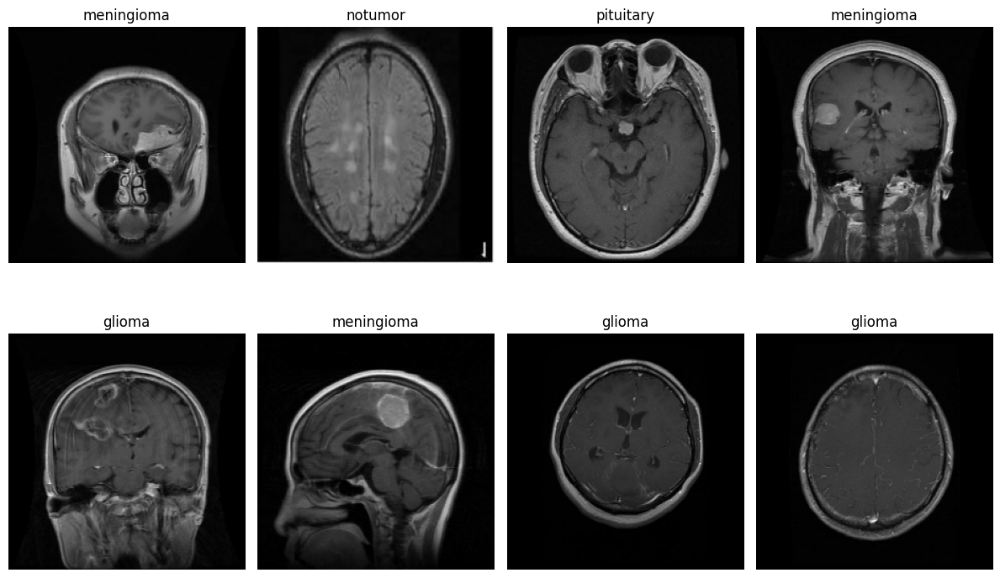

In [ ]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
])

In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully!")
print("Total layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!
Total layers: 238


In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.4)(x)

x = tf.keras.layers.Dense(256, activation="relu")(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs, name="MEDVISION_AI")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "MEDVISION_AI"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

os.makedirs("/content/medvision_models", exist_ok=True)

callbacks = [
    ModelCheckpoint(
        "/content/medvision_models/best_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6926 - loss: 0.7542
Epoch 1: val_loss improved from None to 0.76925, saving model to /content/medvision_models/best_model.keras

Epoch 1: finished saving model to /content/medvision_models/best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 517s 4s/step - accuracy: 0.7739 - loss: 0.5850 - val_accuracy: 0.7134 - val_loss: 0.7692 - learning_rate: 0.0010
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8367 - loss: 0.4311
Epoch 2: val_loss improved from 0.76925 to 0.52847, saving model to /content/medvision_models/best_model.keras

Epoch 2: finished saving model to /content/medvision_models/best_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 618s 4s/step - accuracy: 0.8440 - loss: 0.4152 - val_accuracy: 0.7920 - val_loss: 0.5285 - learning_rate: 0.0010
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8416 - loss: 0.4007
Epoch 3: val_loss improved from 0.52847 to 0.42314, saving model to /content/medvision

In [ ]:
model.save("/content/drive/MyDrive/MEDVISION_AI_stageA_best.keras")

print("Stage A best model saved successfully!")

Stage A best model saved successfully!


In [ ]:
print("GPU devices:", tf.config.list_physical_devices('GPU'))

!nvidia-smi

GPU devices: []
/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

!nvidia-smi

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Wed Nov  4 16:41:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |      

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_stageA_best.keras"
ZIP_PATH = "/content/drive/MyDrive/archive.zip"

print("Saved model exists:", os.path.exists(MODEL_PATH))
print("Dataset exists:", os.path.exists(ZIP_PATH))

Saved model exists: True
Dataset exists: True


In [ ]:
import zipfile

EXTRACT_PATH = "/content/medvision_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    bad_file = z.testzip()
    if bad_file:
        raise Exception(f"Corrupt archive: {bad_file}")
    z.extractall(EXTRACT_PATH)

print("Dataset restored!")

Dataset restored!


In [ ]:
import pandas as pd
import tensorflow as tf
import numpy as np
import os

from sklearn.model_selection import train_test_split

TRAIN_DIR = os.path.join(EXTRACT_PATH, "Training")
TEST_DIR = os.path.join(EXTRACT_PATH, "Testing")

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

def collect_images(directory):
    paths = []
    labels = []

    for label, class_name in enumerate(CLASS_NAMES):
        folder = os.path.join(directory, class_name)

        for file in sorted(os.listdir(folder)):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(folder, file))
                labels.append(label)

    return pd.DataFrame({"image": paths, "label": labels})

train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["label"]
)

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def create_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["image"].values, df["label"].values)
    )

    if training:
        ds = ds.shuffle(len(df), seed=SEED)

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return ds

train_ds = create_dataset(train_df, True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4480
Validation: 1120
Testing: 1600


In [ ]:
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_stageA_best.keras"
)

print("MEDVISION AI restored successfully!")
print("Model:", model.name)

MEDVISION AI restored successfully!
Model: MEDVISION_AI


In [ ]:
base_model = model.get_layer("efficientnetb0")

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
))

print("Fine-tuning configuration completed!")

Trainable parameters: 1812324
Fine-tuning configuration completed!


In [ ]:
fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_callbacks
)

Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8589 - loss: 0.3591
Epoch 1: val_loss improved from None to 0.47646, saving model to /content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 151ms/step - accuracy: 0.8650 - loss: 0.3503 - val_accuracy: 0.8277 - val_loss: 0.4765 - learning_rate: 1.0000e-05
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8723 - loss: 0.3289
Epoch 2: val_loss improved from 0.47646 to 0.44690, saving model to /content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - accuracy: 0.8699 - loss: 0.3323 - val_accuracy: 0.8357 - val_loss: 0.4469 - learning_rate: 1.0000e-05
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8843 - loss: 0.3193
Epoch 3: val_lo

In [ ]:
import tensorflow as tf
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Best MEDVISION AI model loaded!")
print("Model:", model.name)

Best MEDVISION AI model loaded!
Model: MEDVISION_AI


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions completed!")
print("Total test images:", len(y_true))
print("Predicted images:", len(y_pred))

50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step
Predictions completed!
Total test images: 1600
Predicted images: 1600


In [ ]:
print("MEDVISION AI - CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    digits=4
))

print("Overall Accuracy:", accuracy_score(y_true, y_pred))

MEDVISION AI - CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9350    0.5750    0.7121       400
  meningioma     0.7443    0.6550    0.6968       400
     notumor     0.8916    0.9875    0.9371       400
   pituitary     0.7120    0.9950    0.8300       400

    accuracy                         0.8031      1600
   macro avg     0.8207    0.8031    0.7940      1600
weighted avg     0.8207    0.8031    0.7940      1600

Overall Accuracy: 0.803125


<Figure size 900x700 with 0 Axes>

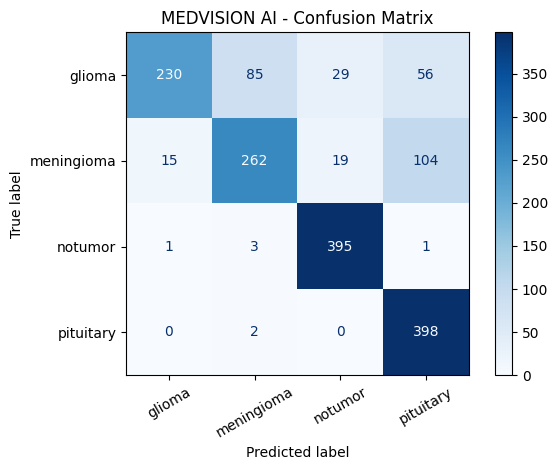

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MEDVISION AI - Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

print("CLASS-WISE SENSITIVITY AND SPECIFICITY\n")

for i, class_name in enumerate(CLASS_NAMES):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - (TP + FN + FP)

    sensitivity = TP / (TP + FN) if TP + FN else 0
    specificity = TN / (TN + FP) if TN + FP else 0

    print(f"\n{class_name.upper()}")
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")

CLASS-WISE SENSITIVITY AND SPECIFICITY


GLIOMA
Sensitivity: 0.5750
Specificity: 0.9867

MENINGIOMA
Sensitivity: 0.6550
Specificity: 0.9250

NOTUMOR
Sensitivity: 0.9875
Specificity: 0.9600

PITUITARY
Sensitivity: 0.9950
Specificity: 0.8658


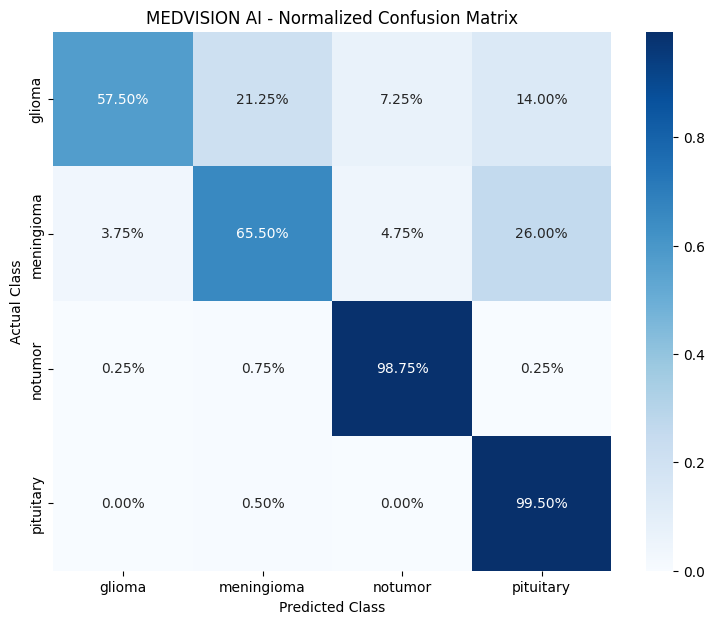

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MEDVISION AI - Normalized Confusion Matrix")
plt.show()

In [ ]:
errors = test_df.copy()

errors["actual"] = [CLASS_NAMES[i] for i in y_true]
errors["predicted"] = [CLASS_NAMES[i] for i in y_pred]
errors["confidence"] = np.max(y_prob, axis=1)

errors = errors[errors["actual"] != errors["predicted"]]

print("Total incorrect predictions:", len(errors))

print("\nMisclassification patterns:")

print(
    errors.groupby(["actual", "predicted"])
    .size()
    .sort_values(ascending=False)
)

Total incorrect predictions: 315

Misclassification patterns:
actual      predicted 
meningioma  pituitary     104
glioma      meningioma     85
            pituitary      56
            notumor        29
meningioma  notumor        19
            glioma         15
notumor     meningioma      3
pituitary   meningioma      2
notumor     glioma          1
            pituitary       1
dtype: int64


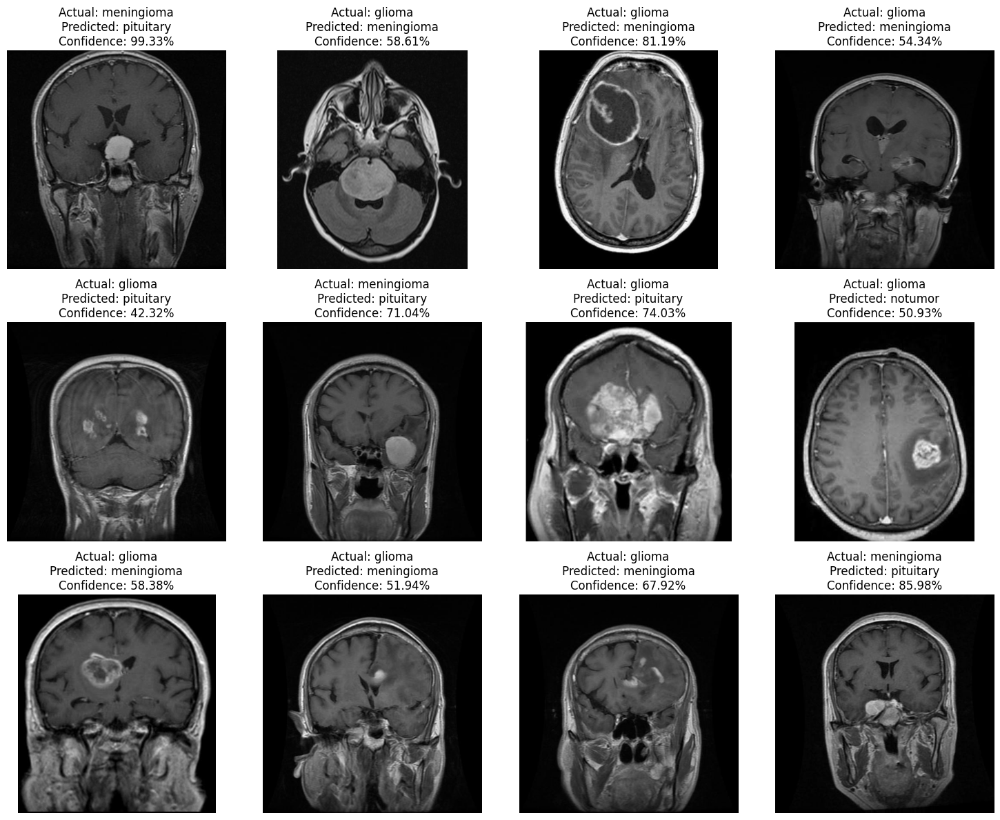

In [ ]:
import random
from PIL import Image

sample_errors = errors.sample(
    min(12, len(errors)),
    random_state=42
)

plt.figure(figsize=(15, 12))

for i, (_, row) in enumerate(sample_errors.iterrows()):
    img = Image.open(row["image"]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(
        f"Actual: {row['actual']}\n"
        f"Predicted: {row['predicted']}\n"
        f"Confidence: {row['confidence']:.2%}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

def make_gradcam(image, model, last_conv_layer="top_conv"):
    grad_model = tf.keras.models.Model(
        model.inputs,
        [
            model.get_layer("efficientnetb0").get_layer(last_conv_layer).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(image)
        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return heatmap.numpy(), int(class_index.numpy()), predictions.numpy()[0]

In [ ]:
error_samples = errors[
    (errors["actual"] == "meningioma") &
    (errors["predicted"] == "pituitary")
].sample(4, random_state=42)

print("Selected images:", len(error_samples))

Selected images: 4


In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

base_model = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        base_model.get_layer("top_conv").output,
        base_model.output
    ]
)

augmentation = model.get_layer("sequential")
pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")


def make_gradcam(image):

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        augmented = augmentation(image, training=False)

        conv_output, features = feature_model(
            augmented, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)

        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return (
        heatmap.numpy(),
        int(class_index.numpy()),
        predictions.numpy()[0]
    )

print("Grad-CAM initialized successfully!")

Grad-CAM initialized successfully!


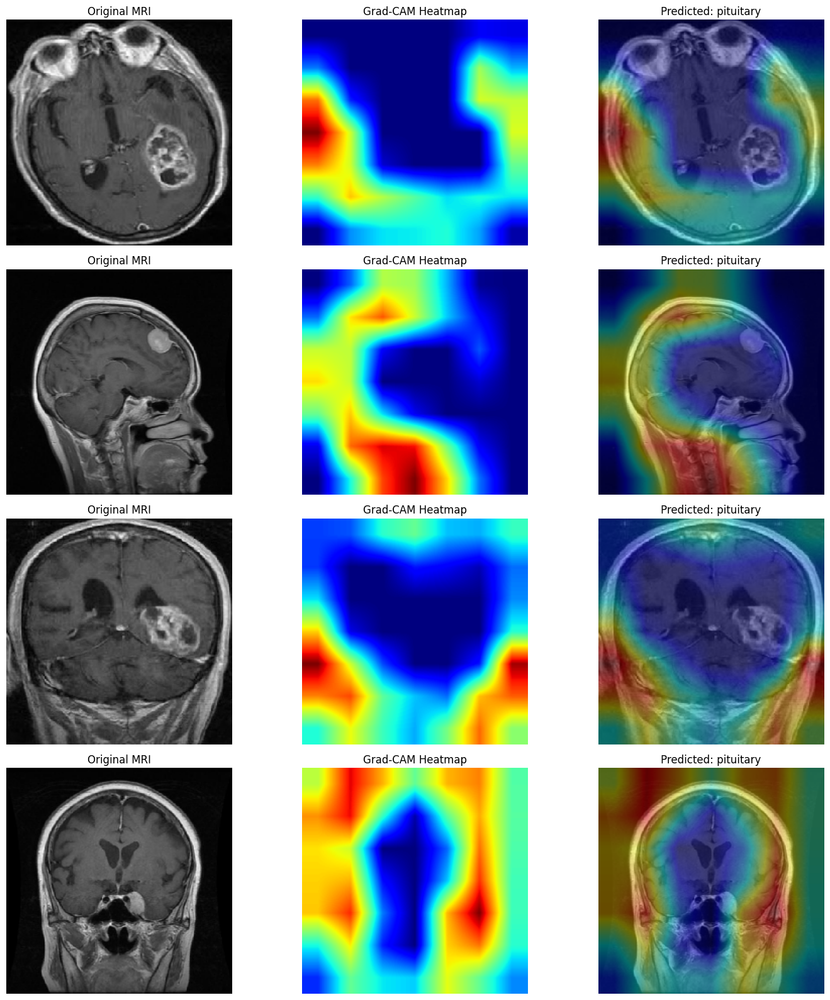

In [ ]:
from PIL import Image

plt.figure(figsize=(15, 16))

for i, (_, row) in enumerate(error_samples.iterrows()):

    img = tf.keras.utils.load_img(
        row["image"],
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)

    input_image = np.expand_dims(
        img_array, axis=0
    )

    heatmap, predicted_class, probabilities = make_gradcam(
        input_image
    )

    heatmap = cv2.resize(heatmap, (224, 224))

    heatmap_color = cv2.applyColorMap(
        np.uint8(255 * heatmap),
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        img_array.astype("uint8"), 0.6,
        heatmap_color, 0.4, 0
    )

    plt.subplot(4, 3, i * 3 + 1)
    plt.imshow(img_array.astype("uint8"))
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(4, 3, i * 3 + 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(4, 3, i * 3 + 3)
    plt.imshow(overlay)
    plt.title(
        f"Predicted: {CLASS_NAMES[predicted_class]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
correct = test_df.copy()
correct["actual"] = [CLASS_NAMES[i] for i in y_true]
correct["predicted"] = [CLASS_NAMES[i] for i in y_pred]
correct["confidence"] = np.max(y_prob, axis=1)

correct = correct[correct["actual"] == correct["predicted"]]

wrong = errors[
    (errors["actual"] == "meningioma") &
    (errors["predicted"] == "pituitary")
]

correct_samples = correct[
    correct["actual"] == "meningioma"
].sample(2, random_state=42)

wrong_samples = wrong.sample(2, random_state=42)

comparison = pd.concat([correct_samples, wrong_samples])

print(comparison[["actual", "predicted", "confidence"]])

         actual   predicted  confidence
779  meningioma  meningioma    0.972586
727  meningioma  meningioma    0.681700
519  meningioma   pituitary    0.508735
638  meningioma   pituitary    0.586170


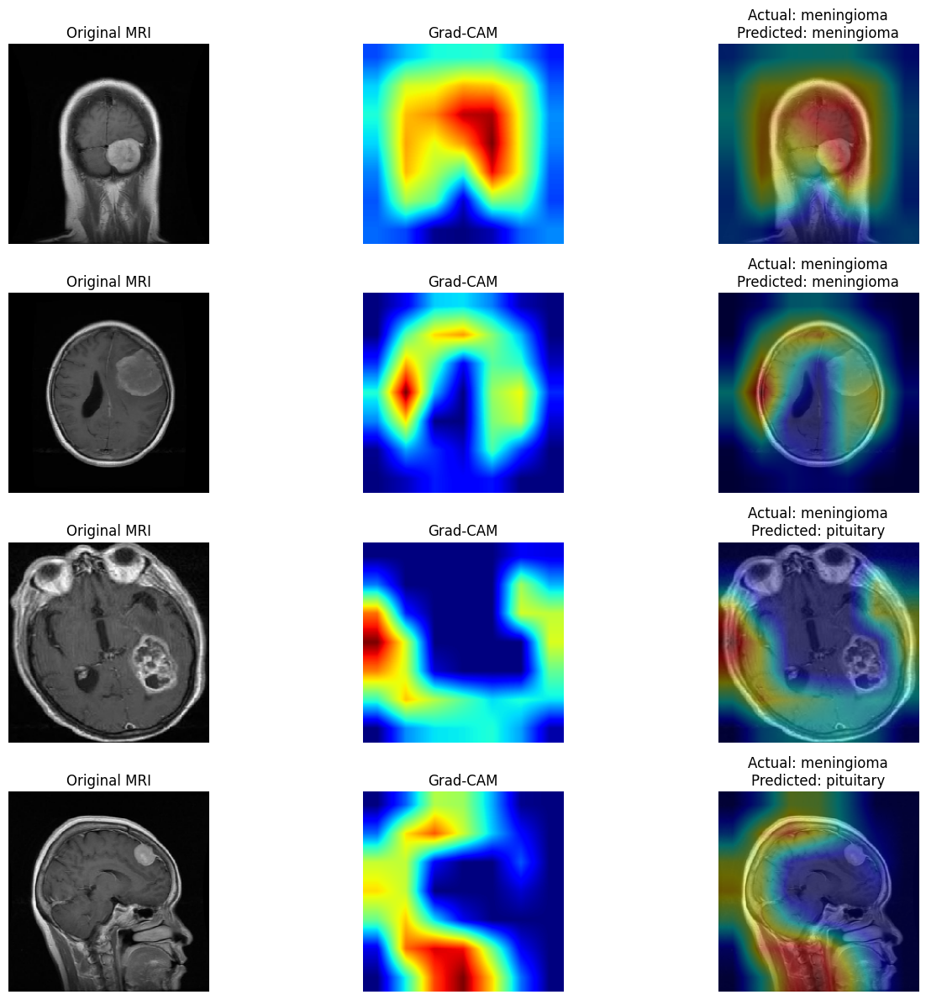

In [ ]:
plt.figure(figsize=(14, 12))

for i, (_, row) in enumerate(comparison.iterrows()):

    img = tf.keras.utils.load_img(
        row["image"], target_size=(224, 224)
    )

    arr = tf.keras.utils.img_to_array(img)
    heatmap, pred, probs = make_gradcam(
        np.expand_dims(arr, axis=0)
    )

    heatmap = cv2.resize(heatmap, (224, 224))

    heatmap_color = cv2.cvtColor(
        cv2.applyColorMap(
            np.uint8(255 * heatmap),
            cv2.COLORMAP_JET
        ),
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        arr.astype("uint8"), 0.6,
        heatmap_color, 0.4, 0
    )

    plt.subplot(4, 3, i * 3 + 1)
    plt.imshow(arr.astype("uint8"))
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(4, 3, i * 3 + 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(4, 3, i * 3 + 3)
    plt.imshow(overlay)
    plt.title(
        f"Actual: {row['actual']}\n"
        f"Predicted: {row['predicted']}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

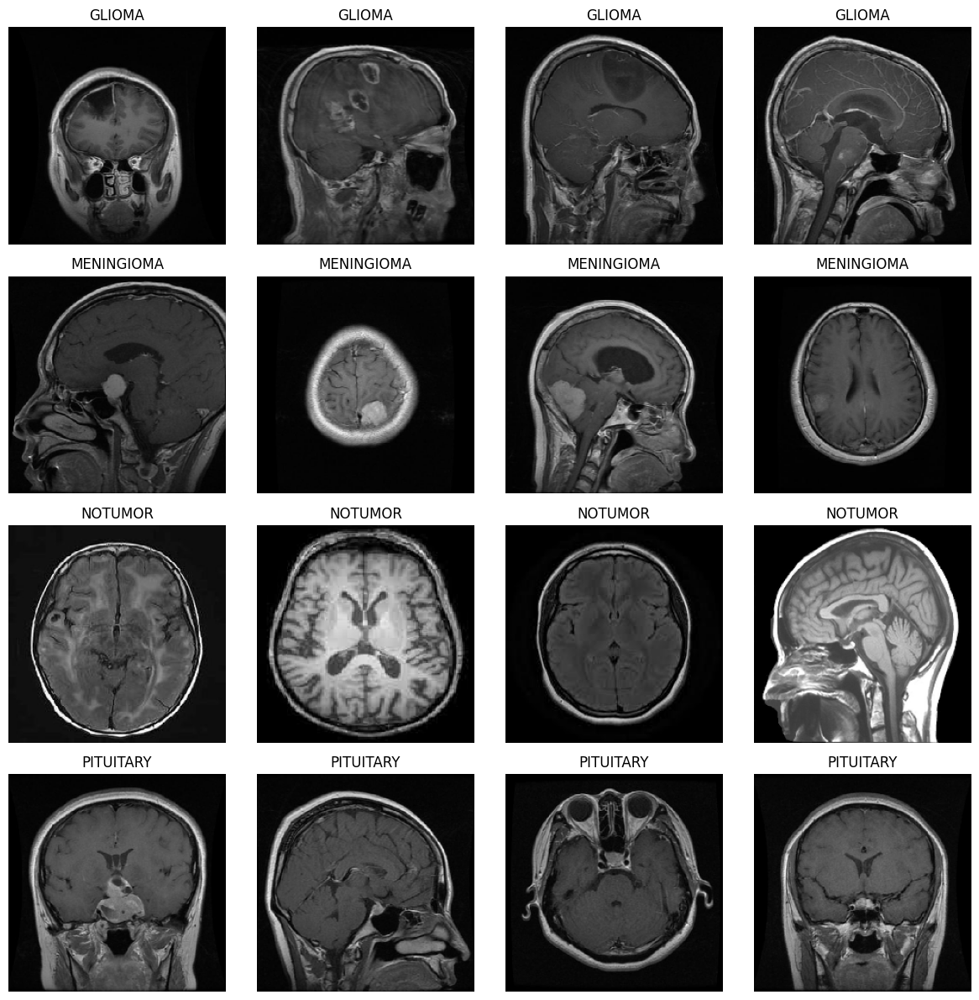

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import random

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, class_name in enumerate(CLASS_NAMES):

    folder = os.path.join(TRAIN_DIR, class_name)

    samples = random.sample(
        [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ],
        4
    )

    for j, file in enumerate(samples):

        img = tf.keras.utils.load_img(
            os.path.join(folder, file),
            target_size=(224, 224)
        )

        axes[i, j].imshow(img)
        axes[i, j].set_title(class_name.upper())
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("/content/medvision_dataset_samples.png", dpi=200)
plt.show()

In [ ]:
from PIL import Image
from collections import defaultdict
import os
import numpy as np

stats = defaultdict(list)

for class_name in CLASS_NAMES:

    folder = os.path.join(TRAIN_DIR, class_name)

    for file in os.listdir(folder):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            with Image.open(os.path.join(folder, file)) as img:

                w, h = img.size

                stats[class_name].append({
                    "width": w,
                    "height": h,
                    "ratio": w / h,
                    "mode": img.mode
                })

for class_name, values in stats.items():

    widths = [x["width"] for x in values]
    heights = [x["height"] for x in values]
    ratios = [x["ratio"] for x in values]

    print("\n", class_name.upper())
    print("Images:", len(values))
    print("Width range:", min(widths), "-", max(widths))
    print("Height range:", min(heights), "-", max(heights))
    print("Average aspect ratio:", round(np.mean(ratios), 3))


 GLIOMA
Images: 1400
Width range: 512 - 512
Height range: 512 - 512
Average aspect ratio: 1.0

 MENINGIOMA
Images: 1400
Width range: 180 - 1275
Height range: 207 - 1427
Average aspect ratio: 0.996

 NOTUMOR
Images: 1400
Width range: 150 - 1375
Height range: 168 - 1446
Average aspect ratio: 0.958

 PITUITARY
Images: 1400
Width range: 201 - 1365
Height range: 202 - 1365
Average aspect ratio: 1.0


In [ ]:
from PIL import Image
import numpy as np
import os

for class_name in CLASS_NAMES:

    folder = os.path.join(TRAIN_DIR, class_name)

    brightness = []
    contrast = []

    for file in os.listdir(folder):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            img = Image.open(
                os.path.join(folder, file)
            ).convert("L")

            arr = np.array(img)

            brightness.append(arr.mean())
            contrast.append(arr.std())

    print("\n", class_name.upper())
    print("Average brightness:", round(np.mean(brightness), 2))
    print("Average contrast:", round(np.mean(contrast), 2))


 GLIOMA
Average brightness: 33.09
Average contrast: 38.35

 MENINGIOMA
Average brightness: 43.36
Average contrast: 46.51

 NOTUMOR
Average brightness: 61.72
Average contrast: 60.64

 PITUITARY
Average brightness: 49.43
Average contrast: 41.55


In [ ]:
def normalize_mri(image, label):
    image = tf.image.rgb_to_grayscale(image)

    flat = tf.reshape(image, [-1])
    sorted_pixels = tf.sort(flat)

    n = tf.size(sorted_pixels)

    low = tf.gather(sorted_pixels, tf.cast(0.01 * tf.cast(n - 1, tf.float32), tf.int32))
    high = tf.gather(sorted_pixels, tf.cast(0.99 * tf.cast(n - 1, tf.float32), tf.int32))

    image = tf.clip_by_value(image, low, high)

    image = (image - low) / (high - low + 1e-7)
    image = image * 255.0

    image = tf.image.grayscale_to_rgb(image)

    return image, label

In [ ]:
def create_normalized_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["image"].values, df["label"].values)
    )

    if training:
        ds = ds.shuffle(
            len(df),
            seed=SEED
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.map(
        normalize_mri,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return ds


train_norm_ds = create_normalized_dataset(train_df, True)
val_norm_ds = create_normalized_dataset(val_df)
test_norm_ds = create_normalized_dataset(test_df)

print("Normalized datasets created!")

Normalized datasets created!


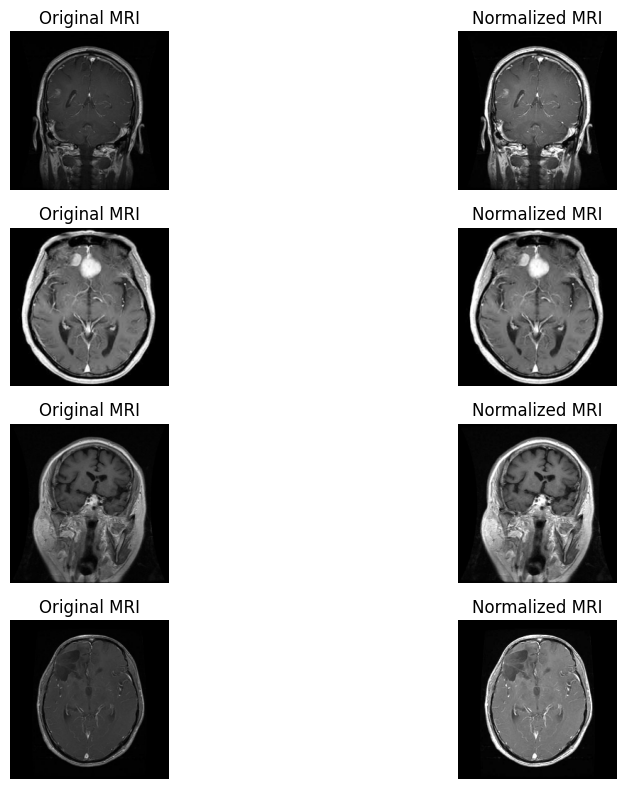

In [ ]:
original_images, labels = next(iter(val_ds))
normalized_images, _ = next(iter(val_norm_ds))

plt.figure(figsize=(12, 8))

for i in range(4):

    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(original_images[i].numpy().astype("uint8"))
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(normalized_images[i].numpy().astype("uint8"))
    plt.title("Normalized MRI")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("BASELINE - ORIGINAL IMAGES")

original_results = model.evaluate(
    val_ds,
    return_dict=True
)

print("\nBASELINE - NORMALIZED IMAGES")

normalized_results = model.evaluate(
    val_norm_ds,
    return_dict=True
)

print("\nCOMPARISON")

print("Original accuracy:", original_results["accuracy"])
print("Normalized accuracy:", normalized_results["accuracy"])

print("Original loss:", original_results["loss"])
print("Normalized loss:", normalized_results["loss"])

BASELINE - ORIGINAL IMAGES
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.8670 - loss: 0.3755

BASELINE - NORMALIZED IMAGES
35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.8339 - loss: 0.4791

COMPARISON
Original accuracy: 0.8669642806053162
Normalized accuracy: 0.8339285850524902
Original loss: 0.37551769614219666
Normalized loss: 0.4791097342967987


In [ ]:
model2 = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras"
)

base_model2 = model2.get_layer("efficientnetb0")

base_model2.trainable = True

for layer in base_model2.layers[:-30]:
    layer.trainable = False

for layer in base_model2.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Normalized experiment initialized!")

Normalized experiment initialized!


In [ ]:
normal_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/MEDVISION_AI_normalized.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history3 = model2.fit(
    train_norm_ds,
    validation_data=val_norm_ds,
    epochs=8,
    callbacks=normal_callbacks
)

Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.8594 - loss: 0.3588
Epoch 1: val_loss improved from None to 0.39069, saving model to /content/drive/MyDrive/MEDVISION_AI_normalized.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MEDVISION_AI_normalized.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 53s 272ms/step - accuracy: 0.8719 - loss: 0.3408 - val_accuracy: 0.8580 - val_loss: 0.3907 - learning_rate: 2.0000e-06
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.8816 - loss: 0.3093
Epoch 2: val_loss improved from 0.39069 to 0.38499, saving model to /content/drive/MyDrive/MEDVISION_AI_normalized.keras

Epoch 2: finished saving model to /content/drive/MyDrive/MEDVISION_AI_normalized.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 288ms/step - accuracy: 0.8855 - loss: 0.3113 - val_accuracy: 0.8589 - val_loss: 0.3850 - learning_rate: 2.0000e-06
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8871 - loss: 0.2993
Epoch 3: val_loss did not im

In [ ]:
baseline = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras"
)

normalized = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_normalized.keras"
)

print("ORIGINAL MODEL")
baseline.evaluate(val_ds)

print("\nNORMALIZED MODEL")
normalized.evaluate(val_norm_ds)

ORIGINAL MODEL
35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.8670 - loss: 0.3755

NORMALIZED MODEL
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 176ms/step - accuracy: 0.8589 - loss: 0.3850


[0.38498854637145996, 0.8589285612106323]

In [ ]:
baseline = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_best_finetuned.keras"
)

normalized = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_normalized.keras"
)

print("Both models loaded successfully!")

Both models loaded successfully!


In [ ]:
y_val = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

baseline_prob = baseline.predict(val_ds)
normalized_prob = normalized.predict(val_norm_ds)

baseline_pred = np.argmax(baseline_prob, axis=1)
normalized_pred = np.argmax(normalized_prob, axis=1)

print("Validation predictions completed!")

35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step
35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step
Validation predictions completed!


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

def evaluate_model(name, y_true, predictions):

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2, 3]
    )

    print("\n", name)
    print(classification_report(
        y_true,
        predictions,
        target_names=CLASS_NAMES,
        digits=4
    ))

    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Balanced accuracy:", balanced_accuracy_score(y_true, predictions))

    for i, class_name in enumerate(CLASS_NAMES):

        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - TP - FN - FP

        sensitivity = TP / (TP + FN)
        specificity = TN / (TN + FP)

        print(
            f"{class_name}: "
            f"Sensitivity={sensitivity:.4f}, "
            f"Specificity={specificity:.4f}"
        )

    return cm


baseline_cm = evaluate_model(
    "ORIGINAL MODEL",
    y_val,
    baseline_pred
)

normalized_cm = evaluate_model(
    "NORMALIZED MODEL",
    y_val,
    normalized_pred
)


 ORIGINAL MODEL
              precision    recall  f1-score   support

      glioma     0.9465    0.8214    0.8795       280
  meningioma     0.8489    0.6821    0.7564       280
     notumor     0.9783    0.9679    0.9731       280
   pituitary     0.7440    0.9964    0.8519       280

    accuracy                         0.8670      1120
   macro avg     0.8794    0.8670    0.8652      1120
weighted avg     0.8794    0.8670    0.8652      1120

Accuracy: 0.8669642857142857
Balanced accuracy: 0.8669642857142857
glioma: Sensitivity=0.8214, Specificity=0.9845
meningioma: Sensitivity=0.6821, Specificity=0.9595
notumor: Sensitivity=0.9679, Specificity=0.9929
pituitary: Sensitivity=0.9964, Specificity=0.8857

 NORMALIZED MODEL
              precision    recall  f1-score   support

      glioma     0.9084    0.8500    0.8782       280
  meningioma     0.8657    0.6214    0.7235       280
     notumor     0.9819    0.9679    0.9748       280
   pituitary     0.7323    0.9964    0.8442      

In [ ]:
FINAL_MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"

baseline.save(FINAL_MODEL_PATH)

print("MEDVISION AI primary model saved!")
print("Location:", FINAL_MODEL_PATH)

MEDVISION AI primary model saved!
Location: /content/drive/MyDrive/MEDVISION_AI_FINAL.keras


In [ ]:
import json

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

with open(
    "/content/drive/MyDrive/MEDVISION_AI_classes.json",
    "w"
) as f:
    json.dump(CLASS_NAMES, f)

print("Class labels saved!")

Class labels saved!


In [ ]:
from PIL import Image
import numpy as np
import tensorflow as tf

def predict_mri(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)

    input_image = np.expand_dims(
        img_array, axis=0
    )

    predictions = baseline.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    results = {
        CLASS_NAMES[i]: round(
            float(predictions[i]) * 100, 2
        )
        for i in range(len(CLASS_NAMES))
    }

    print("\nMEDVISION AI - MRI ANALYSIS")
    print("----------------------------")

    print("Predicted Class:", CLASS_NAMES[predicted_index])
    print("Model Score:", round(
        float(predictions[predicted_index]) * 100, 2
    ), "%")

    print("\nClass-wise Scores:")

    for name, score in results.items():
        print(f"{name}: {score}%")

    return input_image, predictions, predicted_index

In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

input_image, predictions, predicted_index = predict_mri(
    image_path
)

Saving Te-pi_4.jpg to Te-pi_4.jpg

MEDVISION AI - MRI ANALYSIS
----------------------------
Predicted Class: pituitary
Model Score: 99.85 %

Class-wise Scores:
glioma: 0.0%
meningioma: 0.11%
notumor: 0.03%
pituitary: 99.85%


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

input_image, predictions, predicted_index = predict_mri(
    image_path
)

Saving Te-me_8.jpg to Te-me_8.jpg

MEDVISION AI - MRI ANALYSIS
----------------------------
Predicted Class: notumor
Model Score: 70.94 %

Class-wise Scores:
glioma: 0.04%
meningioma: 29.01%
notumor: 70.94%
pituitary: 0.0%


In [ ]:
def predict_mri(image_path):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [224, 224]
    )

    input_image = tf.expand_dims(image, axis=0)

    predictions = baseline.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    print("\nMEDVISION AI - MRI CLASSIFICATION")
    print("----------------------------------")

    print("Predicted class:", CLASS_NAMES[predicted_index])
    print("Model score:", f"{predictions[predicted_index]*100:.2f}%")

    print("\nAll class scores:")

    for name, score in zip(CLASS_NAMES, predictions):
        print(f"{name}: {score*100:.2f}%")

    return input_image, predictions, predicted_index

In [ ]:
sample = test_df[
    test_df["label"] == CLASS_NAMES.index("meningioma")
].iloc[0]

print("Actual class: meningioma")
print("Image:", sample["image"])

input_image, predictions, predicted_index = predict_mri(
    sample["image"]
)

Actual class: meningioma
Image: /content/medvision_dataset/Testing/meningioma/Te-aug-me_1.jpg

MEDVISION AI - MRI CLASSIFICATION
----------------------------------
Predicted class: meningioma
Model score: 51.80%

All class scores:
glioma: 9.91%
meningioma: 51.80%
notumor: 1.85%
pituitary: 36.44%


In [ ]:
samples = test_df[
    test_df["label"] == CLASS_NAMES.index("meningioma")
].sample(20, random_state=42)

correct = 0

for _, row in samples.iterrows():

    img = tf.io.read_file(row["image"])
    img = tf.io.decode_image(img, channels=3)
    img.set_shape([None, None, 3])

    img = tf.image.resize(img, [224, 224])
    img = tf.expand_dims(img, 0)

    pred = baseline.predict(img, verbose=0)[0]

    predicted_class = CLASS_NAMES[np.argmax(pred)]

    if predicted_class == "meningioma":
        correct += 1

    print(
        "Actual: meningioma |",
        "Predicted:", predicted_class,
        "| Score:", round(float(np.max(pred))*100, 2), "%"
    )

print("\nCorrect predictions:", correct, "/ 20")

Actual: meningioma | Predicted: meningioma | Score: 87.47 %
Actual: meningioma | Predicted: meningioma | Score: 79.16 %
Actual: meningioma | Predicted: meningioma | Score: 87.42 %
Actual: meningioma | Predicted: meningioma | Score: 94.92 %
Actual: meningioma | Predicted: pituitary | Score: 85.06 %
Actual: meningioma | Predicted: meningioma | Score: 96.32 %
Actual: meningioma | Predicted: meningioma | Score: 89.39 %
Actual: meningioma | Predicted: meningioma | Score: 58.76 %
Actual: meningioma | Predicted: meningioma | Score: 76.46 %
Actual: meningioma | Predicted: pituitary | Score: 73.04 %
Actual: meningioma | Predicted: pituitary | Score: 97.49 %
Actual: meningioma | Predicted: meningioma | Score: 55.27 %
Actual: meningioma | Predicted: meningioma | Score: 98.6 %
Actual: meningioma | Predicted: pituitary | Score: 82.17 %
Actual: meningioma | Predicted: meningioma | Score: 68.38 %
Actual: meningioma | Predicted: meningioma | Score: 92.46 %
Actual: meningioma | Predicted: meningioma | 

In [ ]:
!pip install ImageHash

In [ ]:
import os
import hashlib
from PIL import Image

def get_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_hashes = {}
test_hashes = {}

for _, row in train_df.iterrows():
    train_hashes[row["image"]] = get_hash(row["image"])

for _, row in test_df.iterrows():
    test_hashes[row["image"]] = get_hash(row["image"])

train_hash_set = set(train_hashes.values())
test_hash_set = set(test_hashes.values())

duplicates = train_hash_set.intersection(test_hash_set)

print("Training images:", len(train_hashes))
print("Testing images:", len(test_hashes))
print("Exact duplicate hashes:", len(duplicates))

Training images: 4480
Testing images: 1600
Exact duplicate hashes: 0


In [ ]:
import imagehash

train_phashes = []

for _, row in train_df.iterrows():
    img = Image.open(row["image"]).convert("RGB")
    train_phashes.append((
        row["image"],
        row["label"],
        imagehash.phash(img)
    ))

test_phashes = []

for _, row in test_df.iterrows():
    img = Image.open(row["image"]).convert("RGB")
    test_phashes.append((
        row["image"],
        row["label"],
        imagehash.phash(img)
    ))

near_duplicates = []

for test_path, test_label, test_hash in test_phashes:

    for train_path, train_label, train_hash in train_phashes:

        distance = test_hash - train_hash

        if distance <= 4:
            near_duplicates.append((
                test_path,
                train_path,
                distance,
                test_label,
                train_label
            ))

print("Potential near-duplicates:", len(near_duplicates))

for item in near_duplicates[:20]:
    print(item)

Potential near-duplicates: 1593
('/content/medvision_dataset/Testing/glioma/Te-gl_10.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_327.jpg', np.int64(4), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_122.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_1219.jpg', np.int64(2), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_122.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_970.jpg', np.int64(4), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_137.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_460.jpg', np.int64(2), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_149.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_717.jpg', np.int64(4), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_156.jpg', '/content/medvision_dataset/Training/glioma/Tr-gl_1297.jpg', np.int64(4), 0, 0)
('/content/medvision_dataset/Testing/glioma/Te-gl_160.jpg', '/content/medvision_dataset/Training/meningioma/Tr-me_1122.jpg', np.int64

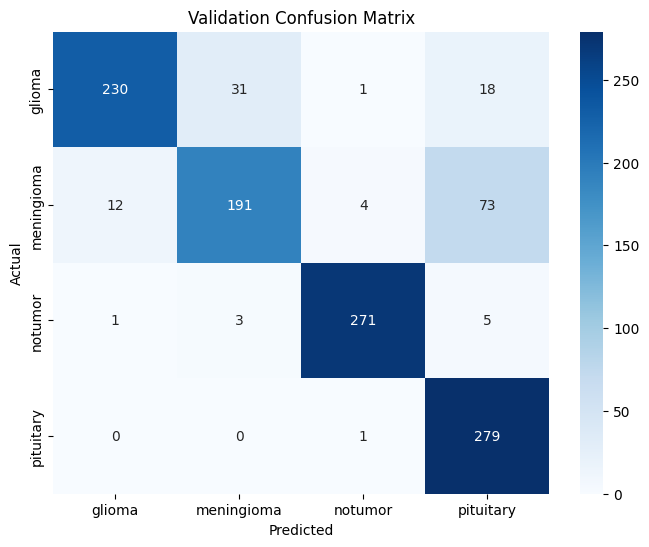

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_val = confusion_matrix(
    y_val,
    baseline_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation Confusion Matrix")
plt.show()

In [ ]:
val_results = val_df.copy()

val_results["actual"] = [
    CLASS_NAMES[i] for i in y_val
]

val_results["predicted"] = [
    CLASS_NAMES[i] for i in baseline_pred
]

val_results["confidence"] = np.max(
    baseline_prob, axis=1
)

meningioma_errors = val_results[
    (val_results["actual"] == "meningioma") &
    (val_results["predicted"] != "meningioma")
]

print("Meningioma validation errors:", len(meningioma_errors))

print(
    meningioma_errors[
        ["image", "actual", "predicted", "confidence"]
    ].to_string(index=False)
)

Meningioma validation errors: 89
                                                          image     actual predicted  confidence
   /content/medvision_dataset/Training/meningioma/Tr-me_239.jpg meningioma pituitary    0.642542
  /content/medvision_dataset/Training/meningioma/Tr-me_1297.jpg meningioma pituitary    0.855347
   /content/medvision_dataset/Training/meningioma/Tr-me_401.jpg meningioma    glioma    0.468631
  /content/medvision_dataset/Training/meningioma/Tr-me_1147.jpg meningioma pituitary    0.789779
  /content/medvision_dataset/Training/meningioma/Tr-me_1080.jpg meningioma pituitary    0.616162
  /content/medvision_dataset/Training/meningioma/Tr-me_1012.jpg meningioma pituitary    0.667725
   /content/medvision_dataset/Training/meningioma/Tr-me_590.jpg meningioma pituitary    0.732790
   /content/medvision_dataset/Training/meningioma/Tr-me_263.jpg meningioma pituitary    0.874200
/content/medvision_dataset/Training/meningioma/Tr-aug-me_82.jpg meningioma pituitary    0.5883

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

wrong = np.where(
    (y_val == 1) & (baseline_pred == 3)
)[0]

print("Meningioma predicted as pituitary:", len(wrong))

plt.figure(figsize=(15, 12))

for i, idx in enumerate(wrong[:20]):
    img = tf.io.read_file(val_paths[idx])
    img = tf.io.decode_image(img, channels=3)

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Actual: Meningioma\nPredicted: Pituitary")
    plt.axis("off")

plt.tight_layout()
plt.show()

Meningioma predicted as pituitary: 73


NameError: name 'val_paths' is not defined

<Figure size 1500x1200 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

wrong = np.where((y_val == 1) & (baseline_pred == 3))[0]

print("Meningioma predicted as pituitary:", len(wrong))

plt.figure(figsize=(15, 12))

for i, idx in enumerate(wrong[:20]):
    path = val_df.iloc[idx]["filepath"]

    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3)

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Actual: Meningioma\nPredicted: Pituitary")
    plt.axis("off")

plt.tight_layout()
plt.show()

Meningioma predicted as pituitary: 73


KeyError: 'filepath'

<Figure size 1500x1200 with 0 Axes>

In [ ]:
print("Columns:", val_df.columns.tolist())
print("\nFirst 5 rows:")
display(val_df.head())

Columns: ['image', 'label']

First 5 rows:


,image,label
835,/content/medvision_dataset/Training/glioma/Tr-...,0
1565,/content/medvision_dataset/Training/meningioma...,1
4993,/content/medvision_dataset/Training/pituitary/...,3
1242,/content/medvision_dataset/Training/glioma/Tr-...,0
1095,/content/medvision_dataset/Training/glioma/Tr-...,0


Meningioma predicted as pituitary: 73


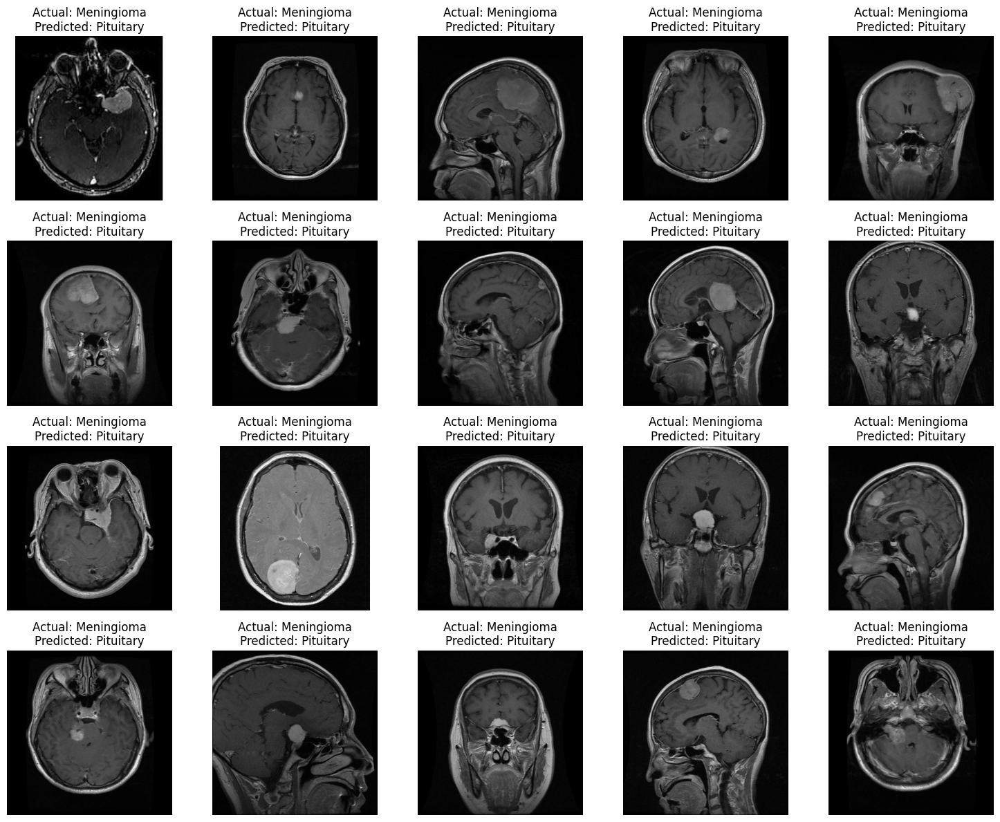

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

wrong = np.where((y_val == 1) & (baseline_pred == 3))[0]

print("Meningioma predicted as pituitary:", len(wrong))

plt.figure(figsize=(15, 12))

for i, idx in enumerate(wrong[:20]):
    path = val_df.iloc[idx]["image"]

    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3)

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Actual: Meningioma\nPredicted: Pituitary")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
baseline_probs = baseline.predict(val_ds, verbose=1)
baseline_pred = np.argmax(baseline_probs, axis=1)

print("Prediction shape:", baseline_probs.shape)
print("Total validation predictions:", len(baseline_pred))

35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step
Prediction shape: (1120, 4)
Total validation predictions: 1120


In [ ]:
import pandas as pd
import numpy as np

results = val_df.reset_index(drop=True).copy()

results["actual"] = [CLASS_NAMES[i] for i in y_val]
results["predicted"] = [CLASS_NAMES[i] for i in baseline_pred]
results["confidence"] = np.max(baseline_probs, axis=1)

errors = results[
    (results["actual"] == "meningioma") &
    (results["predicted"] == "pituitary")
]

display(errors[["image", "label", "actual", "predicted", "confidence"]].head(20))

,image,label,actual,predicted,confidence
28,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.642542
34,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.855347
68,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.789779
69,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.616162
86,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.667725
108,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.732790
109,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.874200
117,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.588346
123,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.863345
146,/content/medvision_dataset/Training/meningioma...,1,meningioma,pituitary,0.995841


In [ ]:
print("DataFrame labels match y_val:",
      np.array_equal(
          val_df.reset_index(drop=True)["label"].values,
          y_val
      ))

print("Validation images:", len(val_df))
print("Validation labels:", len(y_val))
print("Prediction rows:", len(baseline_probs))

print("\nClass mapping:")
for i, name in enumerate(CLASS_NAMES):
    print(i, name)

DataFrame labels match y_val: True
Validation images: 1120
Validation labels: 1120
Prediction rows: 1120

Class mapping:
0 glioma
1 meningioma
2 notumor
3 pituitary


In [ ]:
val_ds_labels = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

print("Validation dataset matches y_val:",
      np.array_equal(val_ds_labels, y_val))

print("Validation dataset size:", len(val_ds_labels))

Validation dataset matches y_val: True
Validation dataset size: 1120


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    baseline_pred,
    target_names=CLASS_NAMES,
    digits=4
))

              precision    recall  f1-score   support

      glioma     0.9465    0.8214    0.8795       280
  meningioma     0.8489    0.6821    0.7564       280
     notumor     0.9783    0.9679    0.9731       280
   pituitary     0.7440    0.9964    0.8519       280

    accuracy                         0.8670      1120
   macro avg     0.8794    0.8670    0.8652      1120
weighted avg     0.8794    0.8670    0.8652      1120



In [ ]:
val_ds_labels = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

print("Dataset ordering matches:",
      np.array_equal(val_ds_labels, y_val))

Dataset ordering matches: True


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
import os

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

print("\nSaved model files:")
for f in [
    "MEDVISION_AI_FINAL.keras",
    "MEDVISION_AI_classes.json",
    "MEDVISION_AI_weighted.keras"
]:
    path = "/content/drive/MyDrive/" + f
    print(f, "EXISTS" if os.path.exists(path) else "NOT FOUND")

print("\nExisting notebook variables:")
for v in ["train_ds", "val_ds", "y_train", "y_val",
          "baseline", "CLASS_NAMES"]:
    print(v, "AVAILABLE" if v in globals() else "NOT AVAILABLE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Saved model files:
MEDVISION_AI_FINAL.keras EXISTS
MEDVISION_AI_classes.json EXISTS
MEDVISION_AI_weighted.keras NOT FOUND

Existing notebook variables:
train_ds NOT AVAILABLE
val_ds NOT AVAILABLE
y_train NOT AVAILABLE
y_val NOT AVAILABLE
baseline NOT AVAILABLE
CLASS_NAMES NOT AVAILABLE


In [2]:
import os

paths = [
    "/content/medvision_dataset",
    "/content/archive.zip",
    "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"
]

for path in paths:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

/content/medvision_dataset NOT FOUND
/content/archive.zip NOT FOUND
/content/drive/MyDrive/MEDVISION_AI_FINAL.keras EXISTS


In [3]:
import os

root = "/content/drive/MyDrive"

print("Searching Google Drive...\n")

for current, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

    for d in dirs:
        if "medvision" in d.lower() or "brain" in d.lower():
            print("FOLDER:", os.path.join(current, d))

    for f in files:
        if f.lower().endswith(".zip") and (
            "brain" in f.lower() or "med" in f.lower()
        ):
            print("ZIP:", os.path.join(current, f))

Searching Google Drive...



In [4]:
import os

for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Colab Notebooks
Search.docx
Search.gdoc
124266835929291037_10th_standard_fl_kannada_glance_me_once-passing_pacakge_2019-10_kolar.pdf
DHANYASHREE.N.pdf
Document from ~dhanyaaa.pdf
IMG-20220202-WA0002.jpg
February_1.jpg
Aadhaar - EAadhaar_Dhanya_page-0001.jpg
PUC Annual Examination Result - 2023.pdf
Classroom
IMG_20231107_170519.jpg
IMG-20240602-WA0002.jpg
sanika.pdf
Dhanyashree  N.pdf
Deekshitha P.pdf
Poorvika R.jpg
Untitled presentation (1).gslides
Untitled presentation.gslides
IMG_20250616_215135 (1).jpg
IMG_20250616_215135.jpg
Adobe Scan Jul 05, 2025.pdf
Dhanyashree N resume.pdf
dhanya_area of focus.pdf
IMG-20250929-WA0026.jpg
IMG-20250929-WA0031.jpg
IMG-20250929-WA0029.jpg
IMG-20250929-WA0033.jpg
IMG-20250929-WA0035.jpg
IMG-20250929-WA0040.jpg
IMG-20250929-WA0045.jpg
IMG-20250929-WA0047.jpg
IMG-20250929-WA0056.jpg
IMG-20250929-WA0043.jpg
IMG-20250929-WA0058.jpg
IMG-20250929-WA0060.jpg
IMG-20250929-WA0062.jpg
IMG-20250929-WA0065.jpg
IMG-20250929-WA0067.jpg
IMG-20250929-WA0069.jpg
IMG

In [5]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/medvision_dataset"

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content")

print("Extraction completed!")

print("\nDataset folders:")
print(os.listdir(extract_path))

Extracting dataset...
Extraction completed!

Dataset folders:


FileNotFoundError: [Errno 2] No such file or directory: '/content/medvision_dataset'

In [6]:
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    names = z.namelist()

    print("Total files:", len(names))
    print("\nFirst 25 paths:")

    for name in names[:25]:
        print(name)

Total files: 7200

First 25 paths:
Testing/glioma/Te-gl_1.jpg
Testing/glioma/Te-gl_10.jpg
Testing/glioma/Te-gl_100.jpg
Testing/glioma/Te-gl_101.jpg
Testing/glioma/Te-gl_102.jpg
Testing/glioma/Te-gl_103.jpg
Testing/glioma/Te-gl_104.jpg
Testing/glioma/Te-gl_105.jpg
Testing/glioma/Te-gl_106.jpg
Testing/glioma/Te-gl_107.jpg
Testing/glioma/Te-gl_108.jpg
Testing/glioma/Te-gl_109.jpg
Testing/glioma/Te-gl_11.jpg
Testing/glioma/Te-gl_110.jpg
Testing/glioma/Te-gl_111.jpg
Testing/glioma/Te-gl_112.jpg
Testing/glioma/Te-gl_113.jpg
Testing/glioma/Te-gl_114.jpg
Testing/glioma/Te-gl_115.jpg
Testing/glioma/Te-gl_116.jpg
Testing/glioma/Te-gl_117.jpg
Testing/glioma/Te-gl_118.jpg
Testing/glioma/Te-gl_119.jpg
Testing/glioma/Te-gl_12.jpg
Testing/glioma/Te-gl_120.jpg


In [7]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/medvision_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['Training', 'Testing']


In [8]:
for folder in ["Training", "Testing"]:
    print("\n", folder)

    for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
        path = f"/content/medvision_dataset/{folder}/{cls}"
        print(cls, ":", len(os.listdir(path)))


 Training
glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400

 Testing
glioma : 400
meningioma : 400
notumor : 400
pituitary : 400


In [9]:
import os

for folder in ["Training", "Testing"]:
    print("\n", folder)

    for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
        path = f"/content/medvision_dataset/{folder}/{cls}"
        print(cls, ":", len(os.listdir(path)))


 Training
glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400

 Testing
glioma : 400
meningioma : 400
notumor : 400
pituitary : 400


In [10]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/medvision_dataset"

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

data = []

for label, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, "Training", cls)

    for file in sorted(os.listdir(folder)):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            data.append({
                "image": os.path.join(folder, file),
                "label": label
            })

df = pd.DataFrame(data)

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

Training images: 4480
Validation images: 1120

Validation distribution:
label
0    280
1    280
2    280
3    280
Name: count, dtype: int64


In [11]:
import tensorflow as tf
import json
import os

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"

baseline = tf.keras.models.load_model(MODEL_PATH)

with open("/content/drive/MyDrive/MEDVISION_AI_classes.json") as f:
    CLASS_NAMES = json.load(f)

print("Model loaded successfully!")
print("Classes:", CLASS_NAMES)
print("Input shape:", baseline.input_shape)
print("Output shape:", baseline.output_shape)

Model loaded successfully!
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)


In [12]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def create_dataset(dataframe, shuffle=False):
    paths = dataframe["image"].values
    labels = dataframe["label"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(2000, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 140
Validation batches: 35


In [13]:
baseline_probs = baseline.predict(val_ds, verbose=1)
baseline_pred = np.argmax(baseline_probs, axis=1)

print("\nBaseline validation accuracy:",
      round(np.mean(baseline_pred == val_df["label"].values) * 100, 2), "%")

35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step

Baseline validation accuracy: 86.7 %


In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

y_train = train_df["label"].values

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))

# Give meningioma a moderate additional weight
class_weights[1] *= 1.3

print("Class weights:")
for i, weight in class_weights.items():
    print(CLASS_NAMES[i], round(weight, 3))

Class weights:
glioma 1.0
meningioma 1.3
notumor 1.0
pituitary 1.0


In [15]:
weighted_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"
)

base = weighted_model.get_layer("efficientnetb0")

for layer in base.layers:
    layer.trainable = False

for layer in base.layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Weighted model ready!")
print("Trainable layers:", sum(layer.trainable for layer in base.layers))

Weighted model ready!
Trainable layers: 23


In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/MEDVISION_AI_weighted.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 38s 133ms/step - accuracy: 0.8888 - loss: 0.3260 - val_accuracy: 0.8625 - val_loss: 0.3795
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 129ms/step - accuracy: 0.8853 - loss: 0.3287 - val_accuracy: 0.8580 - val_loss: 0.3883
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 135ms/step - accuracy: 0.8922 - loss: 0.3175 - val_accuracy: 0.8616 - val_loss: 0.3790
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - accuracy: 0.8984 - loss: 0.3103 - val_accuracy: 0.8652 - val_loss: 0.3799
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.8973 - loss: 0.3175 - val_accuracy: 0.8652 - val_loss: 0.3714
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - accuracy: 0.8902 - loss: 0.3154 - val_accuracy: 0.8634 - val_loss: 0.3803
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - accuracy: 0.8960 - loss: 0.3139 - val_accuracy: 0.8670 - val_loss: 0.3677
Epoch 8/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.9018 - loss: 0.2959 - 

35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step

WEIGHTED MODEL CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9538    0.8107    0.8764       280
  meningioma     0.8369    0.6964    0.7602       280
     notumor     0.9818    0.9643    0.9730       280
   pituitary     0.7460    0.9964    0.8532       280

    accuracy                         0.8670      1120
   macro avg     0.8796    0.8670    0.8657      1120
weighted avg     0.8796    0.8670    0.8657      1120



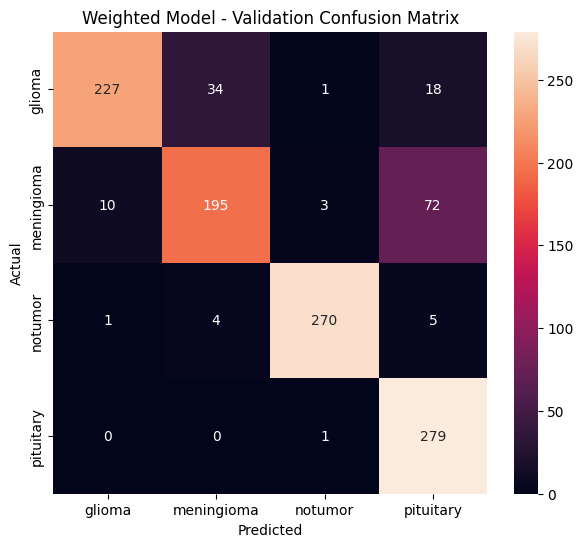

In [17]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

weighted_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_weighted.keras"
)

weighted_probs = weighted_model.predict(val_ds, verbose=1)
weighted_pred = np.argmax(weighted_probs, axis=1)

y_true = val_df["label"].values

print("\nWEIGHTED MODEL CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    weighted_pred,
    target_names=CLASS_NAMES,
    digits=4
))

cm = confusion_matrix(y_true, weighted_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Weighted Model - Validation Confusion Matrix")
plt.show()

In [18]:
import tensorflow as tf

baseline = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"
)

weighted_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_weighted.keras"
)

print("Both models loaded successfully!")

Both models loaded successfully!


In [19]:
print("Baseline:", baseline.output_shape)
print("Weighted:", weighted_model.output_shape)

Baseline: (None, 4)
Weighted: (None, 4)


In [20]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

def make_gradcam(model, image):
    base = model.get_layer("efficientnetb0")

    feature_model = tf.keras.Model(
        inputs=base.input,
        outputs=[
            base.get_layer("top_conv").output,
            base.output
        ]
    )

    augmentation = model.get_layer("sequential")
    pooling = model.get_layer("global_average_pooling2d")
    dropout1 = model.get_layer("dropout")
    dense1 = model.get_layer("dense")
    dropout2 = model.get_layer("dropout_1")
    classifier = model.get_layer("dense_1")

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        augmented = augmentation(image, training=False)

        conv_output, features = feature_model(
            augmented, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return (
        heatmap.numpy(),
        int(class_index.numpy()),
        predictions.numpy()[0]
    )

print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


In [21]:
meningioma_indices = np.where(
    val_df["label"].values == 1
)[0]

sample_idx = meningioma_indices[0]

sample_path = val_df.iloc[sample_idx]["image"]

print("Selected image:", sample_path)

Selected image: /content/medvision_dataset/Training/meningioma/Tr-me_1057.jpg


In [22]:
img = tf.io.read_file(sample_path)
img = tf.io.decode_image(img, channels=3)
img = tf.image.resize(img, [224, 224])

input_image = tf.expand_dims(
    tf.cast(img, tf.float32), 0
)

cam_base, pred_base, probs_base = make_gradcam(
    baseline, input_image
)

cam_weighted, pred_weighted, probs_weighted = make_gradcam(
    weighted_model, input_image
)

print("Actual class: meningioma")
print("Baseline prediction:", CLASS_NAMES[pred_base])
print("Weighted prediction:", CLASS_NAMES[pred_weighted])

Actual class: meningioma
Baseline prediction: meningioma
Weighted prediction: meningioma


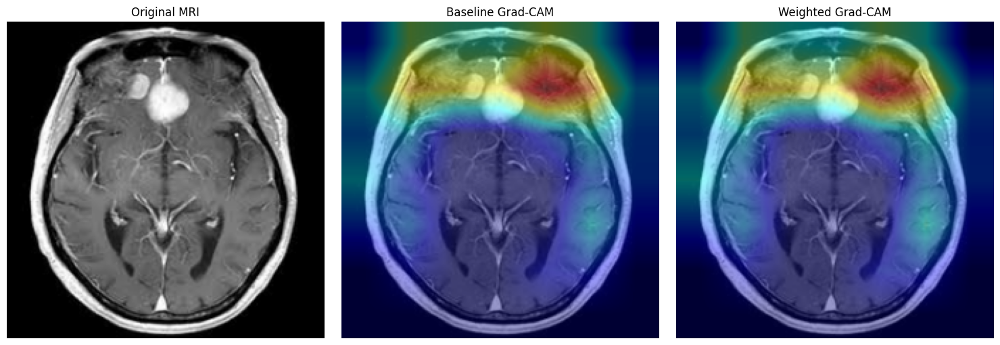

In [23]:
original = input_image[0].numpy().astype(np.uint8)

def overlay_cam(original, heatmap):
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(
        heatmap, cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap, cv2.COLOR_BGR2RGB
    )

    return cv2.addWeighted(
        original, 0.6, heatmap, 0.4, 0
    )

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(overlay_cam(original, cam_base))
plt.title("Baseline Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay_cam(original, cam_weighted))
plt.title("Weighted Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
print("ACTUAL CLASS: MENINGIOMA")

print("\nBASELINE MODEL")
for i, name in enumerate(CLASS_NAMES):
    print(name, round(float(probs_base[i]), 4))

print("\nWEIGHTED MODEL")
for i, name in enumerate(CLASS_NAMES):
    print(name, round(float(probs_weighted[i]), 4))

ACTUAL CLASS: MENINGIOMA

BASELINE MODEL
glioma 0.0013
meningioma 0.4979
notumor 0.4285
pituitary 0.0723

WEIGHTED MODEL
glioma 0.0009
meningioma 0.5463
notumor 0.3993
pituitary 0.0535


In [25]:
!pip install -q gradio

In [26]:
import gradio as gr
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from PIL import Image

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"

model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

print("MEDVISION AI initialized!")
print("Model: EfficientNetB0")
print("Classes:", CLASS_NAMES)

MEDVISION AI initialized!
Model: EfficientNetB0
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [27]:
def analyze_mri(image):
    if image is None:
        raise gr.Error("Please upload an MRI image.")

    image = image.convert("RGB")
    original = np.array(image)

    resized = tf.image.resize(
        original, [224, 224]
    )

    input_image = tf.expand_dims(
        tf.cast(resized, tf.float32), 0
    )

    probabilities = model.predict(
        input_image, verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = CLASS_NAMES[predicted_index]

    heatmap, _, _ = make_gradcam(
        model, input_image
    )

    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)

    heatmap = cv2.applyColorMap(
        heatmap, cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap, cv2.COLOR_BGR2RGB
    )

    base_image = resized.numpy().astype(np.uint8)

    overlay = cv2.addWeighted(
        base_image, 0.6, heatmap, 0.4, 0
    )

    scores = {
        CLASS_NAMES[i]: float(probabilities[i])
        for i in range(4)
    }

    report = (
        f"Predicted category: {predicted_class.upper()}\n"
        f"Model confidence: {probabilities[predicted_index]*100:.2f}%\n\n"
        "This is an experimental AI image-classification result. "
        "It is not a medical diagnosis. Clinical interpretation "
        "requires review by a qualified radiologist."
    )

    return scores, overlay, report

print("MRI analysis function ready!")

MRI analysis function ready!


In [28]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("# MEDVISION AI")
    gr.Markdown("### Brain MRI Classification and Explainable AI")
    gr.Markdown(
        "Upload a brain MRI image to generate an AI classification "
        "and Grad-CAM visualization."
    )

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Upload Brain MRI"
            )

            analyze_button = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Label(
                num_top_classes=4,
                label="Classification Probabilities"
            )

            report_output = gr.Textbox(
                label="Analysis Summary",
                lines=5
            )

    gradcam_output = gr.Image(
        label="Grad-CAM Visualization"
    )

    analyze_button.click(
        fn=analyze_mri,
        inputs=image_input,
        outputs=[
            prediction_output,
            gradcam_output,
            report_output
        ]
    )

demo.launch(share=True)

/tmp/ipykernel_865/710957553.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4b00d1a47901ca4d12.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [29]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import pandas as pd

probs = baseline.predict(val_ds, verbose=1)
preds = np.argmax(probs, axis=1)

y_true = val_df["label"].values

print(classification_report(
    y_true,
    preds,
    target_names=CLASS_NAMES,
    digits=4
))

cm = confusion_matrix(y_true, preds)

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
))

35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step
              precision    recall  f1-score   support

      glioma     0.9465    0.8214    0.8795       280
  meningioma     0.8489    0.6821    0.7564       280
     notumor     0.9783    0.9679    0.9731       280
   pituitary     0.7440    0.9964    0.8519       280

    accuracy                         0.8670      1120
   macro avg     0.8794    0.8670    0.8652      1120
weighted avg     0.8794    0.8670    0.8652      1120


Confusion Matrix:
            glioma  meningioma  notumor  pituitary
glioma         230          31        1         18
meningioma      12         191        4         73
notumor          1           3      271          5
pituitary        0           0        1        279


Misclassified glioma images: 50


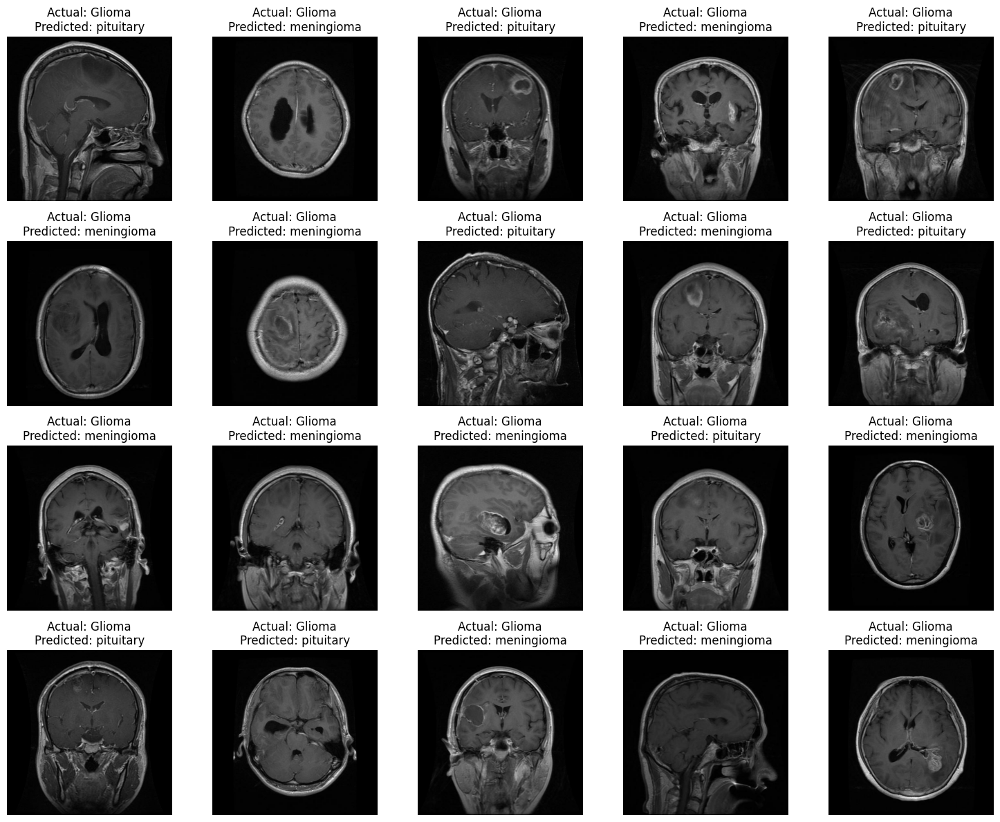

In [30]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

glioma_wrong = np.where(
    (y_true == 0) & (preds != 0)
)[0]

print("Misclassified glioma images:", len(glioma_wrong))

plt.figure(figsize=(15, 12))

for i, idx in enumerate(glioma_wrong[:20]):
    path = val_df.iloc[idx]["image"]

    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3)

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(
        f"Actual: Glioma\nPredicted: {CLASS_NAMES[preds[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
from PIL import Image
import pandas as pd

dimension_data = []

for _, row in df.iterrows():
    try:
        with Image.open(row["image"]) as img:
            dimension_data.append({
                "image": row["image"],
                "class": CLASS_NAMES[row["label"]],
                "width": img.size[0],
                "height": img.size[1],
                "mode": img.mode
            })
    except Exception as e:
        print("Error:", row["image"], e)

dimensions_df = pd.DataFrame(dimension_data)

print("Image dimension summary:")
print(dimensions_df.groupby("class")[["width", "height"]].describe())

print("\nImage modes:")
print(pd.crosstab(dimensions_df["class"], dimensions_df["mode"]))

Image dimension summary:
             width                                                      \
             count        mean         std    min    25%    50%    75%   
class                                                                    
glioma      1400.0  512.000000    0.000000  512.0  512.0  512.0  512.0   
meningioma  1400.0  495.413571   72.396156  180.0  512.0  512.0  512.0   
notumor     1400.0  313.550714  163.123901  150.0  218.0  230.0  400.0   
pituitary   1400.0  513.090714   84.585469  201.0  512.0  512.0  512.0   

                    height                                               \
               max   count        mean         std    min    25%    50%   
class                                                                     
glioma       512.0  1400.0  512.000000    0.000000  512.0  512.0  512.0   
meningioma  1275.0  1400.0  497.037857   69.353365  207.0  512.0  512.0   
notumor     1375.0  1400.0  327.355000  159.004225  168.0  225.0  244.0   
pituit

In [32]:
dimensions_df["aspect_ratio"] = (
    dimensions_df["width"] / dimensions_df["height"]
)

print("Aspect ratio statistics:\n")

print(
    dimensions_df.groupby("class")["aspect_ratio"]
    .describe()
    .round(3)
)

print("\nImages with unusual aspect ratios:")

print(
    dimensions_df[
        (dimensions_df["aspect_ratio"] < 0.75) |
        (dimensions_df["aspect_ratio"] > 1.33)
    ].groupby("class").size()
)

Aspect ratio statistics:

             count   mean    std    min   25%  50%  75%    max
class                                                         
glioma      1400.0  1.000  0.000  1.000  1.00  1.0  1.0  1.000
meningioma  1400.0  0.996  0.049  0.728  1.00  1.0  1.0  1.591
notumor     1400.0  0.958  0.146  0.645  0.86  1.0  1.0  1.786
pituitary   1400.0  1.000  0.014  0.798  1.00  1.0  1.0  1.215

Images with unusual aspect ratios:
class
meningioma    10
notumor       64
dtype: int64


In [33]:
def load_image_padded(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        224,
        224,
        method="bilinear"
    )

    return image, label


def create_padded_dataset(dataframe, shuffle=False):
    paths = dataframe["image"].values
    labels = dataframe["label"].values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image_padded,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(2000, seed=42)

    return ds.batch(32).prefetch(tf.data.AUTOTUNE)


train_pad_ds = create_padded_dataset(
    train_df, shuffle=True
)

val_pad_ds = create_padded_dataset(val_df)

print("Padded training batches:",
      tf.data.experimental.cardinality(train_pad_ds).numpy())

print("Padded validation batches:",
      tf.data.experimental.cardinality(val_pad_ds).numpy())

Padded training batches: 140
Padded validation batches: 35


In [34]:
padded_baseline_probs = baseline.predict(
    val_pad_ds,
    verbose=1
)

padded_baseline_pred = np.argmax(
    padded_baseline_probs,
    axis=1
)

y_true = val_df["label"].values

print(
    "Original preprocessing accuracy:",
    round(np.mean(baseline_pred == y_true) * 100, 2),
    "%"
)

print(
    "Padded preprocessing accuracy:",
    round(np.mean(padded_baseline_pred == y_true) * 100, 2),
    "%"
)

print("\nPadded preprocessing classification report:")

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    padded_baseline_pred,
    target_names=CLASS_NAMES,
    digits=4
))

35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step
Original preprocessing accuracy: 86.7 %
Padded preprocessing accuracy: 85.54 %

Padded preprocessing classification report:
              precision    recall  f1-score   support

      glioma     0.9237    0.8214    0.8696       280
  meningioma     0.8333    0.6429    0.7258       280
     notumor     0.9782    0.9607    0.9694       280
   pituitary     0.7342    0.9964    0.8455       280

    accuracy                         0.8554      1120
   macro avg     0.8674    0.8554    0.8525      1120
weighted avg     0.8674    0.8554    0.8525      1120



In [35]:
padded_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"
)

base = padded_model.get_layer("efficientnetb0")

for layer in base.layers:
    layer.trainable = False

for layer in base.layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

padded_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Padded model ready!")

Padded model ready!


In [36]:
padded_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/MEDVISION_AI_padded.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

padded_history = padded_model.fit(
    train_pad_ds,
    validation_data=val_pad_ds,
    epochs=8,
    callbacks=padded_callbacks
)

Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 134ms/step - accuracy: 0.8906 - loss: 0.2960 - val_accuracy: 0.8527 - val_loss: 0.3920
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - accuracy: 0.8866 - loss: 0.3072 - val_accuracy: 0.8509 - val_loss: 0.4002
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.8888 - loss: 0.2935 - val_accuracy: 0.8527 - val_loss: 0.3955
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 116ms/step - accuracy: 0.8949 - loss: 0.2888 - val_accuracy: 0.8589 - val_loss: 0.3793
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.8893 - loss: 0.2974 - val_accuracy: 0.8589 - val_loss: 0.3761
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - accuracy: 0.8940 - loss: 0.2901 - val_accuracy: 0.8580 - val_loss: 0.3816
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 114ms/step - accuracy: 0.8924 - loss: 0.2846 - val_accuracy: 0.8571 - val_loss: 0.3875
Epoch 8/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 125ms/step - accuracy: 0.8958 - loss: 0.2728 - 

35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step
PADDED MODEL CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9312    0.8214    0.8729       280
  meningioma     0.8426    0.6500    0.7339       280
     notumor     0.9748    0.9679    0.9713       280
   pituitary     0.7361    0.9964    0.8467       280

    accuracy                         0.8589      1120
   macro avg     0.8712    0.8589    0.8562      1120
weighted avg     0.8712    0.8589    0.8562      1120



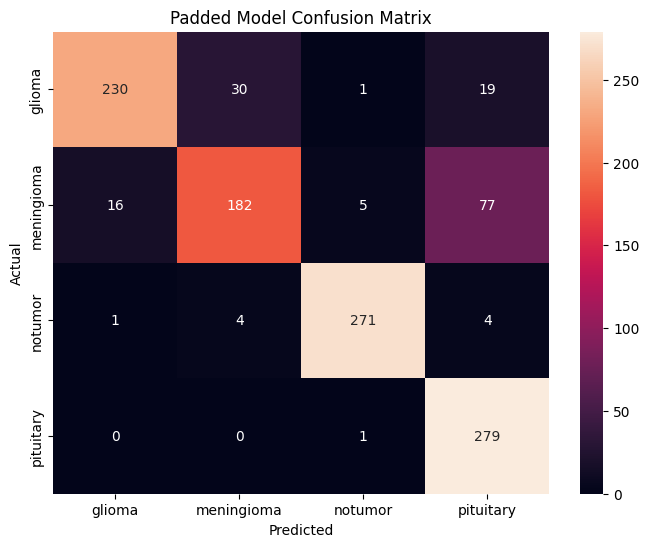

In [37]:
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

padded_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_padded.keras"
)

padded_probs = padded_model.predict(
    val_pad_ds, verbose=1
)

padded_pred = np.argmax(padded_probs, axis=1)

y_true = val_df["label"].values

print("PADDED MODEL CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    padded_pred,
    target_names=CLASS_NAMES,
    digits=4
))

cm = confusion_matrix(y_true, padded_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Padded Model Confusion Matrix")
plt.show()

In [38]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(1.0), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.0), np.int64(3): np.float64(1.0)}


In [39]:
import numpy as np

misclassified = np.where(
    (y_true == 1) & (padded_pred == 3)
)[0]

print("Meningioma predicted as pituitary:", len(misclassified))
print("\nFirst 10 validation image paths:")

for i in misclassified[:10]:
    print(val_df.iloc[i]["image"])

Meningioma predicted as pituitary: 77

First 10 validation image paths:
/content/medvision_dataset/Training/meningioma/Tr-me_239.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_1297.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_401.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_1147.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_1080.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_1012.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_1154.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_590.jpg
/content/medvision_dataset/Training/meningioma/Tr-me_263.jpg
/content/medvision_dataset/Training/meningioma/Tr-aug-me_82.jpg


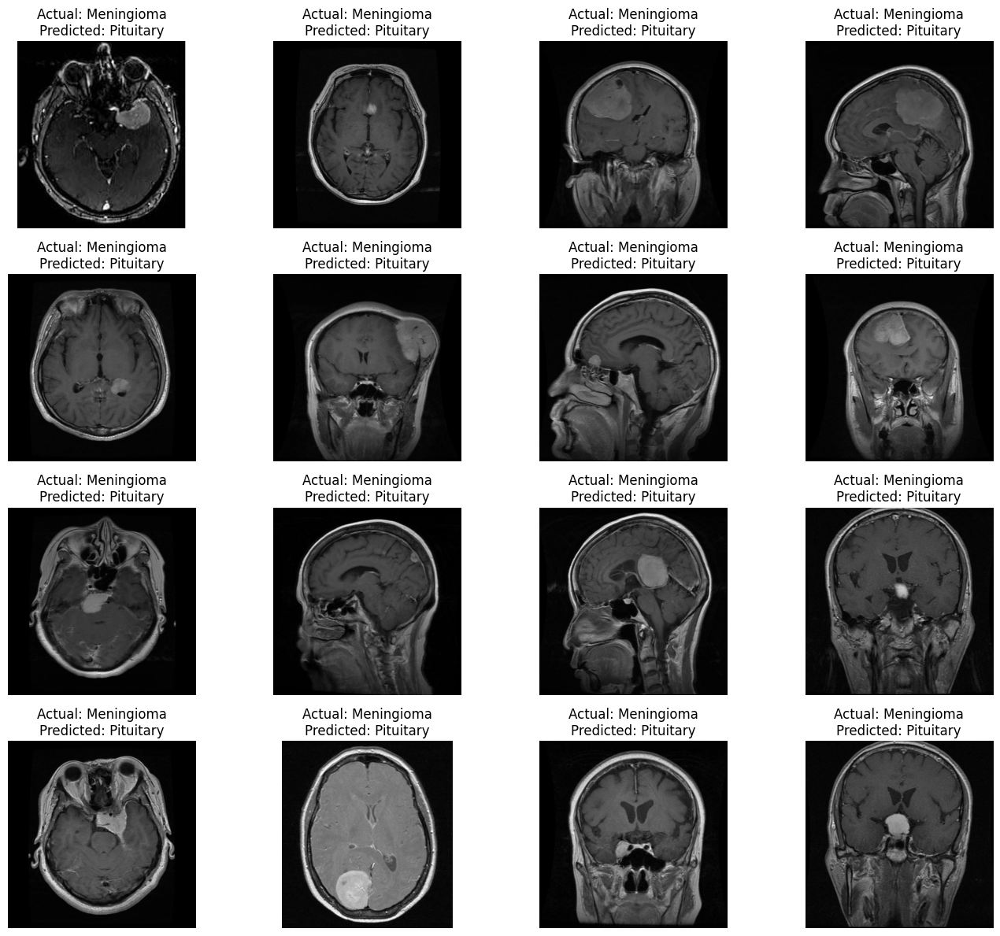

In [40]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(14, 12))

for j, idx in enumerate(misclassified[:16]):
    path = val_df.iloc[idx]["image"]
    img = Image.open(path).convert("RGB")

    plt.subplot(4, 4, j + 1)
    plt.imshow(img)
    plt.title(f"Actual: Meningioma\nPredicted: Pituitary")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
import os
import pandas as pd

for cls in CLASS_NAMES:
    folder = os.path.join(DATA_DIR, "Training", cls)
    files = os.listdir(folder)

    augmented = [f for f in files if "aug" in f.lower()]

    print(f"\n{cls.upper()}")
    print("Total images:", len(files))
    print("Augmented filename count:", len(augmented))
    print("Examples:", augmented[:10])


GLIOMA
Total images: 1400
Augmented filename count: 0
Examples: []

MENINGIOMA
Total images: 1400
Augmented filename count: 100
Examples: ['Tr-aug-me_62.jpg', 'Tr-aug-me_27.jpg', 'Tr-aug-me_80.jpg', 'Tr-aug-me_6.jpg', 'Tr-aug-me_75.jpg', 'Tr-aug-me_53.jpg', 'Tr-aug-me_95.jpg', 'Tr-aug-me_50.jpg', 'Tr-aug-me_45.jpg', 'Tr-aug-me_98.jpg']

NOTUMOR
Total images: 1400
Augmented filename count: 0
Examples: []

PITUITARY
Total images: 1400
Augmented filename count: 0
Examples: []


In [43]:
import os

folder = os.path.join(DATA_DIR, "Training", "meningioma")

augmented_files = [
    f for f in os.listdir(folder)
    if f.startswith("Tr-aug-me_")
]

paired = []
unpaired = []

for f in augmented_files:
    original = f.replace("Tr-aug-me_", "Tr-me_")

    if os.path.exists(os.path.join(folder, original)):
        paired.append((f, original))
    else:
        unpaired.append(f)

print("Augmented images:", len(augmented_files))
print("Matching original filenames:", len(paired))
print("No matching original filename:", len(unpaired))

print("\nFirst 15 pairs:")
for a, b in paired[:15]:
    print(a, "<->", b)

Augmented images: 100
Matching original filenames: 100
No matching original filename: 0

First 15 pairs:
Tr-aug-me_62.jpg <-> Tr-me_62.jpg
Tr-aug-me_27.jpg <-> Tr-me_27.jpg
Tr-aug-me_80.jpg <-> Tr-me_80.jpg
Tr-aug-me_6.jpg <-> Tr-me_6.jpg
Tr-aug-me_75.jpg <-> Tr-me_75.jpg
Tr-aug-me_53.jpg <-> Tr-me_53.jpg
Tr-aug-me_95.jpg <-> Tr-me_95.jpg
Tr-aug-me_50.jpg <-> Tr-me_50.jpg
Tr-aug-me_45.jpg <-> Tr-me_45.jpg
Tr-aug-me_98.jpg <-> Tr-me_98.jpg
Tr-aug-me_82.jpg <-> Tr-me_82.jpg
Tr-aug-me_44.jpg <-> Tr-me_44.jpg
Tr-aug-me_54.jpg <-> Tr-me_54.jpg
Tr-aug-me_40.jpg <-> Tr-me_40.jpg
Tr-aug-me_87.jpg <-> Tr-me_87.jpg


In [42]:
print("Augmented images in training split:")
print(train_df["image"].str.contains("aug", case=False).sum())

print("Augmented images in validation split:")
print(val_df["image"].str.contains("aug", case=False).sum())

Augmented images in training split:
80
Augmented images in validation split:
20


In [44]:
train_files = set(train_df["image"].apply(os.path.basename))
val_files = set(val_df["image"].apply(os.path.basename))

leakage_pairs = []

for aug, original in paired:
    if (aug in train_files and original in val_files) or \
       (aug in val_files and original in train_files):
        leakage_pairs.append((aug, original))

print("Original/augmented pairs across train-validation:", len(leakage_pairs))

for pair in leakage_pairs[:20]:
    print(pair)


Original/augmented pairs across train-validation: 30
('Tr-aug-me_98.jpg', 'Tr-me_98.jpg')
('Tr-aug-me_82.jpg', 'Tr-me_82.jpg')
('Tr-aug-me_44.jpg', 'Tr-me_44.jpg')
('Tr-aug-me_87.jpg', 'Tr-me_87.jpg')
('Tr-aug-me_52.jpg', 'Tr-me_52.jpg')
('Tr-aug-me_68.jpg', 'Tr-me_68.jpg')
('Tr-aug-me_43.jpg', 'Tr-me_43.jpg')
('Tr-aug-me_28.jpg', 'Tr-me_28.jpg')
('Tr-aug-me_90.jpg', 'Tr-me_90.jpg')
('Tr-aug-me_64.jpg', 'Tr-me_64.jpg')
('Tr-aug-me_63.jpg', 'Tr-me_63.jpg')
('Tr-aug-me_34.jpg', 'Tr-me_34.jpg')
('Tr-aug-me_60.jpg', 'Tr-me_60.jpg')
('Tr-aug-me_23.jpg', 'Tr-me_23.jpg')
('Tr-aug-me_18.jpg', 'Tr-me_18.jpg')
('Tr-aug-me_12.jpg', 'Tr-me_12.jpg')
('Tr-aug-me_93.jpg', 'Tr-me_93.jpg')
('Tr-aug-me_22.jpg', 'Tr-me_22.jpg')
('Tr-aug-me_74.jpg', 'Tr-me_74.jpg')
('Tr-aug-me_57.jpg', 'Tr-me_57.jpg')


In [45]:
import os

folder = os.path.join(DATA_DIR, "Training", "meningioma")

augmented_files = [
    f for f in os.listdir(folder)
    if f.startswith("Tr-aug-me_")
]

paired = []

for f in augmented_files:
    original = f.replace("Tr-aug-me_", "Tr-me_")

    if os.path.exists(os.path.join(folder, original)):
        paired.append((f, original))

print("Total augmented images:", len(augmented_files))
print("Matching original images:", len(paired))

Total augmented images: 100
Matching original images: 100


In [46]:
train_files = set(train_df["image"].apply(os.path.basename))
val_files = set(val_df["image"].apply(os.path.basename))

leakage_pairs = []

for aug, original in paired:
    if (aug in train_files and original in val_files) or \
       (aug in val_files and original in train_files):
        leakage_pairs.append((aug, original))

print("Cross-split image pairs:", len(leakage_pairs))

for pair in leakage_pairs:
    print(pair)

Cross-split image pairs: 30
('Tr-aug-me_98.jpg', 'Tr-me_98.jpg')
('Tr-aug-me_82.jpg', 'Tr-me_82.jpg')
('Tr-aug-me_44.jpg', 'Tr-me_44.jpg')
('Tr-aug-me_87.jpg', 'Tr-me_87.jpg')
('Tr-aug-me_52.jpg', 'Tr-me_52.jpg')
('Tr-aug-me_68.jpg', 'Tr-me_68.jpg')
('Tr-aug-me_43.jpg', 'Tr-me_43.jpg')
('Tr-aug-me_28.jpg', 'Tr-me_28.jpg')
('Tr-aug-me_90.jpg', 'Tr-me_90.jpg')
('Tr-aug-me_64.jpg', 'Tr-me_64.jpg')
('Tr-aug-me_63.jpg', 'Tr-me_63.jpg')
('Tr-aug-me_34.jpg', 'Tr-me_34.jpg')
('Tr-aug-me_60.jpg', 'Tr-me_60.jpg')
('Tr-aug-me_23.jpg', 'Tr-me_23.jpg')
('Tr-aug-me_18.jpg', 'Tr-me_18.jpg')
('Tr-aug-me_12.jpg', 'Tr-me_12.jpg')
('Tr-aug-me_93.jpg', 'Tr-me_93.jpg')
('Tr-aug-me_22.jpg', 'Tr-me_22.jpg')
('Tr-aug-me_74.jpg', 'Tr-me_74.jpg')
('Tr-aug-me_57.jpg', 'Tr-me_57.jpg')
('Tr-aug-me_10.jpg', 'Tr-me_10.jpg')
('Tr-aug-me_8.jpg', 'Tr-me_8.jpg')
('Tr-aug-me_42.jpg', 'Tr-me_42.jpg')
('Tr-aug-me_69.jpg', 'Tr-me_69.jpg')
('Tr-aug-me_100.jpg', 'Tr-me_100.jpg')
('Tr-aug-me_41.jpg', 'Tr-me_41.jpg')
('Tr-aug-m

In [47]:
print("TRAINING DISTRIBUTION")
print(train_df["label"].value_counts().sort_index())

print("\nVALIDATION DISTRIBUTION")
print(val_df["label"].value_counts().sort_index())

print("\nCLASS MAPPING")
for i, name in enumerate(CLASS_NAMES):
    print(i, "=", name)

TRAINING DISTRIBUTION
label
0    1120
1    1120
2    1120
3    1120
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
0    280
1    280
2    280
3    280
Name: count, dtype: int64

CLASS MAPPING
0 = glioma
1 = meningioma
2 = notumor
3 = pituitary


In [48]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

baseline_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_FINAL.keras"
)

baseline_probs = baseline_model.predict(val_ds, verbose=1)
baseline_pred = np.argmax(baseline_probs, axis=1)

y_true = val_df["label"].values

print(classification_report(
    y_true,
    baseline_pred,
    target_names=CLASS_NAMES,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, baseline_pred))

35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step
              precision    recall  f1-score   support

      glioma     0.9465    0.8214    0.8795       280
  meningioma     0.8489    0.6821    0.7564       280
     notumor     0.9783    0.9679    0.9731       280
   pituitary     0.7440    0.9964    0.8519       280

    accuracy                         0.8670      1120
   macro avg     0.8794    0.8670    0.8652      1120
weighted avg     0.8794    0.8670    0.8652      1120

Confusion Matrix:
[[230  31   1  18]
 [ 12 191   4  73]
 [  1   3 271   5]
 [  0   0   1 279]]


In [49]:
import json

results = {
    "model": "EfficientNetB0 Baseline",
    "validation_accuracy": float(np.mean(baseline_pred == y_true)),
    "classification_report": classification_report(
        y_true,
        baseline_pred,
        target_names=CLASS_NAMES,
        output_dict=True
    ),
    "confusion_matrix": confusion_matrix(
        y_true,
        baseline_pred
    ).tolist()
}

with open("/content/drive/MyDrive/MEDVISION_AI_evaluation.json", "w") as f:
    json.dump(results, f, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [50]:
import os
import re
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

data = []

for label, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, "Training", cls)

    for file in sorted(os.listdir(folder)):
        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        if cls == "meningioma":
            match = re.match(r"Tr-(?:aug-)?me_(\d+)", file)

            if match:
                group = f"meningioma_{match.group(1)}"
            else:
                group = path
        else:
            group = path

        data.append({
            "image": path,
            "label": label,
            "group": group
        })

full_df = pd.DataFrame(data)

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf.split(
        full_df["image"],
        full_df["label"],
        groups=full_df["group"]
    )
)

train_df = full_df.iloc[train_idx].reset_index(drop=True)
val_df = full_df.iloc[val_idx].reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nGroups crossing splits:",
      len(set(train_df["group"]) & set(val_df["group"])))

Training images: 4479
Validation images: 1121

Training distribution:
label
0    1119
1    1120
2    1120
3    1120
Name: count, dtype: int64

Validation distribution:
label
0    281
1    280
2    280
3    280
Name: count, dtype: int64

Groups crossing splits: 0


In [51]:
train_groups = set(train_df["group"])
val_groups = set(val_df["group"])

assert train_groups.isdisjoint(val_groups)

for aug, original in paired:
    aug_group = next(
        (g for g in full_df.loc[
            full_df["image"].str.endswith(aug), "group"
        ].values),
        None
    )

    original_group = next(
        (g for g in full_df.loc[
            full_df["image"].str.endswith(original), "group"
        ].values),
        None
    )

    assert aug_group == original_group

print("Dataset grouping verification passed!")
print("No original/augmented groups cross training and validation.")

Dataset grouping verification passed!
No original/augmented groups cross training and validation.


In [52]:
import tensorflow as tf
import numpy as np
import os

IMG_SIZE = 224
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def create_dataset(dataframe, shuffle=False):
    paths = dataframe["image"].values
    labels = dataframe["label"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(
            2000,
            seed=42,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)

print("Training and validation datasets created!")

Training and validation datasets created!


In [53]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(4, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [54]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/MEDVISION_AI_clean_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 80s 311ms/step - accuracy: 0.6412 - loss: 0.9226 - val_accuracy: 0.7172 - val_loss: 0.6913
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 63ms/step - accuracy: 0.7770 - loss: 0.5785 - val_accuracy: 0.8314 - val_loss: 0.4930
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 78ms/step - accuracy: 0.8348 - loss: 0.4611 - val_accuracy: 0.8483 - val_loss: 0.4169
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 71ms/step - accuracy: 0.8551 - loss: 0.4059 - val_accuracy: 0.8555 - val_loss: 0.3857
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8656 - loss: 0.3600 - val_accuracy: 0.8617 - val_loss: 0.3599
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.8667 - loss: 0.3595 - val_accuracy: 0.8742 - val_loss: 0.3481
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - accuracy: 0.8736 - loss: 0.3361 - val_accuracy: 0.8751 - val_loss: 0.3272
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8832 - loss: 0.3111 -

In [55]:
base_model = model.get_layer("efficientnetb0")

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Total trainable layers:",
      sum(layer.trainable for layer in model.layers))

print("EfficientNet fine-tuning configured!")

Total trainable layers: 7
EfficientNet fine-tuning configured!


In [56]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/MEDVISION_AI_clean_finetuned.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 74s 289ms/step - accuracy: 0.8955 - loss: 0.2744 - val_accuracy: 0.8822 - val_loss: 0.2970
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 79ms/step - accuracy: 0.8977 - loss: 0.2739 - val_accuracy: 0.8876 - val_loss: 0.2818
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8998 - loss: 0.2655 - val_accuracy: 0.8992 - val_loss: 0.2605
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.9109 - loss: 0.2425 - val_accuracy: 0.9019 - val_loss: 0.2608
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 74ms/step - accuracy: 0.9085 - loss: 0.2343 - val_accuracy: 0.9019 - val_loss: 0.2581
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9176 - loss: 0.2235 - val_accuracy: 0.9099 - val_loss: 0.2349
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.9183 - loss: 0.2175 - val_accuracy: 0.9099 - val_loss: 0.2348
Epoch 8/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9241 - loss: 0.2017 - val_acc

36/36 ━━━━━━━━━━━━━━━━━━━━ 17s 268ms/step
FINAL MODEL — VALIDATION CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma     0.9492    0.8648    0.9050       281
  meningioma     0.8304    0.8393    0.8348       280
     notumor     0.9713    0.9679    0.9696       280
   pituitary     0.8944    0.9679    0.9297       280

    accuracy                         0.9099      1121
   macro avg     0.9113    0.9099    0.9098      1121
weighted avg     0.9114    0.9099    0.9098      1121



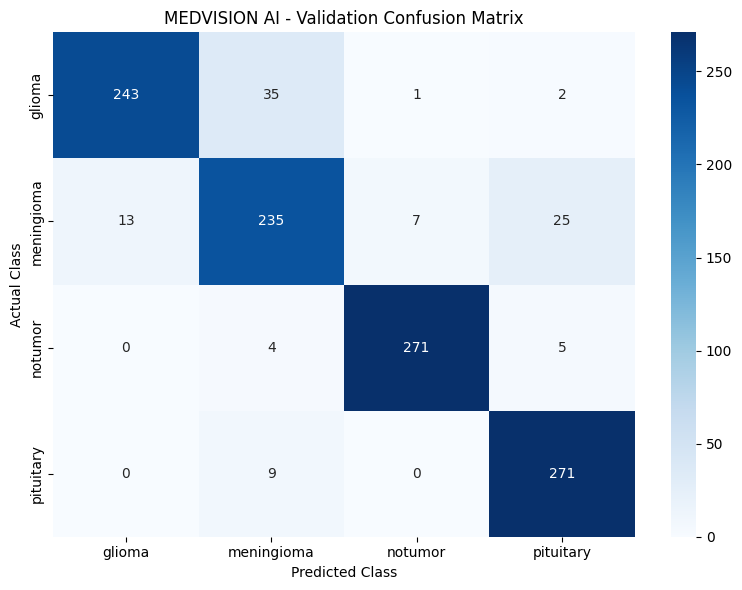

Validation accuracy: 90.99 %


In [57]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Load best fine-tuned checkpoint
final_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_clean_finetuned.keras"
)

# Predictions
predictions = final_model.predict(val_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = val_df["label"].values

# Classification report
print("FINAL MODEL — VALIDATION CLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MEDVISION AI - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("Validation accuracy:", round(np.mean(y_true == y_pred) * 100, 2), "%")

In [58]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

              precision    recall  f1-score   support

      glioma     0.9492    0.8648    0.9050       281
  meningioma     0.8304    0.8393    0.8348       280
     notumor     0.9713    0.9679    0.9696       280
   pituitary     0.8944    0.9679    0.9297       280

    accuracy                         0.9099      1121
   macro avg     0.9113    0.9099    0.9098      1121
weighted avg     0.9114    0.9099    0.9098      1121



In [59]:
import tensorflow as tf
import json

final_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MEDVISION_AI_clean_finetuned.keras"
)

final_model.save(
    "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"
)

classes = {
    str(i): name for i, name in enumerate(CLASS_NAMES)
}

with open(
    "/content/drive/MyDrive/MEDVISION_AI_classes.json", "w"
) as f:
    json.dump(classes, f, indent=4)

print("Final model saved successfully!")
print("Class mapping saved successfully!")

Final model saved successfully!
Class mapping saved successfully!


In [60]:
import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
from PIL import Image
import json

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

print("MEDVISION AI model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

MEDVISION AI model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)


In [61]:
def make_gradcam(model, image, class_index=None):
    base = model.get_layer("efficientnetb0")

    feature_model = tf.keras.Model(
        inputs=base.input,
        outputs=[
            base.get_layer("top_conv").output,
            base.output
        ]
    )

    pooling = model.get_layer("global_average_pooling2d")
    dropout1 = model.get_layer("dropout")
    dense1 = model.get_layer("dense")
    dropout2 = model.get_layer("dropout_1")
    classifier = model.get_layer("dense_1")

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(image, training=False)

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]

In [62]:
def generate_mri_report(prediction, confidence):
    descriptions = {
        "glioma": "The model classified this MRI image as glioma.",
        "meningioma": "The model classified this MRI image as meningioma.",
        "notumor": "The model classified this MRI image as no tumor.",
        "pituitary": "The model classified this MRI image as pituitary tumor."
    }

    report = f"""
MEDVISION AI
BRAIN MRI ANALYSIS REPORT
========================================

1. AI CLASSIFICATION

Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

{descriptions[prediction]}

2. CLASS PROBABILITY DISTRIBUTION

"""

    for i, name in enumerate(CLASS_NAMES):
        report += f"{name.upper():15s}: {probabilities[i] * 100:.2f}%\n"

    report += """
3. IMAGE EXPLANATION

Grad-CAM visualization highlights image regions
that contributed to the model's prediction.

The heatmap is an AI explanation visualization.
It does not establish tumor boundaries or location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Classification Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS AND DISCLAIMER

This application is an academic AI research prototype.

It is not a clinically validated diagnostic system.
Predictions must not be used as a substitute for
radiologist interpretation or medical examination.

The model does not determine tumor grade, exact
location, dimensions, volume, or clinical severity.

A qualified medical professional must interpret
the MRI scan and make all clinical decisions.

========================================
Generated by MEDVISION AI
"""

    return report

In [63]:
def analyze_mri(image):
    if image is None:
        return None, None, "Please upload a brain MRI image."

    image = image.convert("RGB")

    original = np.array(image)

    resized = cv2.resize(original, (224, 224))

    input_image = np.expand_dims(
        resized.astype("float32"),
        axis=0
    )

    heatmap, probabilities = make_gradcam(
        model,
        input_image
    )

    predicted_index = int(np.argmax(probabilities))
    prediction = CLASS_NAMES[predicted_index]

    confidence = float(probabilities[predicted_index]) * 100

    scores = {
        CLASS_NAMES[i]: float(probabilities[i])
        for i in range(len(CLASS_NAMES))
    }

    # Generate Grad-CAM overlay
    heatmap = cv2.resize(
        heatmap,
        (original.shape[1], original.shape[0])
    )

    heatmap = np.uint8(255 * heatmap)

    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    report = generate_mri_report(
        prediction,
        confidence
    )

    # Insert actual probabilities into report
    probability_text = "\n".join(
        f"{name.upper():15s}: {scores[name] * 100:.2f}%"
        for name in CLASS_NAMES
    )

    report = report.replace(
        "\n4. MODEL INFORMATION",
        "\n" + probability_text + "\n\n4. MODEL INFORMATION"
    )

    return scores, overlay, report

In [64]:
analyze_btn.click(
    fn=analyze_mri,
    inputs=mri_input,
    outputs=[
        label_output,
        gradcam_output,
        report_output
    ]
)

NameError: name 'analyze_btn' is not defined

In [65]:
import gradio as gr

mri_input = gr.Image(
    type="pil",
    label="Upload Brain MRI"
)

label_output = gr.Label(
    label="Classification Results"
)

gradcam_output = gr.Image(
    label="Grad-CAM Visualization"
)

report_output = gr.Textbox(
    label="MRI Analysis Report",
    lines=22,
    interactive=False
)

analyze_btn = gr.Button(
    "Analyze MRI",
    variant="primary"
)

with gr.Blocks(title="MEDVISION AI") as demo:
    gr.Markdown("# MEDVISION AI")
    gr.Markdown("### Brain MRI Classification and AI Analysis")

    with gr.Row():
        mri_input.render()

        with gr.Column():
            analyze_btn.render()
            label_output.render()

    with gr.Row():
        gradcam_output.render()
        report_output.render()

    analyze_btn.click(
        fn=analyze_mri,
        inputs=mri_input,
        outputs=[
            label_output,
            gradcam_output,
            report_output
        ]
    )

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [66]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e3ec2bfa0ae5f8e963.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [67]:
def generate_mri_report(prediction, confidence, probabilities):
    descriptions = {
        "glioma": "Classified as glioma by the AI model.",
        "meningioma": "Classified as meningioma by the AI model.",
        "notumor": "Classified as no tumor by the AI model.",
        "pituitary": "Classified as pituitary tumor by the AI model."
    }

    probability_text = "\n".join(
        f"{name.upper():15s}: {probabilities[i] * 100:.2f}%"
        for i, name in enumerate(CLASS_NAMES)
    )

    return f"""
MEDVISION AI
BRAIN MRI ANALYSIS REPORT
========================================

1. AI CLASSIFICATION

Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

{descriptions[prediction]}

2. CLASS PROBABILITY DISTRIBUTION

{probability_text}

3. GRAD-CAM EXPLANATION

The heatmap highlights image regions contributing
to the model's prediction.

It does not establish tumor boundaries or location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Classification Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS

This is an academic AI research prototype.
It is not a clinically validated diagnostic system.

It does not determine tumor grade, dimensions,
volume, or clinical severity.

A qualified medical professional must interpret
the MRI scan and make clinical decisions.

========================================
Generated by MEDVISION AI
"""

In [68]:
def analyze_mri(image):
    if image is None:
        return None, None, "Please upload an MRI image."

    image = image.convert("RGB")
    original = np.array(image)
    resized = cv2.resize(original, (224, 224))

    input_image = np.expand_dims(
        resized.astype("float32"), axis=0
    )

    heatmap, probabilities = make_gradcam(
        model, input_image
    )

    predicted_index = int(np.argmax(probabilities))
    prediction = CLASS_NAMES[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    scores = {
        CLASS_NAMES[i]: float(probabilities[i])
        for i in range(4)
    }

    heatmap = cv2.resize(
        heatmap,
        (original.shape[1], original.shape[0])
    )

    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(
        heatmap, cv2.COLORMAP_JET
    )

    overlay = cv2.addWeighted(
        original, 0.6, heatmap_color, 0.4, 0
    )

    report = generate_mri_report(
        prediction, confidence, probabilities
    )

    return scores, overlay, report

In [69]:
test_image = Image.open(
    val_df.iloc[0]["image"]
).convert("RGB")

test_result = analyze_mri(test_image)

print("Prediction:", test_result[0])
print("Report:\n", test_result[2])

Prediction: {'glioma': 0.9888613820075989, 'meningioma': 0.008722673170268536, 'notumor': 0.0016745788743719459, 'pituitary': 0.0007414094870910048}
Report:
 
MEDVISION AI
BRAIN MRI ANALYSIS REPORT

1. AI CLASSIFICATION

Predicted Category: GLIOMA
Model Confidence: 98.89%

Classified as glioma by the AI model.

2. CLASS PROBABILITY DISTRIBUTION

GLIOMA         : 98.89%
MENINGIOMA     : 0.87%
NOTUMOR        : 0.17%
PITUITARY      : 0.07%

3. GRAD-CAM EXPLANATION

The heatmap highlights image regions contributing
to the model's prediction.

It does not establish tumor boundaries or location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Classification Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS

This is an academic AI research prototype.
It is not a clinically validated diagnostic system.

It does not determine tumor grade, dimensions,
volume, or clinical severity.

A qualified medical professional must interp

In [70]:
print(test_result[2][-150:])
print("Report length:", len(test_result[2]))

ied medical professional must interpret
the MRI scan and make clinical decisions.

Generated by MEDVISION AI

Report length: 997


In [71]:
demo.close()

Closing server running on port: 7861


In [72]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e3ec2bfa0ae5f8e963.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [75]:
import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
from PIL import Image
from datetime import datetime

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded:", model.input_shape, model.output_shape)

# GRAD-CAM
base = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer("top_conv").output,
        base.output
    ]
)

pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")

def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(
            image, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(conv_output * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# REPORT GENERATION
def generate_report(prediction, confidence, probabilities):
    probability_text = "\n".join(
        f"{name.upper():15s}: {probabilities[i]*100:.2f}%"
        for i, name in enumerate(CLASS_NAMES)
    )

    return f"""
MEDVISION AI
BRAIN MRI ANALYSIS REPORT
========================================

Report Date: {datetime.now().strftime("%d-%m-%Y %H:%M")}

1. AI CLASSIFICATION

Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

2. CLASS PROBABILITIES

{probability_text}

3. GRAD-CAM EXPLANATION

The heatmap highlights image regions that
contributed to the model's prediction.

It does not establish tumor boundaries or
anatomical location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Number of Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS

This is an academic AI research prototype.
It is not a clinically validated diagnostic system.

It does not determine tumor grade, dimensions,
volume, or clinical severity.

A qualified medical professional must interpret
the MRI scan and make clinical decisions.

========================================
Generated by MEDVISION AI
"""


# MAIN MRI ANALYSIS
def analyze_mri(image):
    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:
        if isinstance(image, np.ndarray):
            image = Image.fromarray(image.astype("uint8"))

        image = image.convert("RGB")
        original = np.array(image)

        resized = cv2.resize(original, (224, 224))
        input_image = np.expand_dims(
            resized.astype("float32"), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]
        confidence = float(probabilities[predicted_index]) * 100

        scores = {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(4)
        }

        heatmap = cv2.resize(
            heatmap,
            (original.shape[1], original.shape[0])
        )

        heatmap = np.uint8(255 * heatmap)
        heatmap_color = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            original, 0.6, heatmap_color, 0.4, 0
        )

        report = generate_report(
            prediction, confidence, probabilities
        )

        return scores, overlay, report

    except Exception as e:
        import traceback
        traceback.print_exc()
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# NEW GRADIO INTERFACE
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="MEDVISION AI"
) as demo:

    gr.Markdown("# 🧠 MEDVISION AI")
    gr.Markdown("### Brain MRI Classification and AI Analysis")
    gr.Markdown(
        "Upload a brain MRI image to generate an AI-based "
        "classification and visual explanation."
    )

    with gr.Row():
        mri_input = gr.Image(
            type="pil",
            label="Upload Brain MRI"
        )

    analyze_btn = gr.Button(
        "Analyze MRI",
        variant="primary"
    )

    with gr.Row():
        label_output = gr.Label(
            label="Classification Results"
        )

        gradcam_output = gr.Image(
            label="Grad-CAM Visualization"
        )

    report_output = gr.Textbox(
        label="MRI Analysis Report",
        lines=24,
        interactive=False
    )

    analyze_btn.click(
        fn=analyze_mri,
        inputs=mri_input,
        outputs=[
            label_output,
            gradcam_output,

import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
from PIL import Image
from datetime import datetime

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded:", model.input_shape, model.output_shape)

# GRAD-CAM
base = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer("top_conv").output,
        base.output
    ]
)

pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")

def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(
            image, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(conv_output * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# REPORT GENERATION
def generate_report(prediction, confidence, probabilities):
    probability_text = "\n".join(
        f"{name.upper():15s}: {probabilities[i]*100:.2f}%"
        for i, name in enumerate(CLASS_NAMES)
    )

    return f"""
MEDVISION AI
BRAIN MRI ANALYSIS REPORT
========================================

Report Date: {datetime.now().strftime("%d-%m-%Y %H:%M")}

1. AI CLASSIFICATION

Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

2. CLASS PROBABILITIES

{probability_text}

3. GRAD-CAM EXPLANATION

The heatmap highlights image regions that
contributed to the model's prediction.

It does not establish tumor boundaries or
anatomical location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Number of Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS

This is an academic AI research prototype.
It is not a clinically validated diagnostic system.

It does not determine tumor grade, dimensions,
volume, or clinical severity.

A qualified medical professional must interpret
the MRI scan and make clinical decisions.

========================================
Generated by MEDVISION AI
"""


# MAIN MRI ANALYSIS
def analyze_mri(image):
    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:
        if isinstance(image, np.ndarray):
            image = Image.fromarray(image.astype("uint8"))

        image = image.convert("RGB")
        original = np.array(image)

        resized = cv2.resize(original, (224, 224))
        input_image = np.expand_dims(
            resized.astype("float32"), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]
        confidence = float(probabilities[predicted_index]) * 100

        scores = {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(4)
        }

        heatmap = cv2.resize(
            heatmap,
            (original.shape[1], original.shape[0])
        )

        heatmap = np.uint8(255 * heatmap)
        heatmap_color = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            original, 0.6, heatmap_color, 0.4, 0
        )

        report = generate_report(
            prediction, confidence, probabilities
        )

        return scores, overlay, report

    except Exception as e:
        import traceback
        traceback.print_exc()
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# NEW GRADIO INTERFACE
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="MEDVISION AI"
) as demo:

    gr.Markdown("# 🧠 MEDVISION AI")
    gr.Markdown("### Brain MRI Classification and AI Analysis")
    gr.Markdown(
        "Upload a brain MRI image to generate an AI-based "
        "classification and visual explanation."
    )

    with gr.Row():
        mri_input = gr.Image(
            type="pil",
            label="Upload Brain MRI"
        )

    analyze_btn = gr.Button(
        "Analyze MRI",
        variant="primary"
    )

    with gr.Row():
        label_output = gr.Label(
            label="Classification Results"
        )

        gradcam_output = gr.Image(
            label="Grad-CAM Visualization"
        )

    report_output = gr.Textbox(
        label="MRI Analysis Report",
        lines=24,
        interactive=False
    )

    analyze_btn.click(
        fn=analyze_mri,
        inputs=mri_input,
        outputs=[
            label_output,
            gradcam_output,
            report_output
        ]
    )

print("MEDVISION AI interface created successfully!")

demo.launch(share=True)
        report_output
        ]
    )

print("MEDVISION AI interface created successfully!")

demo.launch(share=True)


SyntaxError: invalid syntax (1655384663.py, line 217)

In [ ]:

import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
from PIL import Image
from datetime import datetime

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded:", model.input_shape, model.output_shape)

# GRAD-CAM
base = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer("top_conv").output,
        base.output
    ]
)

pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")

def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(
            image, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_output)

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(conv_output * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# REPORT GENERATION
def generate_report(prediction, confidence, probabilities):
    probability_text = "\n".join(
        f"{name.upper():15s}: {probabilities[i]*100:.2f}%"
        for i, name in enumerate(CLASS_NAMES)
    )

    return f"""
MEDVISION AI
BRAIN MRI ANALYSIS REPORT
========================================

Report Date: {datetime.now().strftime("%d-%m-%Y %H:%M")}

1. AI CLASSIFICATION

Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

2. CLASS PROBABILITIES

{probability_text}

3. GRAD-CAM EXPLANATION

The heatmap highlights image regions that
contributed to the model's prediction.

It does not establish tumor boundaries or
anatomical location.

4. MODEL INFORMATION

Architecture: EfficientNetB0
Input Resolution: 224 x 224
Number of Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-score: 90.98%

5. LIMITATIONS

This is an academic AI research prototype.
It is not a clinically validated diagnostic system.

It does not determine tumor grade, dimensions,
volume, or clinical severity.

A qualified medical professional must interpret
the MRI scan and make clinical decisions.

========================================
Generated by MEDVISION AI
"""


# MAIN MRI ANALYSIS
def analyze_mri(image):
    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:
        if isinstance(image, np.ndarray):
            image = Image.fromarray(image.astype("uint8"))

        image = image.convert("RGB")
        original = np.array(image)

        resized = cv2.resize(original, (224, 224))
        input_image = np.expand_dims(
            resized.astype("float32"), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]
        confidence = float(probabilities[predicted_index]) * 100

        scores = {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(4)
        }

        heatmap = cv2.resize(
            heatmap,
            (original.shape[1], original.shape[0])
        )

        heatmap = np.uint8(255 * heatmap)
        heatmap_color = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            original, 0.6, heatmap_color, 0.4, 0
        )

        report = generate_report(
            prediction, confidence, probabilities
        )

        return scores, overlay, report

    except Exception as e:
        import traceback
        traceback.print_exc()
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# NEW GRADIO INTERFACE
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="MEDVISION AI"
) as demo:

    gr.Markdown("# 🧠 MEDVISION AI")
    gr.Markdown("### Brain MRI Classification and AI Analysis")
    gr.Markdown(
        "Upload a brain MRI image to generate an AI-based "
        "classification and visual explanation."
    )

    with gr.Row():
        mri_input = gr.Image(
            type="pil",
            label="Upload Brain MRI"
        )

    analyze_btn = gr.Button(
        "Analyze MRI",
        variant="primary"
    )

    with gr.Row():
        label_output = gr.Label(
            label="Classification Results"
        )

        gradcam_output = gr.Image(
            label="Grad-CAM Visualization"
        )

    report_output = gr.Textbox(
        label="MRI Analysis Report",
        lines=24,
        interactive=False
    )

    analyze_btn.click(
        fn=analyze_mri,
        inputs=mri_input,
        outputs=[
            label_output,
            gradcam_output,
            report_output
        ]
    )

print("MEDVISION AI interface created successfully!")

demo.launch(share=True)

In [1]:
import os
import tensorflow as tf

print("TENSORFLOW:", tf.__version__)
print("MODEL FILE EXISTS:", os.path.exists("/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"))
print("GRADIO INSTALLED:", end=" ")

try:
    import gradio as gr
    print(gr.__version__)
except Exception as e:
    print(e)

print("\nGOOGLE DRIVE:")
print(os.path.exists("/content/drive/MyDrive"))

print("\nSAVED MODEL FILES:")
if os.path.exists("/content/drive/MyDrive"):
    for f in os.listdir("/content/drive/MyDrive"):
        if "MEDVISION_AI" in f:
            print(f)

TENSORFLOW: 2.21.0
MODEL FILE EXISTS: True
GRADIO INSTALLED: 6.31.0

GOOGLE DRIVE:
True

SAVED MODEL FILES:
MEDVISION_AI_stageA_best.keras
MEDVISION_AI_best_finetuned.keras
MEDVISION_AI_normalized.keras
MEDVISION_AI_FINAL.keras
MEDVISION_AI_weighted.keras
MEDVISION_AI_padded.keras
MEDVISION_AI_evaluation.json
MEDVISION_AI_clean_best.keras
MEDVISION_AI_clean_finetuned.keras
MEDVISION_AI_FINAL_V2.keras
MEDVISION_AI_classes.json


In [2]:
import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
from PIL import Image
import os

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

print("MODEL LOADED SUCCESSFULLY")
print("Input:", model.input_shape)
print("Output:", model.output_shape)

print("\nMODEL LAYERS:")
for layer in model.layers:
    print(layer.name, layer.output.shape if hasattr(layer.output, "shape") else "")

MODEL LOADED SUCCESSFULLY
Input: (None, 224, 224, 3)
Output: (None, 4)

MODEL LAYERS:
input_layer_1 (None, 224, 224, 3)
efficientnetb0 (None, 7, 7, 1280)
global_average_pooling2d (None, 1280)
dropout (None, 1280)
dense (None, 256)
dropout_1 (None, 256)
dense_1 (None, 4)


In [3]:
import tensorflow as tf
import numpy as np
import cv2
from PIL import Image

base = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer("top_conv").output,
        base.output
    ]
)

pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")


def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(
            image, training=False
        )

        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM gradients could not be calculated.")

    weights = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


print("Grad-CAM initialized successfully!")

Grad-CAM initialized successfully!


In [4]:
test_path = val_df.iloc[0]["image"]

test_image = Image.open(test_path).convert("RGB")
original = np.array(test_image)

resized = cv2.resize(original, (224, 224))
input_image = np.expand_dims(
    resized.astype("float32"), axis=0
)

heatmap, probabilities = make_gradcam(input_image)

predicted_index = np.argmax(probabilities)

print("Predicted class:", CLASS_NAMES[predicted_index])
print("Confidence:", round(float(probabilities[predicted_index]) * 100, 2), "%")

heatmap_resized = cv2.resize(
    heatmap, (original.shape[1], original.shape[0])
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    original, 0.6, heatmap_color, 0.4, 0
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("MEDVISION AI - Grad-CAM")
plt.axis("off")

plt.show()

NameError: name 'val_df' is not defined

In [5]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

TEST_FOLDER = "/content/medvision_dataset/Training/glioma"

if not os.path.exists(TEST_FOLDER):
    raise FileNotFoundError("Dataset folder not found. We need to extract archive.zip again.")

files = [
    f for f in os.listdir(TEST_FOLDER)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

if not files:
    raise ValueError("No MRI images found.")

test_path = os.path.join(TEST_FOLDER, sorted(files)[0])

test_image = Image.open(test_path).convert("RGB")
original = np.array(test_image)

resized = cv2.resize(original, (224, 224))
input_image = np.expand_dims(
    resized.astype("float32"), axis=0
)

heatmap, probabilities = make_gradcam(input_image)

predicted_index = np.argmax(probabilities)

print("Image:", test_path)
print("Predicted class:", CLASS_NAMES[predicted_index])
print("Confidence:", round(float(probabilities[predicted_index]) * 100, 2), "%")

heatmap_resized = cv2.resize(
    heatmap, (original.shape[1], original.shape[0])
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    original, 0.6, heatmap_color, 0.4, 0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("MEDVISION AI Grad-CAM")
plt.axis("off")

plt.show()

FileNotFoundError: Dataset folder not found. We need to extract archive.zip again.

In [1]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/archive.zip"
DATA_DIR = "/content/medvision_dataset"

if not os.path.exists(os.path.join(DATA_DIR, "Training")):
    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

    print("Dataset restored!")

else:
    print("Dataset already available!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting dataset...
Dataset restored!


In [2]:
import os

DATA_DIR = "/content/medvision_dataset"

for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
    folder = os.path.join(DATA_DIR, "Training", cls)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(cls, ":", len(images))

glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400


In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

folder = "/content/medvision_dataset/Training/glioma"

files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

test_image = Image.open(
    os.path.join(folder, files[0])
).convert("RGB")

original = np.array(test_image)
resized = cv2.resize(original, (224, 224))

input_image = np.expand_dims(
    resized.astype("float32"), axis=0
)

heatmap, probabilities = make_gradcam(input_image)

prediction = CLASS_NAMES[np.argmax(probabilities)]

print("Predicted class:", prediction)
print("Confidence:", round(float(np.max(probabilities)) * 100, 2), "%")

heatmap = cv2.resize(
    heatmap, (original.shape[1], original.shape[0])
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap), cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    original, 0.6, heatmap_color, 0.4, 0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

NameError: name 'make_gradcam' is not defined

MODEL LOADED SUCCESSFULLY
Predicted class: glioma
Confidence: 98.89 %


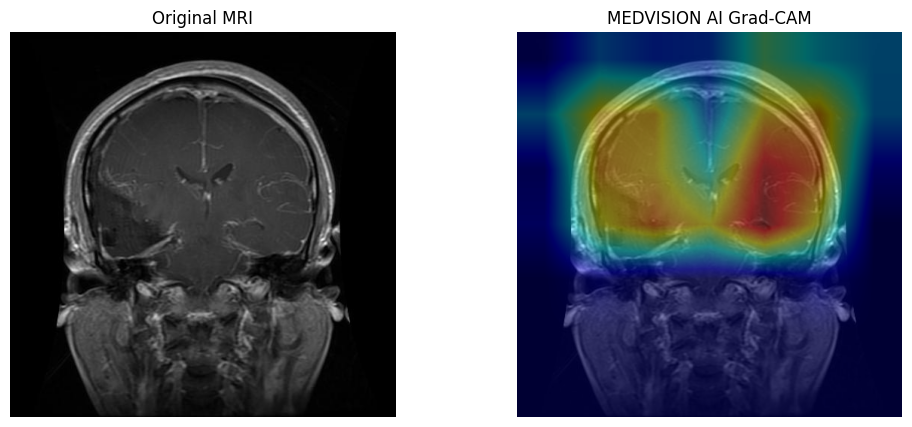

In [4]:
import tensorflow as tf
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from PIL import Image

# Load model
MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# Initialize Grad-CAM
base = model.get_layer("efficientnetb0")

feature_model = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer("top_conv").output,
        base.output
    ]
)

pooling = model.get_layer("global_average_pooling2d")
dropout1 = model.get_layer("dropout")
dense1 = model.get_layer("dense")
dropout2 = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")

def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = feature_model(image, training=False)
        x = pooling(features)
        x = dropout1(x, training=False)
        x = dense1(x)
        x = dropout2(x, training=False)
        predictions = classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM gradients unavailable")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# Test using a training MRI image
folder = "/content/medvision_dataset/Training/glioma"

files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

test_image = Image.open(
    os.path.join(folder, files[0])
).convert("RGB")

original = np.array(test_image)
resized = cv2.resize(original, (224, 224))

input_image = np.expand_dims(
    resized.astype("float32"), axis=0
)

heatmap, probabilities = make_gradcam(input_image)

prediction = CLASS_NAMES[np.argmax(probabilities)]

print("MODEL LOADED SUCCESSFULLY")
print("Predicted class:", prediction)
print("Confidence:", round(float(np.max(probabilities)) * 100, 2), "%")

heatmap = cv2.resize(
    heatmap, (original.shape[1], original.shape[0])
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap), cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    original, 0.6, heatmap_color, 0.4, 0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("MEDVISION AI Grad-CAM")
plt.axis("off")

plt.show()

In [5]:
import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
import os
from PIL import Image
from datetime import datetime

# LOAD MODEL
MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"
mv_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# GRAD-CAM SETUP
mv_base = mv_model.get_layer("efficientnetb0")

mv_feature_model = tf.keras.Model(
    inputs=mv_base.input,
    outputs=[
        mv_base.get_layer("top_conv").output,
        mv_base.output
    ]
)

mv_pool = mv_model.get_layer("global_average_pooling2d")
mv_drop1 = mv_model.get_layer("dropout")
mv_dense = mv_model.get_layer("dense")
mv_drop2 = mv_model.get_layer("dropout_1")
mv_classifier = mv_model.get_layer("dense_1")


def make_gradcam(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, features = mv_feature_model(image, training=False)

        x = mv_pool(features)
        x = mv_drop1(x, training=False)
        x = mv_dense(x)
        x = mv_drop2(x, training=False)
        predictions = mv_classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM gradient calculation failed.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# REPORT GENERATOR
def generate_report(prediction, confidence, probabilities):
    report = f"""
MEDVISION AI - MRI ANALYSIS REPORT

Date: {datetime.now().strftime("%d-%m-%Y %H:%M:%S")}

1. MODEL PREDICTION
Predicted Category: {prediction.upper()}
Model Confidence: {confidence:.2f}%

2. CLASS PROBABILITY DISTRIBUTION
"""

    for name, probability in zip(CLASS_NAMES, probabilities):
        report += f"\n{name.upper()}: {probability * 100:.2f}%"

    report += """

3. MODEL INFORMATION
Architecture: EfficientNetB0
Input Image Size: 224 x 224
Classification Classes: 4
Validation Accuracy: 90.99%
Validation Macro F1-Score: 90.98%

4. VISUAL EXPLANATION
Grad-CAM visualization highlights image regions
that influenced the model prediction.

5. IMPORTANT DISCLAIMER
This application is an academic AI research prototype.
It is not clinically validated and must not be used
for medical diagnosis or treatment decisions.
Predictions and confidence scores are not medical
conclusions. Consult a qualified radiologist.

Generated by MEDVISION AI
"""

    return report


# MRI ANALYSIS FUNCTION
def analyze_mri(image):
    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:
        if isinstance(image, Image.Image):
            original = image.convert("RGB")
        else:
            original = Image.fromarray(np.asarray(image)).convert("RGB")

        original_array = np.array(original)
        resized = cv2.resize(original_array, (224, 224))

        input_image = np.expand_dims(
            resized.astype(np.float32), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]
        confidence = float(probabilities[predicted_index] * 100)

        scores = {
            name: float(probability)
            for name, probability in zip(CLASS_NAMES, probabilities)
        }

        heatmap = cv2.resize(heatmap, (224, 224))
        heatmap = np.uint8(255 * heatmap)

        colored_heatmap = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            resized, 0.6, colored_heatmap, 0.4, 0
        )

        overlay = cv2.cvtColor(
            overlay, cv2.COLOR_BGR2RGB
        )

        report = generate_report(
            prediction, confidence, probabilities
        )

        return scores, overlay, report

    except Exception as e:
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# CREATE GRADIO APPLICATION
with gr.Blocks(title="MEDVISION AI") as mv_demo:

    gr.Markdown("""
    # MEDVISION AI
    ### AI-Powered Brain MRI Classification and Visualization

    Upload a brain MRI image to generate a research-model
    classification, Grad-CAM visualization, and analysis report.
    """)

    with gr.Row():

        with gr.Column():
            mv_input = gr.Image(
                label="Upload Brain MRI",
                type="pil"
            )

            mv_button = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():
            mv_prediction = gr.Label(
                label="Classification Results",
                num_top_classes=4
            )

            mv_gradcam = gr.Image(
                label="Grad-CAM Visualization"
            )

    mv_report = gr.Textbox(
        label="MRI Analysis Report",
        lines=18,
        interactive=False
    )

    mv_button.click(
        fn=analyze_mri,
        inputs=mv_input,
        outputs=[
            mv_prediction,
            mv_gradcam,
            mv_report
        ]
    )

    gr.Markdown("""
    **Disclaimer:** MEDVISION AI is an academic research prototype,
    not a clinically validated diagnostic system.
    """)

mv_demo.launch(share=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cdfc54955b65e06741.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [6]:
import os
import uuid
import cv2
import gradio as gr
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as RLImage,
    Table, TableStyle, PageBreak
)

# ==========================================
# 1. LOAD MODEL
# ==========================================

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

mv_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# ==========================================
# 2. GRAD-CAM INITIALIZATION
# ==========================================

mv_base = mv_model.get_layer("efficientnetb0")

mv_feature_model = tf.keras.Model(
    inputs=mv_base.input,
    outputs=[
        mv_base.get_layer("top_conv").output,
        mv_base.output
    ]
)

mv_pool = mv_model.get_layer("global_average_pooling2d")
mv_drop1 = mv_model.get_layer("dropout")
mv_dense = mv_model.get_layer("dense")
mv_drop2 = mv_model.get_layer("dropout_1")
mv_classifier = mv_model.get_layer("dense_1")


def make_gradcam(image):

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        conv_output, features = mv_feature_model(
            image, training=False
        )

        x = mv_pool(features)
        x = mv_drop1(x, training=False)
        x = mv_dense(x)
        x = mv_drop2(x, training=False)
        predictions = mv_classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM calculation failed.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(
        conv_output[0] * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# ==========================================
# 3. ANALYSIS REPORT
# ==========================================

def generate_report(prediction, confidence, probabilities, filename):

    report = f"""
MEDVISION AI - MRI ANALYSIS REPORT

Report ID: MV-{uuid.uuid4().hex[:8].upper()}
Date: {datetime.now().strftime("%d-%m-%Y %H:%M:%S")}
Image: {filename}

1. AI CLASSIFICATION RESULTS

Predicted Category: {prediction.upper()}
Model Confidence Score: {confidence:.2f}%

2. CLASS PROBABILITY DISTRIBUTION

"""

    for name, probability in zip(CLASS_NAMES, probabilities):
        report += f"{name.upper()}: {probability * 100:.2f}%\n"

    report += f"""

3. MODEL ARCHITECTURE

Model: EfficientNetB0
Learning Approach: Transfer Learning
Input Image Dimensions: 224 x 224
Input Channels: RGB
Classification Classes: 4
Output Activation: Softmax

4. MODEL EVALUATION

Validation Accuracy: 90.99%
Macro Precision: 91.13%
Macro Recall: 90.99%
Macro F1-Score: 90.98%
Weighted F1-Score: 90.98%

5. GRAD-CAM EXPLAINABILITY

Grad-CAM generates a heatmap highlighting image regions
that contributed to the model's predicted class.

The visualization represents model activation and does
not identify exact tumor boundaries or locations.

6. TECHNICAL METHODOLOGY

1. MRI image upload.
2. RGB image conversion.
3. Image resizing to 224 x 224.
4. Feature extraction using EfficientNetB0.
5. Classification into four categories.
6. Grad-CAM visualization generation.
7. Structured report generation.

7. RESEARCH LIMITATIONS

- Validation is based on an image-level group-aware split.
- Patient-level independent validation is not established.
- The dataset may not represent all clinical populations.
- Softmax confidence is not a calibrated probability.
- Grad-CAM is an approximate visual explanation.
- The model is not clinically validated.

8. MEDICAL DISCLAIMER

MEDVISION AI is an academic research prototype.
It is not intended for medical diagnosis or treatment.

The prediction must not replace professional medical
evaluation, radiological interpretation or clinical advice.

Generated by MEDVISION AI
"""

    return report


# ==========================================
# 4. MRI ANALYSIS
# ==========================================

def analyze_mri(image):

    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:

        original = image.convert("RGB")

        original_array = np.array(original)

        resized = cv2.resize(
            original_array, (224, 224)
        )

        input_image = np.expand_dims(
            resized.astype(np.float32), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))

        prediction = CLASS_NAMES[predicted_index]

        confidence = float(
            probabilities[predicted_index] * 100
        )

        scores = {
            name: float(probability)
            for name, probability in zip(
                CLASS_NAMES, probabilities
            )
        }

        heatmap = cv2.resize(heatmap, (224, 224))

        heatmap = np.uint8(255 * heatmap)

        colored_heatmap = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            resized, 0.6, colored_heatmap, 0.4, 0
        )

        overlay = cv2.cvtColor(
            overlay, cv2.COLOR_BGR2RGB
        )

        filename = getattr(image, "filename", None) or "Uploaded MRI"

        report = generate_report(
            prediction, confidence, probabilities, filename
        )

        result_data = {
            "original": original_array,
            "gradcam": overlay,
            "prediction": prediction,
            "confidence": confidence,
            "probabilities": probabilities.tolist(),
            "filename": filename,
            "report": report,
            "width": original.width,
            "height": original.height
        }

        return scores, overlay, report, result_data

    except Exception as e:
        raise gr.Error(f"Analysis failed: {str(e)}")


# ==========================================
# 5. PDF REPORT GENERATOR
# ==========================================

def generate_pdf(data):

    if data is None:
        raise gr.Error("Please analyze an MRI image first.")

    try:

        report_id = uuid.uuid4().hex[:8].upper()

        pdf_path = f"/content/MEDVISION_AI_Report_{report_id}.pdf"

        original_path = f"/content/mv_original_{report_id}.png"
        gradcam_path = f"/content/mv_gradcam_{report_id}.png"
        matrix_path = f"/content/mv_matrix_{report_id}.png"

        Image.fromarray(data["original"]).save(original_path)
        Image.fromarray(data["gradcam"]).save(gradcam_path)

        # CONFUSION MATRIX
        cm = np.array([
            [243, 35, 0, 3],
            [13, 235, 3, 29],
            [1, 2, 271, 6],
            [0, 8, 1, 271]
        ])

        fig, ax = plt.subplots(figsize=(6, 5))

        ax.imshow(cm, cmap="Blues")

        ax.set_xticks(range(4))
        ax.set_yticks(range(4))

        ax.set_xticklabels(CLASS_NAMES, rotation=25)
        ax.set_yticklabels(CLASS_NAMES)

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title("Validation Confusion Matrix")

        for i in range(4):
            for j in range(4):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center"
                )

        plt.tight_layout()
        plt.savefig(matrix_path, dpi=180)
        plt.close(fig)

        # PDF DOCUMENT
        doc = SimpleDocTemplate(
            pdf_path,
            pagesize=A4,
            rightMargin=45,
            leftMargin=45,
            topMargin=45,
            bottomMargin=45
        )

        styles = getSampleStyleSheet()

        title_style = ParagraphStyle(
            "MainTitle",
            parent=styles["Title"],
            alignment=TA_CENTER,
            textColor=colors.HexColor("#17365D"),
            fontSize=23,
            spaceAfter=12
        )

        heading_style = ParagraphStyle(
            "SectionHeading",
            parent=styles["Heading2"],
            textColor=colors.HexColor("#17365D"),
            spaceBefore=12,
            spaceAfter=8
        )

        normal_style = styles["BodyText"]

        story = []

        # PAGE 1: COVER AND CLASSIFICATION

        story.append(Spacer(1, 45))

        story.append(
            Paragraph("MEDVISION AI", title_style)
        )

        story.append(
            Paragraph(
                "Brain MRI Classification and Explainable AI Report",
                ParagraphStyle(
                    "subtitle",
                    parent=normal_style,
                    alignment=TA_CENTER,
                    fontSize=12
                )
            )
        )

        story.append(Spacer(1, 30))

        story.append(Paragraph("REPORT INFORMATION", heading_style))

        info = [
            ["Report ID", f"MV-{report_id}"],
            ["Generated On", datetime.now().strftime("%d-%m-%Y %H:%M:%S")],
            ["Image Filename", str(data["filename"])],
            ["Original Dimensions", f'{data["width"]} x {data["height"]}']
        ]

        table = Table(info, colWidths=[150, 300])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#DCE6F1")),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(Spacer(1, 20))

        story.append(
            Paragraph("AI CLASSIFICATION RESULTS", heading_style)
        )

        story.append(
            Paragraph(
                f'<b>Predicted Category:</b> {data["prediction"].upper()}',
                normal_style
            )
        )

        story.append(
            Paragraph(
                f'<b>Model Confidence:</b> {data["confidence"]:.2f}%',
                normal_style
            )
        )

        story.append(Spacer(1, 15))

        probability_table = [
            ["Class", "Model Score"]
        ]

        for name, probability in zip(
            CLASS_NAMES, data["probabilities"]
        ):
            probability_table.append([
                name.upper(),
                f"{probability * 100:.2f}%"
            ])

        table = Table(probability_table, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(PageBreak())

        # PAGE 2: MRI AND GRAD-CAM

        story.append(
            Paragraph("MRI IMAGE AND EXPLAINABILITY", title_style)
        )

        story.append(Spacer(1, 15))

        story.append(
            Paragraph("Original MRI Image", heading_style)
        )

        story.append(
            RLImage(original_path, width=4.5*inch, height=3.5*inch)
        )

        story.append(Spacer(1, 10))

        story.append(
            Paragraph("Grad-CAM Visualization", heading_style)
        )

        story.append(
            RLImage(gradcam_path, width=4.5*inch, height=3.5*inch)
        )

        story.append(Spacer(1, 12))

        story.append(
            Paragraph(
                "Grad-CAM highlights image regions contributing to "
                "the model prediction. It is an approximate explanation "
                "and does not represent a tumor segmentation or boundary.",
                normal_style
            )
        )

        story.append(PageBreak())

        # PAGE 3: MODEL PERFORMANCE

        story.append(
            Paragraph("MODEL PERFORMANCE EVALUATION", title_style)
        )

        story.append(Spacer(1, 15))

        metrics = [
            ["Evaluation Metric", "Validation Result"],
            ["Accuracy", "90.99%"],
            ["Macro Precision", "91.13%"],
            ["Macro Recall", "90.99%"],
            ["Macro F1-Score", "90.98%"],
            ["Weighted F1-Score", "90.98%"]
        ]

        table = Table(metrics, colWidths=[230, 210])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(
            Paragraph("CLASS-WISE PERFORMANCE", heading_style)
        )

        class_metrics = [
            ["Class", "Precision", "Recall", "F1", "Support"],
            ["Glioma", "94.92%", "86.48%", "90.50%", "281"],
            ["Meningioma", "83.04%", "83.93%", "83.48%", "280"],
            ["No Tumor", "97.13%", "96.79%", "96.96%", "280"],
            ["Pituitary", "89.44%", "96.79%", "92.97%", "280"]
        ]

        table = Table(
            class_metrics,
            colWidths=[100, 85, 85, 85, 65]
        )

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 7)
        ]))

        story.append(table)

        story.append(Spacer(1, 12))

        story.append(
            Paragraph("VALIDATION CONFUSION MATRIX", heading_style)
        )

        story.append(
            RLImage(matrix_path, width=4.8*inch, height=3.8*inch)
        )

        story.append(PageBreak())

        # PAGE 4: METHODOLOGY AND LIMITATIONS

        story.append(
            Paragraph("TECHNICAL METHODOLOGY", title_style)
        )

        sections = [
            ("Model Architecture",
             "EfficientNetB0 with ImageNet transfer learning, "
             "Global Average Pooling, Dense classification layers "
             "and Softmax output for four classes."),

            ("Image Preprocessing",
             "The uploaded image is converted into RGB format and "
             "resized to 224 x 224 pixels before model inference."),

            ("Classification Pipeline",
             "The model extracts image features and generates four "
             "class scores. The highest-scoring class is selected "
             "as the predicted category."),

            ("Explainable AI",
             "Gradient-weighted Class Activation Mapping (Grad-CAM) "
             "uses gradients and feature maps to create a heatmap "
             "representing influential image regions."),

            ("Dataset and Validation",
             "The validation set contains 1,121 images and uses a "
             "group-aware image split to keep identified original/"
             "augmented meningioma pairs together. This is not "
             "patient-level independent validation."),

            ("Research Limitations",
             "The model has not undergone clinical validation. "
             "Dataset representativeness, acquisition differences, "
             "image quality and possible misclassification may "
             "affect predictions. Softmax scores are not calibrated "
             "medical probabilities.")
        ]

        for heading, content in sections:

            story.append(
                Paragraph(heading, heading_style)
            )

            story.append(
                Paragraph(content, normal_style)
            )

            story.append(Spacer(1, 8))

        story.append(Spacer(1, 15))

        story.append(
            Paragraph("IMPORTANT MEDICAL DISCLAIMER", heading_style)
        )

        story.append(
            Paragraph(
                "MEDVISION AI is an academic AI research prototype. "
                "It is not a clinically validated diagnostic tool and "
                "must not be used to make medical or treatment decisions. "
                "All results require interpretation by qualified "
                "medical professionals.",
                normal_style
            )
        )

        story.append(Spacer(1, 20))

        story.append(
            Paragraph(
                "<b>Generated by MEDVISION AI</b>",
                ParagraphStyle(
                    "footer",
                    parent=normal_style,
                    alignment=TA_CENTER
                )
            )
        )

        doc.build(story)

        # CLEAN TEMPORARY IMAGE FILES
        for path in [original_path, gradcam_path, matrix_path]:
            if os.path.exists(path):
                os.remove(path)

        return pdf_path

    except Exception as e:
        raise gr.Error(f"PDF generation failed: {str(e)}")


# ==========================================
# 6. GRADIO USER INTERFACE
# ==========================================

with gr.Blocks(title="MEDVISION AI") as mv_demo:

    gr.Markdown("""
    # MEDVISION AI
    ### Brain MRI Classification and Explainable AI System

    Upload a brain MRI image to generate an AI classification,
    Grad-CAM visualization and detailed analysis report.
    """)

    mv_state = gr.State(None)

    with gr.Row():

        with gr.Column():

            mv_input = gr.Image(
                label="Upload Brain MRI",
                type="pil"
            )

            mv_analyze = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():

            mv_prediction = gr.Label(
                label="Classification Results",
                num_top_classes=4
            )

            mv_gradcam = gr.Image(
                label="Grad-CAM Visualization"
            )

    mv_report = gr.Textbox(
        label="Detailed MRI Analysis Report",
        lines=20,
        interactive=False
    )

    mv_analyze.click(
        fn=analyze_mri,
        inputs=mv_input,
        outputs=[
            mv_prediction,
            mv_gradcam,
            mv_report,
            mv_state
        ]
    )

    gr.Markdown("### Download Your Analysis")

    mv_pdf_button = gr.Button(
        "Generate & Download PDF Report",
        variant="primary"
    )

    mv_pdf_output = gr.File(
        label="Download MEDVISION AI Report"
    )

    mv_pdf_button.click(
        fn=generate_pdf,
        inputs=mv_state,
        outputs=mv_pdf_output
    )

    gr.Markdown("""
    **Disclaimer:** This is an academic research prototype,
    not a clinically validated diagnostic system.
    """)

mv_demo.launch(share=True, show_error=True)

ModuleNotFoundError: No module named 'reportlab'

In [7]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 9.0 MB/s  0:00:00


In [8]:
import os
import uuid
import cv2
import gradio as gr
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as RLImage,
    Table, TableStyle, PageBreak
)

# ==========================================
# 1. LOAD MODEL
# ==========================================

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

mv_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# ==========================================
# 2. GRAD-CAM INITIALIZATION
# ==========================================

mv_base = mv_model.get_layer("efficientnetb0")

mv_feature_model = tf.keras.Model(
    inputs=mv_base.input,
    outputs=[
        mv_base.get_layer("top_conv").output,
        mv_base.output
    ]
)

mv_pool = mv_model.get_layer("global_average_pooling2d")
mv_drop1 = mv_model.get_layer("dropout")
mv_dense = mv_model.get_layer("dense")
mv_drop2 = mv_model.get_layer("dropout_1")
mv_classifier = mv_model.get_layer("dense_1")


def make_gradcam(image):

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        conv_output, features = mv_feature_model(
            image, training=False
        )

        x = mv_pool(features)
        x = mv_drop1(x, training=False)
        x = mv_dense(x)
        x = mv_drop2(x, training=False)
        predictions = mv_classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM calculation failed.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(
        conv_output[0] * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# ==========================================
# 3. ANALYSIS REPORT
# ==========================================

def generate_report(prediction, confidence, probabilities, filename):

    report = f"""
MEDVISION AI - MRI ANALYSIS REPORT

Report ID: MV-{uuid.uuid4().hex[:8].upper()}
Date: {datetime.now().strftime("%d-%m-%Y %H:%M:%S")}
Image: {filename}

1. AI CLASSIFICATION RESULTS

Predicted Category: {prediction.upper()}
Model Confidence Score: {confidence:.2f}%

2. CLASS PROBABILITY DISTRIBUTION

"""

    for name, probability in zip(CLASS_NAMES, probabilities):
        report += f"{name.upper()}: {probability * 100:.2f}%\n"

    report += f"""

3. MODEL ARCHITECTURE

Model: EfficientNetB0
Learning Approach: Transfer Learning
Input Image Dimensions: 224 x 224
Input Channels: RGB
Classification Classes: 4
Output Activation: Softmax

4. MODEL EVALUATION

Validation Accuracy: 90.99%
Macro Precision: 91.13%
Macro Recall: 90.99%
Macro F1-Score: 90.98%
Weighted F1-Score: 90.98%

5. GRAD-CAM EXPLAINABILITY

Grad-CAM generates a heatmap highlighting image regions
that contributed to the model's predicted class.

The visualization represents model activation and does
not identify exact tumor boundaries or locations.

6. TECHNICAL METHODOLOGY

1. MRI image upload.
2. RGB image conversion.
3. Image resizing to 224 x 224.
4. Feature extraction using EfficientNetB0.
5. Classification into four categories.
6. Grad-CAM visualization generation.
7. Structured report generation.

7. RESEARCH LIMITATIONS

- Validation is based on an image-level group-aware split.
- Patient-level independent validation is not established.
- The dataset may not represent all clinical populations.
- Softmax confidence is not a calibrated probability.
- Grad-CAM is an approximate visual explanation.
- The model is not clinically validated.

8. MEDICAL DISCLAIMER

MEDVISION AI is an academic research prototype.
It is not intended for medical diagnosis or treatment.

The prediction must not replace professional medical
evaluation, radiological interpretation or clinical advice.

Generated by MEDVISION AI
"""

    return report


# ==========================================
# 4. MRI ANALYSIS
# ==========================================

def analyze_mri(image):

    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:

        original = image.convert("RGB")

        original_array = np.array(original)

        resized = cv2.resize(
            original_array, (224, 224)
        )

        input_image = np.expand_dims(
            resized.astype(np.float32), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))

        prediction = CLASS_NAMES[predicted_index]

        confidence = float(
            probabilities[predicted_index] * 100
        )

        scores = {
            name: float(probability)
            for name, probability in zip(
                CLASS_NAMES, probabilities
            )
        }

        heatmap = cv2.resize(heatmap, (224, 224))

        heatmap = np.uint8(255 * heatmap)

        colored_heatmap = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            resized, 0.6, colored_heatmap, 0.4, 0
        )

        overlay = cv2.cvtColor(
            overlay, cv2.COLOR_BGR2RGB
        )

        filename = getattr(image, "filename", None) or "Uploaded MRI"

        report = generate_report(
            prediction, confidence, probabilities, filename
        )

        result_data = {
            "original": original_array,
            "gradcam": overlay,
            "prediction": prediction,
            "confidence": confidence,
            "probabilities": probabilities.tolist(),
            "filename": filename,
            "report": report,
            "width": original.width,
            "height": original.height
        }

        return scores, overlay, report, result_data

    except Exception as e:
        raise gr.Error(f"Analysis failed: {str(e)}")


# ==========================================
# 5. PDF REPORT GENERATOR
# ==========================================

def generate_pdf(data):

    if data is None:
        raise gr.Error("Please analyze an MRI image first.")

    try:

        report_id = uuid.uuid4().hex[:8].upper()

        pdf_path = f"/content/MEDVISION_AI_Report_{report_id}.pdf"

        original_path = f"/content/mv_original_{report_id}.png"
        gradcam_path = f"/content/mv_gradcam_{report_id}.png"
        matrix_path = f"/content/mv_matrix_{report_id}.png"

        Image.fromarray(data["original"]).save(original_path)
        Image.fromarray(data["gradcam"]).save(gradcam_path)

        # CONFUSION MATRIX
        cm = np.array([
            [243, 35, 0, 3],
            [13, 235, 3, 29],
            [1, 2, 271, 6],
            [0, 8, 1, 271]
        ])

        fig, ax = plt.subplots(figsize=(6, 5))

        ax.imshow(cm, cmap="Blues")

        ax.set_xticks(range(4))
        ax.set_yticks(range(4))

        ax.set_xticklabels(CLASS_NAMES, rotation=25)
        ax.set_yticklabels(CLASS_NAMES)

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title("Validation Confusion Matrix")

        for i in range(4):
            for j in range(4):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center"
                )

        plt.tight_layout()
        plt.savefig(matrix_path, dpi=180)
        plt.close(fig)

        # PDF DOCUMENT
        doc = SimpleDocTemplate(
            pdf_path,
            pagesize=A4,
            rightMargin=45,
            leftMargin=45,
            topMargin=45,
            bottomMargin=45
        )

        styles = getSampleStyleSheet()

        title_style = ParagraphStyle(
            "MainTitle",
            parent=styles["Title"],
            alignment=TA_CENTER,
            textColor=colors.HexColor("#17365D"),
            fontSize=23,
            spaceAfter=12
        )

        heading_style = ParagraphStyle(
            "SectionHeading",
            parent=styles["Heading2"],
            textColor=colors.HexColor("#17365D"),
            spaceBefore=12,
            spaceAfter=8
        )

        normal_style = styles["BodyText"]

        story = []

        # PAGE 1: COVER AND CLASSIFICATION

        story.append(Spacer(1, 45))

        story.append(
            Paragraph("MEDVISION AI", title_style)
        )

        story.append(
            Paragraph(
                "Brain MRI Classification and Explainable AI Report",
                ParagraphStyle(
                    "subtitle",
                    parent=normal_style,
                    alignment=TA_CENTER,
                    fontSize=12
                )
            )
        )

        story.append(Spacer(1, 30))

        story.append(Paragraph("REPORT INFORMATION", heading_style))

        info = [
            ["Report ID", f"MV-{report_id}"],
            ["Generated On", datetime.now().strftime("%d-%m-%Y %H:%M:%S")],
            ["Image Filename", str(data["filename"])],
            ["Original Dimensions", f'{data["width"]} x {data["height"]}']
        ]

        table = Table(info, colWidths=[150, 300])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#DCE6F1")),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(Spacer(1, 20))

        story.append(
            Paragraph("AI CLASSIFICATION RESULTS", heading_style)
        )

        story.append(
            Paragraph(
                f'<b>Predicted Category:</b> {data["prediction"].upper()}',
                normal_style
            )
        )

        story.append(
            Paragraph(
                f'<b>Model Confidence:</b> {data["confidence"]:.2f}%',
                normal_style
            )
        )

        story.append(Spacer(1, 15))

        probability_table = [
            ["Class", "Model Score"]
        ]

        for name, probability in zip(
            CLASS_NAMES, data["probabilities"]
        ):
            probability_table.append([
                name.upper(),
                f"{probability * 100:.2f}%"
            ])

        table = Table(probability_table, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(PageBreak())

        # PAGE 2: MRI AND GRAD-CAM

        story.append(
            Paragraph("MRI IMAGE AND EXPLAINABILITY", title_style)
        )

        story.append(Spacer(1, 15))

        story.append(
            Paragraph("Original MRI Image", heading_style)
        )

        story.append(
            RLImage(original_path, width=4.5*inch, height=3.5*inch)
        )

        story.append(Spacer(1, 10))

        story.append(
            Paragraph("Grad-CAM Visualization", heading_style)
        )

        story.append(
            RLImage(gradcam_path, width=4.5*inch, height=3.5*inch)
        )

        story.append(Spacer(1, 12))

        story.append(
            Paragraph(
                "Grad-CAM highlights image regions contributing to "
                "the model prediction. It is an approximate explanation "
                "and does not represent a tumor segmentation or boundary.",
                normal_style
            )
        )

        story.append(PageBreak())

        # PAGE 3: MODEL PERFORMANCE

        story.append(
            Paragraph("MODEL PERFORMANCE EVALUATION", title_style)
        )

        story.append(Spacer(1, 15))

        metrics = [
            ["Evaluation Metric", "Validation Result"],
            ["Accuracy", "90.99%"],
            ["Macro Precision", "91.13%"],
            ["Macro Recall", "90.99%"],
            ["Macro F1-Score", "90.98%"],
            ["Weighted F1-Score", "90.98%"]
        ]

        table = Table(metrics, colWidths=[230, 210])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9)
        ]))

        story.append(table)

        story.append(
            Paragraph("CLASS-WISE PERFORMANCE", heading_style)
        )

        class_metrics = [
            ["Class", "Precision", "Recall", "F1", "Support"],
            ["Glioma", "94.92%", "86.48%", "90.50%", "281"],
            ["Meningioma", "83.04%", "83.93%", "83.48%", "280"],
            ["No Tumor", "97.13%", "96.79%", "96.96%", "280"],
            ["Pituitary", "89.44%", "96.79%", "92.97%", "280"]
        ]

        table = Table(
            class_metrics,
            colWidths=[100, 85, 85, 85, 65]
        )

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 7)
        ]))

        story.append(table)

        story.append(Spacer(1, 12))

        story.append(
            Paragraph("VALIDATION CONFUSION MATRIX", heading_style)
        )

        story.append(
            RLImage(matrix_path, width=4.8*inch, height=3.8*inch)
        )

        story.append(PageBreak())

        # PAGE 4: METHODOLOGY AND LIMITATIONS

        story.append(
            Paragraph("TECHNICAL METHODOLOGY", title_style)
        )

        sections = [
            ("Model Architecture",
             "EfficientNetB0 with ImageNet transfer learning, "
             "Global Average Pooling, Dense classification layers "
             "and Softmax output for four classes."),

            ("Image Preprocessing",
             "The uploaded image is converted into RGB format and "
             "resized to 224 x 224 pixels before model inference."),

            ("Classification Pipeline",
             "The model extracts image features and generates four "
             "class scores. The highest-scoring class is selected "
             "as the predicted category."),

            ("Explainable AI",
             "Gradient-weighted Class Activation Mapping (Grad-CAM) "
             "uses gradients and feature maps to create a heatmap "
             "representing influential image regions."),

            ("Dataset and Validation",
             "The validation set contains 1,121 images and uses a "
             "group-aware image split to keep identified original/"
             "augmented meningioma pairs together. This is not "
             "patient-level independent validation."),

            ("Research Limitations",
             "The model has not undergone clinical validation. "
             "Dataset representativeness, acquisition differences, "
             "image quality and possible misclassification may "
             "affect predictions. Softmax scores are not calibrated "
             "medical probabilities.")
        ]

        for heading, content in sections:

            story.append(
                Paragraph(heading, heading_style)
            )

            story.append(
                Paragraph(content, normal_style)
            )

            story.append(Spacer(1, 8))

        story.append(Spacer(1, 15))

        story.append(
            Paragraph("IMPORTANT MEDICAL DISCLAIMER", heading_style)
        )

        story.append(
            Paragraph(
                "MEDVISION AI is an academic AI research prototype. "
                "It is not a clinically validated diagnostic tool and "
                "must not be used to make medical or treatment decisions. "
                "All results require interpretation by qualified "
                "medical professionals.",
                normal_style
            )
        )

        story.append(Spacer(1, 20))

        story.append(
            Paragraph(
                "<b>Generated by MEDVISION AI</b>",
                ParagraphStyle(
                    "footer",
                    parent=normal_style,
                    alignment=TA_CENTER
                )
            )
        )

        doc.build(story)

        # CLEAN TEMPORARY IMAGE FILES
        for path in [original_path, gradcam_path, matrix_path]:
            if os.path.exists(path):
                os.remove(path)

        return pdf_path

    except Exception as e:
        raise gr.Error(f"PDF generation failed: {str(e)}")


# ==========================================
# 6. GRADIO USER INTERFACE
# ==========================================

with gr.Blocks(title="MEDVISION AI") as mv_demo:

    gr.Markdown("""
    # MEDVISION AI
    ### Brain MRI Classification and Explainable AI System

    Upload a brain MRI image to generate an AI classification,
    Grad-CAM visualization and detailed analysis report.
    """)

    mv_state = gr.State(None)

    with gr.Row():

        with gr.Column():

            mv_input = gr.Image(
                label="Upload Brain MRI",
                type="pil"
            )

            mv_analyze = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():

            mv_prediction = gr.Label(
                label="Classification Results",
                num_top_classes=4
            )

            mv_gradcam = gr.Image(
                label="Grad-CAM Visualization"
            )

    mv_report = gr.Textbox(
        label="Detailed MRI Analysis Report",
        lines=20,
        interactive=False
    )

    mv_analyze.click(
        fn=analyze_mri,
        inputs=mv_input,
        outputs=[
            mv_prediction,
            mv_gradcam,
            mv_report,
            mv_state
        ]
    )

    gr.Markdown("### Download Your Analysis")

    mv_pdf_button = gr.Button(
        "Generate & Download PDF Report",
        variant="primary"
    )

    mv_pdf_output = gr.File(
        label="Download MEDVISION AI Report"
    )

    mv_pdf_button.click(
        fn=generate_pdf,
        inputs=mv_state,
        outputs=mv_pdf_output
    )

    gr.Markdown("""
    **Disclaimer:** This is an academic research prototype,
    not a clinically validated diagnostic system.
    """)

mv_demo.launch(share=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f55b4e680d902d9624.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
import os
import uuid
import cv2
import gradio as gr
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image as RLImage, Table, TableStyle,
    PageBreak, Preformatted
)
from xml.sax.saxutils import escape

# ==========================================
# 1. LOAD EXISTING MODEL
# ==========================================

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

mv_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# ==========================================
# 2. EXISTING GRAD-CAM IMPLEMENTATION
# ==========================================

mv_base = mv_model.get_layer("efficientnetb0")

mv_feature_model = tf.keras.Model(
    inputs=mv_base.input,
    outputs=[
        mv_base.get_layer("top_conv").output,
        mv_base.output
    ]
)

mv_pool = mv_model.get_layer("global_average_pooling2d")
mv_drop1 = mv_model.get_layer("dropout")
mv_dense = mv_model.get_layer("dense")
mv_drop2 = mv_model.get_layer("dropout_1")
mv_classifier = mv_model.get_layer("dense_1")


def make_gradcam(image):

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        conv_output, features = mv_feature_model(
            image, training=False
        )

        x = mv_pool(features)
        x = mv_drop1(x, training=False)
        x = mv_dense(x)
        x = mv_drop2(x, training=False)
        predictions = mv_classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM calculation failed.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(
        conv_output[0] * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# ==========================================
# 3. CATEGORY-SPECIFIC MEDICAL KNOWLEDGE
# ==========================================

MEDICAL_INFO = {

    "glioma": {
        "anatomy": "Gliomas arise from glial cells, which support "
                   "nerve cells in the brain or spinal cord.",
        "conditions": "Gliomas include several tumor types with "
                      "different biological characteristics.",
        "causes": "Most gliomas have no clearly established individual "
                  "cause. Certain genetic changes and previous radiation "
                  "exposure are recognized risk factors.",
        "symptoms": "Depending on location, symptoms may include "
                    "headaches, seizures, weakness, speech difficulties "
                    "and changes in vision.",
        "evaluation": "Specialist assessment may include detailed MRI "
                      "sequences, neurological examination and, when "
                      "clinically indicated, tissue diagnosis."
    },

    "meningioma": {
        "anatomy": "Meningiomas originate from the meninges, the "
                   "membranes surrounding the brain and spinal cord.",
        "conditions": "Many meningiomas are slow-growing, but their "
                      "clinical behaviour varies.",
        "causes": "Most individual cases have no identifiable cause. "
                  "Recognized associations include certain genetic "
                  "conditions and previous radiation exposure.",
        "symptoms": "Possible symptoms include headaches, seizures, "
                    "visual changes and neurological difficulties, "
                    "depending on location and size.",
        "evaluation": "Assessment may involve contrast-enhanced MRI, "
                      "neurological examination and specialist review."
    },

    "notumor": {
        "anatomy": "This category represents images labelled as "
                   "notumor in the training dataset.",
        "conditions": "The model's no-tumor prediction does not establish "
                      "that the entire brain is free of abnormalities.",
        "causes": "A no-tumor classification does not identify or "
                  "exclude other possible causes of symptoms.",
        "symptoms": "Symptoms cannot be assessed from this classification "
                    "alone.",
        "evaluation": "If symptoms or clinical concerns exist, a "
                      "qualified radiologist should interpret the "
                      "complete MRI examination."
    },

    "pituitary": {
        "anatomy": "The pituitary gland is located at the base of the "
                   "brain within the sella turcica. It regulates several "
                   "important hormonal functions.",
        "conditions": "Pituitary-region abnormalities can include "
                      "pituitary adenomas, cysts and other sellar or "
                      "parasellar lesions.",
        "causes": "Pituitary adenomas arise from pituitary cells. "
                  "Most are sporadic, although some are associated "
                  "with inherited conditions. The cause of an "
                  "individual lesion cannot be established from this "
                  "classification.",
        "symptoms": "Possible associated symptoms include headaches, "
                    "visual disturbances, hormonal changes, menstrual "
                    "irregularities and unexplained weight changes.",
        "evaluation": "A specialist may consider dedicated pituitary "
                      "MRI sequences, hormonal blood tests and visual "
                      "field assessment, depending on clinical findings."
    }
}


# ==========================================
# 4. IMAGE ANALYSIS
# ==========================================

def analyze_image_quality(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))

    sharpness = float(
        cv2.Laplacian(gray, cv2.CV_64F).var()
    )

    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness,
        "minimum": int(np.min(gray)),
        "maximum": int(np.max(gray))
    }


# ==========================================
# 5. EXPANDED REPORT GENERATOR
# ==========================================

def generate_report(data):

    info = MEDICAL_INFO[data["prediction"]]

    probabilities = data["probabilities"]

    ranked = sorted(
        zip(CLASS_NAMES, probabilities),
        key=lambda x: x[1],
        reverse=True
    )

    margin = (
        ranked[0][1] - ranked[1][1]
    ) * 100

    quality = data["quality"]

    report = f"""
MEDVISION AI - EXTENDED MRI ANALYSIS REPORT

Report ID: {data["report_id"]}
Date: {data["date"]}
Image: {data["filename"]}

==================================================
1. AI CLASSIFICATION RESULTS
==================================================

Predicted Category: {data["prediction"].upper()}
Model Confidence Score: {data["confidence"]:.2f}%

The predicted category is the class with the highest
model output score. This is an AI classification result,
not a confirmed medical diagnosis.

==================================================
2. CLASS PROBABILITY DISTRIBUTION
==================================================

"""

    for name, probability in ranked:
        report += f"{name.upper()}: {probability * 100:.2f}%\n"

    report += f"""
Top Two Class Score Difference: {margin:.2f} percentage points.

Note: Softmax scores are not calibrated medical
probabilities and do not establish disease likelihood.

==================================================
3. MRI IMAGE INFORMATION
==================================================

Image Filename: {data["filename"]}
Image Format: {data["format"]}
Original Width: {data["width"]} pixels
Original Height: {data["height"]} pixels
Color Mode: RGB
Model Input Dimensions: 224 x 224 pixels

IMAGE QUALITY MEASUREMENTS

Mean Grayscale Intensity: {quality["brightness"]:.2f}
Grayscale Intensity Standard Deviation: {quality["contrast"]:.2f}
Laplacian Sharpness Variance: {quality["sharpness"]:.2f}
Minimum Pixel Intensity: {quality["minimum"]}
Maximum Pixel Intensity: {quality["maximum"]}

These measurements describe image pixel characteristics.
They are not measurements of tumor characteristics.

==================================================
4. IMAGE-BASED OBSERVATIONS
==================================================

The uploaded image has been converted to RGB format
and resized to 224 x 224 pixels for classification.

Brightness, contrast and sharpness measurements have
been calculated from the grayscale image.

These measurements describe technical image properties.
They do not establish abnormal tissue, tumor boundaries,
tumor size or anatomical location.

A single ordinary image may not contain enough information
to assess the complete brain anatomy.

==================================================
5. GRAD-CAM EXPLAINABILITY
==================================================

Grad-CAM uses gradients and feature maps from the
EfficientNetB0 model to highlight image regions that
contributed to the predicted classification.

Mean Grad-CAM Activation: {data["cam_mean"]:.4f}
Maximum Grad-CAM Activation: {data["cam_max"]:.4f}
Highlighted Activation Area: {data["cam_area"]:.2f}%

The highlighted activation area is an approximate
visualization statistic, not a tumor area measurement.

Grad-CAM does not identify exact tumor boundaries,
tumor dimensions or confirmed anatomical location.

==================================================
6. ANATOMICAL INFORMATION
==================================================

{info["anatomy"]}

==================================================
7. POSSIBLE CAUSES AND ASSOCIATED CONDITIONS
==================================================

{info["causes"]}

Additional Medical Context:

{info["conditions"]}

These are general medical explanations. The model cannot
establish the cause or biological nature of an abnormality
in the uploaded image.

==================================================
8. ASSOCIATED SYMPTOMS
==================================================

{info["symptoms"]}

Symptoms cannot be confirmed or excluded from MRI image
classification alone.

==================================================
9. CLINICAL SIGNIFICANCE AND FURTHER EVALUATION
==================================================

{info["evaluation"]}

Tumor dimensions, volume, grade and severity have not
been established by the current classification system.

==================================================
10. MODEL ARCHITECTURE
==================================================

Architecture: EfficientNetB0
Learning Approach: Transfer Learning
Input Dimensions: 224 x 224
Input Channels: RGB
Classification Classes: 4
Output Activation: Softmax

==================================================
11. MODEL EVALUATION
==================================================

Validation Accuracy: 90.99%
Macro Precision: 91.13%
Macro Recall: 90.99%
Macro F1-Score: 90.98%
Weighted F1-Score: 90.98%

==================================================
12. RESEARCH LIMITATIONS
==================================================

- Validation uses a group-aware image-level split.
- Patient-level independent validation is not established.
- Dataset representativeness is not guaranteed.
- Softmax scores are not calibrated probabilities.
- Grad-CAM is an approximate visual explanation.
- No tumor segmentation or physical measurements
  are performed.
- Causes and symptoms are general medical context.
- The system is not clinically validated.

==================================================
13. MEDICAL DISCLAIMER
==================================================

MEDVISION AI is an academic AI research prototype.

It is not intended for medical diagnosis or treatment.
Its classification must not replace professional
radiological interpretation or clinical evaluation.

Generated by MEDVISION AI
"""

    return report


# ==========================================
# 6. MRI ANALYSIS FUNCTION
# ==========================================

def analyze_mri(image):

    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:

        original = image.convert("RGB")
        original_array = np.array(original)

        resized = cv2.resize(
            original_array, (224, 224)
        )

        input_image = np.expand_dims(
            resized.astype(np.float32), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]

        confidence = float(
            probabilities[predicted_index] * 100
        )

        scores = {
            name: float(probability)
            for name, probability in zip(
                CLASS_NAMES, probabilities
            )
        }

        heatmap = cv2.resize(heatmap, (224, 224))
        heatmap = np.uint8(255 * heatmap)

        colored_heatmap = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            resized, 0.6, colored_heatmap, 0.4, 0
        )

        overlay = cv2.cvtColor(
            overlay, cv2.COLOR_BGR2RGB
        )

        # IMAGE QUALITY
        quality = analyze_image_quality(original_array)

        # GRAD-CAM STATISTICS
        normalized_heatmap = cv2.resize(
            cv2.resize(
                heatmap, (7, 7)
            ).astype(np.float32) / 255.0,
            (224, 224)
        )

        cam_mean = float(np.mean(normalized_heatmap))
        cam_max = float(np.max(normalized_heatmap))

        cam_area = float(
            np.mean(normalized_heatmap >= 0.5) * 100
        )

        # REPORT DATA
        report_id = uuid.uuid4().hex[:8].upper()

        filename = getattr(image, "filename", None) or "Uploaded MRI"

        result_data = {
            "report_id": report_id,
            "date": datetime.now().strftime("%d-%m-%Y %H:%M:%S"),
            "filename": filename,
            "format": original.format or "RGB image",
            "width": original.width,
            "height": original.height,
            "prediction": prediction,
            "confidence": confidence,
            "probabilities": probabilities.tolist(),
            "quality": quality,
            "cam_mean": cam_mean,
            "cam_max": cam_max,
            "cam_area": cam_area,
            "original": original_array,
            "gradcam": overlay
        }

        report = generate_report(result_data)

        return scores, overlay, report, result_data

    except Exception as e:
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# ==========================================
# 7. PDF REPORT GENERATOR
# ==========================================

def generate_pdf(data):

    if data is None:
        raise gr.Error("Please analyze an MRI image first.")

    try:

        report_id = data["report_id"]

        pdf_path = f"/content/MEDVISION_AI_Report_{report_id}.pdf"

        original_path = f"/content/mv_original_{report_id}.png"
        gradcam_path = f"/content/mv_gradcam_{report_id}.png"
        matrix_path = f"/content/mv_matrix_{report_id}.png"

        Image.fromarray(data["original"]).save(original_path)
        Image.fromarray(data["gradcam"]).save(gradcam_path)

        # EXISTING VALIDATION CONFUSION MATRIX
        cm = np.array([
            [243, 35, 0, 3],
            [13, 235, 3, 29],
            [1, 2, 271, 6],
            [0, 8, 1, 271]
        ])

        fig, ax = plt.subplots(figsize=(6, 5))

        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(CLASS_NAMES, rotation=25)
        ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title("Validation Confusion Matrix")

        for i in range(4):
            for j in range(4):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center"
                )

        plt.tight_layout()
        plt.savefig(matrix_path, dpi=180)
        plt.close(fig)

        # CREATE PDF
        doc = SimpleDocTemplate(
            pdf_path,
            pagesize=A4,
            rightMargin=45,
            leftMargin=45,
            topMargin=45,
            bottomMargin=45
        )

        styles = getSampleStyleSheet()

        title_style = ParagraphStyle(
            "MainTitle",
            parent=styles["Title"],
            alignment=TA_CENTER,
            textColor=colors.HexColor("#17365D"),
            fontSize=22,
            spaceAfter=12
        )

        heading_style = ParagraphStyle(
            "SectionHeading",
            parent=styles["Heading2"],
            textColor=colors.HexColor("#17365D"),
            spaceBefore=12,
            spaceAfter=8
        )

        story = []

        story.append(Paragraph("MEDVISION AI", title_style))

        story.append(Paragraph(
            "Extended Brain MRI Analysis Report",
            ParagraphStyle(
                "subtitle",
                parent=styles["Normal"],
                alignment=TA_CENTER,
                fontSize=12
            )
        ))

        story.append(Spacer(1, 20))

        story.append(Paragraph(
            "CLASSIFICATION RESULTS", heading_style
        ))

        story.append(Paragraph(
            f'<b>Predicted Category:</b> {escape(data["prediction"].upper())}',
            styles["BodyText"]
        ))

        story.append(Paragraph(
            f'<b>Model Confidence:</b> {data["confidence"]:.2f}%',
            styles["BodyText"]
        ))

        probability_table = [
            ["Class", "Model Score"]
        ]

        for name, probability in zip(
            CLASS_NAMES, data["probabilities"]
        ):
            probability_table.append([
                name.upper(),
                f"{probability * 100:.2f}%"
            ])

        table = Table(probability_table, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8)
        ]))

        story.append(table)
        story.append(Spacer(1, 15))

        # COMPLETE TEXT REPORT
        story.append(Paragraph(
            "DETAILED MRI ANALYSIS",
            heading_style
        ))

        report = generate_report(data)

        for line in report.splitlines():

            line = line.strip()

            if not line:
                story.append(Spacer(1, 4))

            elif line.startswith("="):
                continue

            elif line.isupper() and len(line) < 90:
                story.append(
                    Paragraph(escape(line), heading_style)
                )

            else:
                story.append(
                    Paragraph(
                        escape(line),
                        styles["BodyText"]
                    )
                )

            story.append(Spacer(1, 3))

        story.append(PageBreak())

        # ORIGINAL MRI
        story.append(Paragraph(
            "ORIGINAL MRI IMAGE",
            title_style
        ))

        story.append(RLImage(
            original_path,
            width=4.7*inch,
            height=3.8*inch,
            kind="proportional"
        ))

        story.append(Spacer(1, 15))

        # GRAD-CAM
        story.append(Paragraph(
            "GRAD-CAM VISUALIZATION",
            title_style
        ))

        story.append(RLImage(
            gradcam_path,
            width=4.7*inch,
            height=3.8*inch,
            kind="proportional"
        ))

        story.append(PageBreak())

        # VALIDATION EVALUATION
        story.append(Paragraph(
            "MODEL VALIDATION EVALUATION",
            title_style
        ))

        metrics = [
            ["Metric", "Validation Result"],
            ["Accuracy", "90.99%"],
            ["Macro Precision", "91.13%"],
            ["Macro Recall", "90.99%"],
            ["Macro F1-Score", "90.98%"],
            ["Weighted F1-Score", "90.98%"]
        ]

        table = Table(metrics, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8)
        ]))

        story.append(table)

        story.append(Spacer(1, 15))

        story.append(Paragraph(
            "CLASS-WISE PERFORMANCE",
            heading_style
        ))

        class_metrics = [
            ["Class", "Precision", "Recall", "F1", "Support"],
            ["Glioma", "94.92%", "86.48%", "90.50%", "281"],
            ["Meningioma", "83.04%", "83.93%", "83.48%", "280"],
            ["No Tumor", "97.13%", "96.79%", "96.96%", "280"],
            ["Pituitary", "89.44%", "96.79%", "92.97%", "280"]
        ]

        table = Table(
            class_metrics,
            colWidths=[100, 85, 85, 85, 65]
        )

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 7)
        ]))

        story.append(table)

        story.append(Spacer(1, 15))

        story.append(Paragraph(
            "VALIDATION CONFUSION MATRIX",
            heading_style
        ))

        story.append(RLImage(
            matrix_path,
            width=4.8*inch,
            height=3.8*inch
        ))

        story.append(Spacer(1, 15))

        story.append(Paragraph(
            "This evaluation describes the model's validation "
            "performance. It does not represent the accuracy "
            "of an individual MRI prediction.",
            styles["BodyText"]
        ))

        doc.build(story)

        for path in [
            original_path, gradcam_path, matrix_path
        ]:
            if os.path.exists(path):
                os.remove(path)

        return pdf_path

    except Exception as e:
        raise gr.Error(f"PDF generation failed: {str(e)}")


# ==========================================
# 8. EXISTING GRADIO INTERFACE
# ==========================================

with gr.Blocks(title="MEDVISION AI") as mv_demo:

    gr.Markdown("""
    # MEDVISION AI
    ### Brain MRI Classification and Explainable AI System

    Upload a brain MRI image to generate an AI classification,
    Grad-CAM visualization and detailed analysis report.
    """)

    mv_state = gr.State(None)

    with gr.Row():

        with gr.Column():

            mv_input = gr.Image(
                label="Upload Brain MRI",
                type="pil"
            )

            mv_analyze = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():

            mv_prediction = gr.Label(
                label="Classification Results",
                num_top_classes=4
            )

            mv_gradcam = gr.Image(
                label="Grad-CAM Visualization"
            )

    mv_report = gr.Textbox(
        label="Detailed MRI Analysis Report",
        lines=20,
        interactive=False
    )

    mv_analyze.click(
        fn=analyze_mri,
        inputs=mv_input,
        outputs=[
            mv_prediction,
            mv_gradcam,
            mv_report,
            mv_state
        ]
    )

    gr.Markdown("### Download Your Analysis")

    mv_pdf_button = gr.Button(
        "Generate & Download PDF Report",
        variant="primary"
    )

    mv_pdf_output = gr.File(
        label="Download MEDVISION AI Report"
    )

    mv_pdf_button.click(
        fn=generate_pdf,
        inputs=mv_state,
        outputs=mv_pdf_output
    )

    gr.Markdown("""
    **Disclaimer:** This is an academic research prototype,
    not a clinically validated diagnostic system.
    """)

mv_demo.launch(share=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58a3640750cd056c1d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
import os
import uuid
import cv2
import gradio as gr
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image as RLImage, Table, TableStyle, PageBreak
)
from xml.sax.saxutils import escape

# ==========================================
# 1. LOAD EXISTING MODEL
# ==========================================

MODEL_PATH = "/content/drive/MyDrive/MEDVISION_AI_FINAL_V2.keras"

mv_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]


# ==========================================
# 2. EXISTING GRAD-CAM
# ==========================================

mv_base = mv_model.get_layer("efficientnetb0")

mv_feature_model = tf.keras.Model(
    inputs=mv_base.input,
    outputs=[
        mv_base.get_layer("top_conv").output,
        mv_base.output
    ]
)

mv_pool = mv_model.get_layer("global_average_pooling2d")
mv_drop1 = mv_model.get_layer("dropout")
mv_dense = mv_model.get_layer("dense")
mv_drop2 = mv_model.get_layer("dropout_1")
mv_classifier = mv_model.get_layer("dense_1")


def make_gradcam(image):

    image = tf.convert_to_tensor(image, dtype=tf.float32)

    with tf.GradientTape() as tape:

        conv_output, features = mv_feature_model(
            image, training=False
        )

        x = mv_pool(features)
        x = mv_drop1(x, training=False)
        x = mv_dense(x)
        x = mv_drop2(x, training=False)

        predictions = mv_classifier(x)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    gradients = tape.gradient(loss, conv_output)

    if gradients is None:
        raise ValueError("Grad-CAM calculation failed.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(
        conv_output[0] * weights, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), predictions.numpy()[0]


# ==========================================
# 3. MEDICAL REASONING KNOWLEDGE BASE
# ==========================================

MEDICAL_INFO = {

    "glioma": {

        "anatomy":
        "Gliomas arise in glial cells, which provide structural "
        "and functional support to neurons in the brain or spinal cord.",

        "pathophysiology":
        "Gliomas develop through abnormal proliferation of glial-lineage "
        "cells. Their biological behaviour varies considerably according "
        "to molecular alterations, histological type and grade.",

        "causes":
        "Most gliomas have no identifiable individual cause. Genetic "
        "alterations within tumor cells are involved in their development. "
        "Recognized risk factors include previous ionizing radiation "
        "exposure. Some inherited cancer-predisposition syndromes are "
        "associated with increased risk.",

        "symptoms":
        "Depending on the affected brain region, manifestations may "
        "include persistent headaches, seizures, weakness, speech "
        "difficulties, visual disturbances, memory changes and "
        "neurological deficits.",

        "complications":
        "Depending on tumour type, grade and location, possible "
        "complications include cerebral edema, seizures, increased "
        "intracranial pressure and neurological impairment.",

        "differential":
        "Other intracranial abnormalities that may require consideration "
        "include metastases, primary CNS lymphoma, abscesses and other "
        "brain lesions. Imaging appearance alone may not reliably "
        "distinguish all these conditions.",

        "evaluation":
        "Specialist evaluation may include MRI with appropriate "
        "sequences and contrast, neurological examination, advanced "
        "imaging when indicated, and tissue diagnosis with molecular "
        "testing where clinically appropriate.",

        "prognosis":
        "Prognosis varies substantially with molecular subtype, "
        "histological grade, patient factors, location and response "
        "to treatment. A four-class image classifier cannot estimate "
        "individual prognosis."
    },

    "meningioma": {

        "anatomy":
        "Meningiomas originate from cells associated with the meninges, "
        "the protective membranes surrounding the brain and spinal cord.",

        "pathophysiology":
        "Meningiomas develop through abnormal proliferation of "
        "meningeal cells. Many grow slowly, although their growth "
        "rate and biological behaviour vary.",

        "causes":
        "Most cases do not have a clearly identifiable individual cause. "
        "Recognized associations include previous radiation exposure, "
        "certain genetic alterations and inherited conditions such "
        "as neurofibromatosis type 2.",

        "symptoms":
        "Symptoms depend on tumour size and location and may include "
        "headaches, seizures, visual disturbances, hearing changes, "
        "weakness or other neurological symptoms. Some meningiomas "
        "are discovered incidentally without symptoms.",

        "complications":
        "Depending on location and growth, possible complications "
        "include compression of adjacent brain tissue, cerebral edema, "
        "seizures and neurological dysfunction.",

        "differential":
        "Other lesions that may resemble meningiomas include dural "
        "metastases, solitary fibrous tumours and other extra-axial "
        "lesions. A specialist considers the full imaging appearance.",

        "evaluation":
        "Evaluation may involve MRI with contrast, neurological "
        "assessment and review of lesion location and growth over time. "
        "Histopathological examination may be required when treatment "
        "or surgery is undertaken.",

        "prognosis":
        "Prognosis depends on histological grade, tumour location, "
        "extent of removal, recurrence and other clinical factors. "
        "The current classifier cannot determine tumour grade "
        "or predict an individual outcome."
    },

    "notumor": {

        "anatomy":
        "The brain contains multiple anatomical structures including "
        "the cerebral hemispheres, cerebellum, brainstem and ventricular "
        "system.",

        "pathophysiology":
        "The no-tumor category represents images labelled as notumor "
        "in the training dataset. It is a classification category, "
        "not a comprehensive assessment of brain health.",

        "causes":
        "A no-tumor prediction does not identify the cause of any "
        "symptoms. Headaches and neurological symptoms may have "
        "many unrelated causes.",

        "symptoms":
        "Symptoms cannot be established or excluded through this "
        "classification. Clinical symptoms require independent "
        "history-taking and medical evaluation.",

        "complications":
        "The model's no-tumor classification does not rule out "
        "non-neoplastic abnormalities, subtle lesions or other "
        "neurological conditions.",

        "differential":
        "Other conditions that may require clinical assessment include "
        "vascular abnormalities, inflammatory conditions, infections, "
        "developmental abnormalities and non-tumour structural changes.",

        "evaluation":
        "If symptoms or clinical concerns persist, a qualified "
        "radiologist should interpret the complete MRI examination "
        "and recommend further evaluation where appropriate.",

        "prognosis":
        "A no-tumor model prediction cannot establish a person's "
        "overall neurological health or predict clinical outcome."
    },

    "pituitary": {

        "anatomy":
        "The pituitary gland is a small endocrine gland located at "
        "the base of the brain within the sella turcica. It is "
        "connected to the hypothalamus and regulates several "
        "important hormonal functions.",

        "pathophysiology":
        "Pituitary adenomas arise from pituitary cells and may "
        "produce excess hormones or cause hormonal deficiencies "
        "through compression of normal gland tissue. Their behaviour "
        "depends on cell type, hormone secretion, size and location.",

        "causes":
        "Most pituitary adenomas occur sporadically without an "
        "identifiable individual cause. Some are associated with "
        "inherited conditions, including multiple endocrine "
        "neoplasia type 1 and other familial syndromes. The "
        "individual cause cannot be established from this classifier.",

        "symptoms":
        "Possible manifestations include headaches, visual field "
        "disturbances, menstrual irregularities, galactorrhea, "
        "changes in libido, fatigue and symptoms associated with "
        "excessive or deficient hormone production. Symptoms "
        "vary according to the lesion and hormone profile.",

        "complications":
        "Depending on the lesion, possible complications include "
        "hormonal imbalance, compression of nearby structures "
        "such as the optic chiasm and, rarely, acute complications "
        "such as pituitary apoplexy.",

        "differential":
        "Pituitary-region abnormalities include adenomas, Rathke "
        "cleft cysts, craniopharyngiomas, hypophysitis and other "
        "sellar or parasellar lesions. Dedicated imaging and "
        "clinical assessment are needed to distinguish them.",

        "evaluation":
        "A specialist may consider dedicated pituitary MRI with "
        "appropriate sequences, hormonal investigations such as "
        "prolactin and pituitary-axis testing, and formal visual "
        "field assessment when clinically indicated.",

        "prognosis":
        "Prognosis varies according to lesion type, hormone "
        "secretion, size, extension, effects on surrounding "
        "structures and response to treatment. The current "
        "classifier cannot determine any of these individual "
        "prognostic factors."
    }
}


# ==========================================
# 4. IMAGE QUALITY ANALYSIS
# ==========================================

def analyze_image_quality(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))

    sharpness = float(
        cv2.Laplacian(gray, cv2.CV_64F).var()
    )

    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness,
        "minimum": int(np.min(gray)),
        "maximum": int(np.max(gray))
    }


# ==========================================
# 5. EXPANDED REPORT GENERATOR
# ==========================================

def generate_report(data):

    info = MEDICAL_INFO[data["prediction"]]

    ranked = sorted(
        zip(CLASS_NAMES, data["probabilities"]),
        key=lambda x: x[1],
        reverse=True
    )

    margin = (ranked[0][1] - ranked[1][1]) * 100

    quality = data["quality"]

    report = f"""
MEDVISION AI - COMPREHENSIVE MRI ANALYSIS REPORT

Report ID: {data["report_id"]}
Date: {data["date"]}
Image: {data["filename"]}

==================================================
1. AI CLASSIFICATION RESULTS
==================================================

Predicted Category: {data["prediction"].upper()}
Model Confidence Score: {data["confidence"]:.2f}%

The predicted category is the class with the highest
model output score. This is an AI classification result,
not a confirmed medical diagnosis.

==================================================
2. CLASS PROBABILITY DISTRIBUTION
==================================================

"""

    for name, probability in ranked:
        report += f"{name.upper()}: {probability * 100:.2f}%\n"

    report += f"""
Top Two Class Score Difference: {margin:.2f} percentage points.

Softmax scores are not calibrated medical probabilities.

==================================================
3. MRI IMAGE INFORMATION
==================================================

Filename: {data["filename"]}
Image Format: {data["format"]}
Original Dimensions: {data["width"]} x {data["height"]}
Color Mode: RGB
Model Input Dimensions: 224 x 224

Mean Grayscale Intensity: {quality["brightness"]:.2f}
Intensity Standard Deviation: {quality["contrast"]:.2f}
Laplacian Sharpness Variance: {quality["sharpness"]:.2f}
Minimum Pixel Intensity: {quality["minimum"]}
Maximum Pixel Intensity: {quality["maximum"]}

==================================================
4. IMAGE-BASED OBSERVATIONS
==================================================

The image has been converted into RGB format and
resized to 224 x 224 pixels for classification.

The measured brightness, contrast and sharpness
describe technical image characteristics.

These measurements cannot establish tumour boundaries,
dimensions, biological behaviour or anatomical location.

==================================================
5. GRAD-CAM EXPLAINABILITY
==================================================

Grad-CAM highlights image regions that contributed
to the predicted classification.

Mean Grad-CAM Activation: {data["cam_mean"]:.4f}
Maximum Grad-CAM Activation: {data["cam_max"]:.4f}
Highlighted Activation Area: {data["cam_area"]:.2f}%

The highlighted activation area is not a tumour
area measurement or segmentation result.

==================================================
6. ANATOMICAL INFORMATION
==================================================

{info["anatomy"]}

==================================================
7. PATHOPHYSIOLOGY
==================================================

{info["pathophysiology"]}

This is general medical background, not a biological
finding established from the uploaded image.

==================================================
8. POSSIBLE CAUSES AND RISK FACTORS
==================================================

{info["causes"]}

The current AI classifier cannot identify the cause
of an individual patient's condition.

==================================================
9. ASSOCIATED CLINICAL MANIFESTATIONS
==================================================

{info["symptoms"]}

Symptoms cannot be confirmed or excluded from
image classification alone.

==================================================
10. POTENTIAL COMPLICATIONS
==================================================

{info["complications"]}

These are possible complications associated with
relevant medical conditions, not complications
identified in the uploaded MRI.

==================================================
11. DIFFERENTIAL CONSIDERATIONS
==================================================

{info["differential"]}

These conditions are general differential considerations.
The model does not perform differential diagnosis.

==================================================
12. DIAGNOSTIC EVALUATION
==================================================

{info["evaluation"]}

==================================================
13. PROGNOSTIC CONSIDERATIONS
==================================================

{info["prognosis"]}

Individual prognosis cannot be estimated using
the current four-class image classification model.

==================================================
14. MODEL ARCHITECTURE
==================================================

Architecture: EfficientNetB0
Learning Approach: Transfer Learning
Input Dimensions: 224 x 224
Input Channels: RGB
Classification Classes: 4
Output Activation: Softmax

==================================================
15. MODEL EVALUATION
==================================================

Validation Accuracy: 90.99%
Macro Precision: 91.13%
Macro Recall: 90.99%
Macro F1-Score: 90.98%
Weighted F1-Score: 90.98%

==================================================
16. RESEARCH LIMITATIONS
==================================================

- Validation uses a group-aware image-level split.
- Patient-level independent validation is not established.
- Dataset representativeness is not guaranteed.
- Softmax scores are not calibrated probabilities.
- Grad-CAM is an approximate visual explanation.
- No tumour segmentation or physical measurements
  are performed.
- Clinical history and laboratory results are unavailable.
- Medical explanations are general knowledge.
- The system is not clinically validated.

==================================================
17. MEDICAL DISCLAIMER
==================================================

MEDVISION AI is an academic AI research prototype.

It is not intended for medical diagnosis or treatment.
Its classification must not replace professional
radiological interpretation or clinical evaluation.

Generated by MEDVISION AI
"""

    return report


# ==========================================
# 6. MRI ANALYSIS FUNCTION
# ==========================================

def analyze_mri(image):

    if image is None:
        raise gr.Error("Please upload an MRI image.")

    try:

        original = image.convert("RGB")
        original_array = np.array(original)

        resized = cv2.resize(original_array, (224, 224))

        input_image = np.expand_dims(
            resized.astype(np.float32), axis=0
        )

        heatmap, probabilities = make_gradcam(input_image)

        predicted_index = int(np.argmax(probabilities))
        prediction = CLASS_NAMES[predicted_index]

        confidence = float(
            probabilities[predicted_index] * 100
        )

        scores = {
            name: float(probability)
            for name, probability in zip(
                CLASS_NAMES, probabilities
            )
        }

        heatmap = cv2.resize(heatmap, (224, 224))
        heatmap = np.uint8(255 * heatmap)

        colored_heatmap = cv2.applyColorMap(
            heatmap, cv2.COLORMAP_JET
        )

        overlay = cv2.addWeighted(
            resized, 0.6, colored_heatmap, 0.4, 0
        )

        overlay = cv2.cvtColor(
            overlay, cv2.COLOR_BGR2RGB
        )

        quality = analyze_image_quality(original_array)

        normalized_heatmap = heatmap.astype(np.float32) / 255.0

        cam_mean = float(np.mean(normalized_heatmap))
        cam_max = float(np.max(normalized_heatmap))

        cam_area = float(
            np.mean(normalized_heatmap >= 0.5) * 100
        )

        report_id = uuid.uuid4().hex[:8].upper()

        filename = getattr(image, "filename", None) or "Uploaded MRI"

        result_data = {
            "report_id": report_id,
            "date": datetime.now().strftime("%d-%m-%Y %H:%M:%S"),
            "filename": filename,
            "format": original.format or "RGB image",
            "width": original.width,
            "height": original.height,
            "prediction": prediction,
            "confidence": confidence,
            "probabilities": probabilities.tolist(),
            "quality": quality,
            "cam_mean": cam_mean,
            "cam_max": cam_max,
            "cam_area": cam_area,
            "original": original_array,
            "gradcam": overlay
        }

        report = generate_report(result_data)

        return scores, overlay, report, result_data

    except Exception as e:
        raise gr.Error(f"MRI analysis failed: {str(e)}")


# ==========================================
# 7. PDF REPORT GENERATOR
# ==========================================

def generate_pdf(data):

    if data is None:
        raise gr.Error("Please analyze an MRI image first.")

    try:

        report_id = data["report_id"]

        pdf_path = f"/content/MEDVISION_AI_Report_{report_id}.pdf"

        original_path = f"/content/mv_original_{report_id}.png"
        gradcam_path = f"/content/mv_gradcam_{report_id}.png"
        matrix_path = f"/content/mv_matrix_{report_id}.png"

        Image.fromarray(data["original"]).save(original_path)
        Image.fromarray(data["gradcam"]).save(gradcam_path)

        cm = np.array([
            [243, 35, 0, 3],
            [13, 235, 3, 29],
            [1, 2, 271, 6],
            [0, 8, 1, 271]
        ])

        fig, ax = plt.subplots(figsize=(6, 5))

        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(CLASS_NAMES, rotation=25)
        ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title("Validation Confusion Matrix")

        for i in range(4):
            for j in range(4):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center")

        plt.tight_layout()
        plt.savefig(matrix_path, dpi=180)
        plt.close(fig)

        doc = SimpleDocTemplate(
            pdf_path,
            pagesize=A4,
            rightMargin=45,
            leftMargin=45,
            topMargin=45,
            bottomMargin=45
        )

        styles = getSampleStyleSheet()

        title_style = ParagraphStyle(
            "MainTitle",
            parent=styles["Title"],
            alignment=TA_CENTER,
            textColor=colors.HexColor("#17365D"),
            fontSize=21,
            spaceAfter=12
        )

        heading_style = ParagraphStyle(
            "SectionHeading",
            parent=styles["Heading2"],
            textColor=colors.HexColor("#17365D"),
            spaceBefore=10,
            spaceAfter=6
        )

        story = [
            Paragraph("MEDVISION AI", title_style),
            Paragraph(
                "Comprehensive Brain MRI Analysis Report",
                ParagraphStyle(
                    "subtitle",
                    parent=styles["Normal"],
                    alignment=TA_CENTER
                )
            ),
            Spacer(1, 20),
            Paragraph("CLASSIFICATION RESULTS", heading_style),
            Paragraph(
                f'<b>Predicted Category:</b> {escape(data["prediction"].upper())}',
                styles["BodyText"]
            ),
            Paragraph(
                f'<b>Model Confidence:</b> {data["confidence"]:.2f}%',
                styles["BodyText"]
            )
        ]

        probability_table = [["Class", "Model Score"]]

        for name, probability in zip(
            CLASS_NAMES, data["probabilities"]
        ):
            probability_table.append([
                name.upper(), f"{probability * 100:.2f}%"
            ])

        table = Table(probability_table, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8)
        ]))

        story.append(table)
        story.append(Spacer(1, 15))

        story.append(
            Paragraph("DETAILED MEDICAL REASONING", heading_style)
        )

        report = generate_report(data)

        for line in report.splitlines():

            line = line.strip()

            if not line:
                story.append(Spacer(1, 3))

            elif line.startswith("="):
                continue

            elif line.isupper() and len(line) < 100:
                story.append(
                    Paragraph(escape(line), heading_style)
                )

            else:
                story.append(
                    Paragraph(escape(line), styles["BodyText"])
                )

        story.append(PageBreak())

        story.append(
            Paragraph("ORIGINAL MRI IMAGE", title_style)
        )

        story.append(
            RLImage(original_path, width=4.7*inch, height=3.8*inch,
                    kind="proportional")
        )

        story.append(Spacer(1, 15))

        story.append(
            Paragraph("GRAD-CAM VISUALIZATION", title_style)
        )

        story.append(
            RLImage(gradcam_path, width=4.7*inch, height=3.8*inch,
                    kind="proportional")
        )

        story.append(PageBreak())

        story.append(
            Paragraph("MODEL VALIDATION EVALUATION", title_style)
        )

        metrics = [
            ["Metric", "Validation Result"],
            ["Accuracy", "90.99%"],
            ["Macro Precision", "91.13%"],
            ["Macro Recall", "90.99%"],
            ["Macro F1-Score", "90.98%"],
            ["Weighted F1-Score", "90.98%"]
        ]

        table = Table(metrics, colWidths=[220, 220])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8)
        ]))

        story.append(table)

        story.append(
            Paragraph("CLASS-WISE PERFORMANCE", heading_style)
        )

        class_metrics = [
            ["Class", "Precision", "Recall", "F1", "Support"],
            ["Glioma", "94.92%", "86.48%", "90.50%", "281"],
            ["Meningioma", "83.04%", "83.93%", "83.48%", "280"],
            ["No Tumor", "97.13%", "96.79%", "96.96%", "280"],
            ["Pituitary", "89.44%", "96.79%", "92.97%", "280"]
        ]

        table = Table(class_metrics, colWidths=[100, 85, 85, 85, 65])

        table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 7)
        ]))

        story.append(table)

        story.append(
            Paragraph("VALIDATION CONFUSION MATRIX", heading_style)
        )

        story.append(
            RLImage(matrix_path, width=4.8*inch, height=3.8*inch)
        )

        story.append(Spacer(1, 10))

        story.append(
            Paragraph(
                "The validation metrics describe the model-level "
                "evaluation and are not individual patient results.",
                styles["BodyText"]
            )
        )

        doc.build(story)

        for path in [original_path, gradcam_path, matrix_path]:
            if os.path.exists(path):
                os.remove(path)

        return pdf_path

    except Exception as e:
        raise gr.Error(f"PDF generation failed: {str(e)}")


# ==========================================
# 8. EXISTING GRADIO INTERFACE
# ==========================================

with gr.Blocks(title="MEDVISION AI") as mv_demo:

    gr.Markdown("""
    # MEDVISION AI
    ### Brain MRI Classification and Explainable AI System

    Upload a brain MRI image to generate an AI classification,
    Grad-CAM visualization and comprehensive medical analysis report.
    """)

    mv_state = gr.State(None)

    with gr.Row():

        with gr.Column():

            mv_input = gr.Image(
                label="Upload Brain MRI",
                type="pil"
            )

            mv_analyze = gr.Button(
                "Analyze MRI",
                variant="primary"
            )

        with gr.Column():

            mv_prediction = gr.Label(
                label="Classification Results",
                num_top_classes=4
            )

            mv_gradcam = gr.Image(
                label="Grad-CAM Visualization"
            )

    mv_report = gr.Textbox(
        label="Comprehensive MRI Analysis Report",
        lines=22,
        interactive=False
    )

    mv_analyze.click(
        fn=analyze_mri,
        inputs=mv_input,
        outputs=[
            mv_prediction,
            mv_gradcam,
            mv_report,
            mv_state
        ]
    )

    gr.Markdown("### Download Your Analysis")

    mv_pdf_button = gr.Button(
        "Generate & Download PDF Report",
        variant="primary"
    )

    mv_pdf_output = gr.File(
        label="Download MEDVISION AI Report"
    )

    mv_pdf_button.click(
        fn=generate_pdf,
        inputs=mv_state,
        outputs=mv_pdf_output
    )

    gr.Markdown("""
    **Disclaimer:** MEDVISION AI is an academic research prototype,
    not a clinically validated diagnostic system.
    """)

mv_demo.launch(share=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3acfd6576ca5e88edf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
